In [0]:
from pyspark.sql import functions as F

FILE_PATH = "/Volumes/my_file/my_schema/ecommerce_raw/ecommerce_customer_master_raw-1.csv"

df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(FILE_PATH)
)

display(df)

Customer_ID,Age,City,Gender,Category,Acquisition_Channel,Device,Orders_Last_12M,Avg_Order_Value,Website_Visits,Days_Since_Last_Order,Discount_Used,Support_Tickets,Email_Opened,Campaign_Group,Converted,Revenue,Churned,Delivery_Days,Returned,Rating
10001,56.0,Pune,Female,Fashion,Organic,Mobile,7,3672.71,13.0,57,1,1,1,B,1,25708.97,0,4,0,4.4
10002,46.0,Jaipur,Male,Beauty,Instagram,Desktop,6,1874.65,13.0,162,0,1,1,A,0,11247.9,0,5,0,5.0
10003,32.0,Lucknow,Female,Fashion,Google Ads,Mobile,3,5865.58,15.0,109,1,0,1,A,0,17596.74,1,6,0,3.7
10004,60.0,Pune,Female,Beauty,Organic,Desktop,7,2194.83,11.0,122,0,0,1,B,0,15363.81,0,5,0,4.3
10005,25.0,Chennai,Female,Home & Kitchen,Instagram,Tablet,5,4712.1,8.0,27,0,2,1,B,0,23560.5,0,4,1,4.4
10006,38.0,Hyderabad,Female,Home & Kitchen,Email,Desktop,6,2754.94,11.0,173,0,2,0,A,1,16529.64,0,1,0,5.0
10007,56.0,Mumbai,Male,Home & Kitchen,Instagram,Mobile,8,2845.25,14.0,25,0,1,1,B,0,22762.0,0,2,0,4.3
10008,36.0,Mumbai,Male,Home & Kitchen,Referral,Desktop,6,4632.27,10.0,127,1,0,0,A,0,27793.62,0,3,0,3.8
10009,40.0,Kolkata,Male,Home & Kitchen,Organic,Mobile,6,3919.45,9.0,27,0,0,0,B,1,23516.7,0,6,0,4.3
10010,28.0,Chennai,Female,Sports,Email,Mobile,5,4454.81,16.0,133,0,0,1,A,0,22274.05,0,7,1,3.4


In [0]:
print("Rows:", df.count())
print("Columns:", len(df.columns))

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
df.printSchema()

display(df.limit(10))

---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
File <command-7675762487682144>, line 1
----> 1 print("Rows:", df.count())
      2 print("Columns:", len(df.columns))
      4 print("\nColumn Names:")

NameError: name 'df' is not defined

In [0]:
# Data Quality Check

from pyspark.sql import functions as F

print("Total Rows:", df.count())
print("Total Columns:", len(df.columns))

# Missing values
missing_df = df.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in df.columns
])

print("Missing Values:")
display(missing_df)

# Duplicate Customer IDs
duplicate_count = (
    df.groupBy("Customer_ID")
      .count()
      .filter(F.col("count") > 1)
      .count()
)

print("Duplicate Customer IDs:", duplicate_count)

# Converted distribution
print("Converted Distribution:")
display(
    df.groupBy("Converted")
      .count()
      .orderBy("Converted")
)

# Churned distribution
print("Churned Distribution:")
display(
    df.groupBy("Churned")
      .count()
      .orderBy("Churned")
)

# Numerical summary
display(
    df.select(
        "Age",
        "Orders_Last_12M",
        "Avg_Order_Value",
        "Website_Visits",
        "Days_Since_Last_Order",
        "Discount_Used",
        "Support_Tickets",
        "Email_Opened",
        "Revenue",
        "Delivery_Days",
        "Rating"
    ).summary()
)

Total Rows: 15120
Total Columns: 21
Missing Values:


Customer_ID,Age,City,Gender,Category,Acquisition_Channel,Device,Orders_Last_12M,Avg_Order_Value,Website_Visits,Days_Since_Last_Order,Discount_Used,Support_Tickets,Email_Opened,Campaign_Group,Converted,Revenue,Churned,Delivery_Days,Returned,Rating
0,226,226,0,0,0,0,0,229,226,0,0,0,0,0,0,0,0,0,0,0


Duplicate Customer IDs: 120
Converted Distribution:


Converted,count
0,13489
1,1631


Churned Distribution:


Churned,count
0,13498
1,1622


summary,Age,Orders_Last_12M,Avg_Order_Value,Website_Visits,Days_Since_Last_Order,Discount_Used,Support_Tickets,Email_Opened,Revenue,Delivery_Days,Rating
count,14894,15120,14891,14894,15120,15120,15120,15120,15120,15120,15120
mean,38.94272861554989,4.992592592592593,3903.627388355372,10.988317443265744,90.50376984126984,0.580952380952381,1.197089947089947,0.6488095238095238,19472.83526587305,4.5192460317460315,4.069451058201071
stddev,12.281710170857592,2.0014408853272467,1798.8353629423023,3.1588781545885514,52.13426383909136,0.4934195112235697,1.1057179001529742,0.4773581427434247,12420.693141176242,1.7869232613715358,0.6388827267605681
min,18.0,1,463.5,1.0,1,0,0,0,665.82,1,1.3
25%,29.0,4,2584.03,9.0,45,0,0,0,10680.68,3,3.6
50%,39.0,5,3605.41,11.0,90,1,1,1,16654.5,4,4.1
75%,50.0,6,4896.15,13.0,136,1,2,1,25055.6,6,4.6
max,60.0,17,16225.58,24.0,180,1,10,1,108894.61,11,5.0


In [0]:
# ==============================
# DATA CLEANING
# ==============================

from pyspark.sql import functions as F

# 1. Remove duplicate Customer IDs
df_clean = df.dropDuplicates(["Customer_ID"])

print("Rows after removing duplicate Customer IDs:", df_clean.count())

# 2. Fill missing numeric values with median
numeric_cols = [
    "Age",
    "Orders_Last_12M",
    "Avg_Order_Value",
    "Website_Visits",
    "Days_Since_Last_Order",
    "Discount_Used",
    "Support_Tickets",
    "Email_Opened",
    "Revenue",
    "Delivery_Days",
    "Rating"
]

for col_name in numeric_cols:
    if col_name in df_clean.columns:
        median_value = df_clean.approxQuantile(
            col_name, [0.5], 0.01
        )[0]

        df_clean = df_clean.fillna(
            {col_name: median_value}
        )

# 3. Fill missing categorical values with "Unknown"
categorical_cols = [
    "City",
    "Gender",
    "Category",
    "Acquisition_Channel",
    "Device",
    "Campaign_Group"
]

df_clean = df_clean.fillna(
    {col_name: "Unknown" for col_name in categorical_cols
     if col_name in df_clean.columns}
)

# 4. Check remaining missing values
missing_after = df_clean.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in df_clean.columns
])

print("Missing values after cleaning:")
display(missing_after)

# 5. Show cleaned data
display(df_clean.limit(10))

Rows after removing duplicate Customer IDs: 15000
Missing values after cleaning:


Customer_ID,Age,City,Gender,Category,Acquisition_Channel,Device,Orders_Last_12M,Avg_Order_Value,Website_Visits,Days_Since_Last_Order,Discount_Used,Support_Tickets,Email_Opened,Campaign_Group,Converted,Revenue,Churned,Delivery_Days,Returned,Rating
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Customer_ID,Age,City,Gender,Category,Acquisition_Channel,Device,Orders_Last_12M,Avg_Order_Value,Website_Visits,Days_Since_Last_Order,Discount_Used,Support_Tickets,Email_Opened,Campaign_Group,Converted,Revenue,Churned,Delivery_Days,Returned,Rating
10002,46.0,Jaipur,Male,Beauty,Instagram,Desktop,6,1874.65,13.0,162,0,1,1,A,0,11247.9,0,5,0,5.0
10022,19.0,Kolkata,Female,Beauty,Organic,Mobile,5,2139.16,9.0,106,1,3,1,B,0,10695.8,0,4,0,4.2
10045,19.0,Bangalore,Male,Home & Kitchen,Referral,Desktop,5,4747.98,11.0,101,0,0,1,A,0,23739.9,0,6,0,4.6
10060,46.0,Lucknow,Male,Books,Google Ads,Mobile,4,6488.62,7.0,136,0,1,0,A,0,25954.48,1,6,0,3.1
10091,34.0,Hyderabad,Male,Fashion,Organic,Mobile,4,3047.28,13.0,143,1,0,1,A,0,12189.12,0,5,0,4.7
10103,25.0,Mumbai,Male,Sports,Google Ads,Mobile,7,2270.02,10.0,44,0,0,1,A,0,15890.14,0,4,0,5.0
10158,42.0,Ahmedabad,Female,Books,Referral,Mobile,5,3096.04,13.0,24,1,2,0,A,0,15480.2,0,6,0,3.5
10192,50.0,Delhi,Female,Home & Kitchen,Google Ads,Desktop,6,2743.26,7.0,177,0,1,0,A,0,16459.56,1,5,0,4.7
10197,49.0,Jaipur,Female,Fashion,Organic,Desktop,6,3147.84,19.0,166,1,1,1,A,0,18887.04,0,7,0,2.5
10258,50.0,Delhi,Male,Beauty,Referral,Desktop,4,4806.13,12.0,136,1,0,0,A,0,19224.52,0,5,0,4.1


In [0]:
# ==============================
# EXPLORATORY DATA ANALYSIS
# ==============================

# 1. Conversion by Acquisition Channel
print("Conversion by Acquisition Channel")
display(
    df_clean.groupBy("Acquisition_Channel")
    .agg(
        F.count("*").alias("Customers"),
        F.sum("Converted").alias("Conversions"),
        F.round(F.avg("Converted") * 100, 2).alias("Conversion_Rate_Percent")
    )
    .orderBy(F.desc("Conversion_Rate_Percent"))
)

# 2. Conversion by Category
print("Conversion by Category")
display(
    df_clean.groupBy("Category")
    .agg(
        F.count("*").alias("Customers"),
        F.sum("Converted").alias("Conversions"),
        F.round(F.avg("Converted") * 100, 2).alias("Conversion_Rate_Percent")
    )
    .orderBy(F.desc("Conversion_Rate_Percent"))
)

# 3. Conversion by Device
print("Conversion by Device")
display(
    df_clean.groupBy("Device")
    .agg(
        F.count("*").alias("Customers"),
        F.sum("Converted").alias("Conversions"),
        F.round(F.avg("Converted") * 100, 2).alias("Conversion_Rate_Percent")
    )
    .orderBy(F.desc("Conversion_Rate_Percent"))
)

# 4. Revenue by Category
print("Revenue by Category")
display(
    df_clean.groupBy("Category")
    .agg(
        F.round(F.sum("Revenue"), 2).alias("Total_Revenue"),
        F.round(F.avg("Revenue"), 2).alias("Average_Revenue"),
        F.count("*").alias("Customers")
    )
    .orderBy(F.desc("Total_Revenue"))
)

# 5. Customer behavior summary
print("Customer Behavior Summary")
display(
    df_clean.select(
        F.round(F.avg("Age"), 2).alias("Avg_Age"),
        F.round(F.avg("Orders_Last_12M"), 2).alias("Avg_Orders"),
        F.round(F.avg("Avg_Order_Value"), 2).alias("Avg_Order_Value"),
        F.round(F.avg("Website_Visits"), 2).alias("Avg_Website_Visits"),
        F.round(F.avg("Days_Since_Last_Order"), 2).alias("Avg_Days_Since_Order"),
        F.round(F.avg("Revenue"), 2).alias("Avg_Revenue"),
        F.round(F.avg("Rating"), 2).alias("Avg_Rating")
    )
)

Conversion by Acquisition Channel


Acquisition_Channel,Customers,Conversions,Conversion_Rate_Percent
Referral,2253,271,12.03
Instagram,3022,347,11.48
Email,2216,238,10.74
Google Ads,3290,341,10.36
Organic,4219,424,10.05


Conversion by Category


Category,Customers,Conversions,Conversion_Rate_Percent
Fashion,2557,288,11.26
Sports,2444,274,11.21
Home & Kitchen,2465,275,11.16
Books,2506,276,11.01
Electronics,2472,263,10.64
Beauty,2556,245,9.59


Conversion by Device


Device,Customers,Conversions,Conversion_Rate_Percent
Desktop,4620,505,10.93
Mobile,9246,1005,10.87
Tablet,1134,111,9.79


Revenue by Category


Category,Total_Revenue,Average_Revenue,Customers
Beauty,4.993771411E7,19537.45,2556
Fashion,4.974931073E7,19456.12,2557
Books,4.948678207E7,19747.32,2506
Electronics,4.787788724E7,19368.08,2472
Sports,4.770777186E7,19520.36,2444
Home & Kitchen,4.733536934E7,19202.99,2465


Customer Behavior Summary


Avg_Age,Avg_Orders,Avg_Order_Value,Avg_Website_Visits,Avg_Days_Since_Order,Avg_Revenue,Avg_Rating
38.94,4.99,3899.62,10.99,90.47,19472.99,4.07


In [0]:
# ============================================
# STEP: ML DATA PREPARATION
# ============================================

from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml import Pipeline

# Target column
TARGET = "Converted"

# Columns
categorical_cols = [
    "City",
    "Gender",
    "Category",
    "Acquisition_Channel",
    "Device",
    "Campaign_Group"
]

numeric_cols = [
    "Age",
    "Orders_Last_12M",
    "Avg_Order_Value",
    "Website_Visits",
    "Days_Since_Last_Order",
    "Discount_Used",
    "Support_Tickets",
    "Email_Opened",
    "Revenue",
    "Churned",
    "Delivery_Days",
    "Returned",
    "Rating"
]

# Remove rows where target is missing
ml_df = df_clean.filter(F.col(TARGET).isNotNull())

# Convert target to double
ml_df = ml_df.withColumn(
    TARGET,
    F.col(TARGET).cast("double")
)

# Index categorical columns
indexers = [
    StringIndexer(
        inputCol=col,
        outputCol=col + "_index",
        handleInvalid="keep"
    )
    for col in categorical_cols
]

# One-hot encode categorical columns
encoders = [
    OneHotEncoder(
        inputCol=col + "_index",
        outputCol=col + "_encoded"
    )
    for col in categorical_cols
]

# Assemble all features
feature_cols = numeric_cols + [
    col + "_encoded" for col in categorical_cols
]

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features",
    handleInvalid="keep"
)

# Create pipeline
preprocessing_pipeline = Pipeline(
    stages=indexers + encoders + [assembler]
)

# Fit preprocessing
preprocessing_model = preprocessing_pipeline.fit(ml_df)

# Transform data
ml_ready = preprocessing_model.transform(ml_df)

# Select final ML columns
final_df = ml_ready.select(
    "features",
    F.col(TARGET).alias("label")
)

# Train-test split
train_df, test_df = final_df.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("ML preparation completed successfully!")
print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

display(train_df.limit(10))

ML preparation completed successfully!
Training rows: 12058
Testing rows: 2942


features,label
"{""type"":""0"",""size"":""42"",""indices"":[""0"",""1"",""2"",""3"",""4"",""5"",""6"",""7"",""8"",""9"",""10"",""11"",""12"",""13"",""24"",""26"",""32"",""37"",""40""],""values"":[""34.0"",""4.0"",""1328.01"",""7.0"",""137.0"",""1.0"",""1.0"",""1.0"",""5312.04"",""1.0"",""5.0"",""1.0"",""4.3"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0""]}",0.0
"{""type"":""0"",""size"":""42"",""indices"":[""0"",""1"",""2"",""3"",""4"",""5"",""6"",""7"",""8"",""9"",""10"",""11"",""12"",""13"",""24"",""26"",""32"",""37"",""41""],""values"":[""59.0"",""2.0"",""5052.55"",""11.0"",""178.0"",""1.0"",""2.0"",""1.0"",""10105.1"",""1.0"",""1.0"",""1.0"",""2.8"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0""]}",0.0
"{""type"":""0"",""size"":""42"",""indices"":[""0"",""1"",""2"",""3"",""4"",""5"",""6"",""7"",""8"",""9"",""10"",""11"",""12"",""13"",""24"",""31"",""33"",""37"",""40""],""values"":[""38.0"",""8.0"",""2773.19"",""8.0"",""101.0"",""1.0"",""2.0"",""1.0"",""22185.52"",""1.0"",""5.0"",""1.0"",""3.9"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0""]}",0.0
"{""type"":""0"",""size"":""42"",""indices"":[""0"",""1"",""2"",""3"",""4"",""5"",""6"",""7"",""8"",""9"",""10"",""11"",""12"",""14"",""24"",""26"",""34"",""37"",""41""],""values"":[""24.0"",""4.0"",""3841.37"",""7.0"",""168.0"",""1.0"",""2.0"",""1.0"",""15365.48"",""1.0"",""4.0"",""1.0"",""3.8"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0""]}",0.0
"{""type"":""0"",""size"":""42"",""indices"":[""0"",""1"",""2"",""3"",""4"",""5"",""6"",""7"",""8"",""9"",""10"",""11"",""12"",""14"",""24"",""29"",""33"",""37"",""40""],""values"":[""50.0"",""6.0"",""3865.03"",""8.0"",""124.0"",""1.0"",""2.0"",""1.0"",""23190.18"",""1.0"",""3.0"",""1.0"",""4.9"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0""]}",0.0
"{""type"":""0"",""size"":""42"",""indices"":[""0"",""1"",""2"",""3"",""4"",""5"",""6"",""7"",""8"",""9"",""10"",""11"",""12"",""14"",""25"",""28"",""36"",""37"",""41""],""values"":[""31.0"",""2.0"",""4073.3"",""19.0"",""18.0"",""1.0"",""3.0"",""1.0"",""8146.6"",""1.0"",""8.0"",""1.0"",""4.0"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0""]}",0.0
"{""type"":""0"",""size"":""42"",""indices"":[""0"",""1"",""2"",""3"",""4"",""5"",""6"",""7"",""8"",""9"",""10"",""11"",""12"",""15"",""24"",""27"",""34"",""38"",""40""],""values"":[""52.0"",""5.0"",""7385.04"",""6.0"",""42.0"",""1.0"",""4.0"",""1.0"",""36925.2"",""1.0"",""7.0"",""1.0"",""5.0"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0""]}",0.0
"{""type"":""0"",""size"":""42"",""indices"":[""0"",""1"",""2"",""3"",""4"",""5"",""6"",""7"",""8"",""9"",""10"",""11"",""12"",""15"",""24"",""29"",""33"",""38"",""40""],""values"":[""36.0"",""6.0"",""3927.47"",""9.0"",""157.0"",""1.0"",""1.0"",""1.0"",""23564.82"",""1.0"",""5.0"",""1.0"",""4.1"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0""]}",1.0
"{""type"":""0"",""size"":""42"",""indices"":[""0"",""1"",""2"",""3"",""4"",""5"",""6"",""7"",""8"",""9"",""10"",""11"",""12"",""15"",""25"",""26"",""33"",""37"",""40""],""values"":[""29.0"",""4.0"",""6884.8"",""11.0"",""154.0"",""1.0"",""4.0"",""1.0"",""27539.2"",""1.0"",""2.0"",""1.0"",""3.0"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0""]}",0.0
"{""type"":""0"",""size"":""42"",""indices"":[""0"",""1"",""2"",""3"",""4"",""5"",""6"",""7"",""8"",""9"",""10"",""11"",""12"",""16"",""24"",""28"",""34"",""38"",""40""],""values"":[""40.0"",""5.0"",""2096.86"",""14.0"",""37.0"",""1.0"",""2.0"",""1.0"",""10484.3"",""1.0"",""4.0"",""1.0"",""3.4"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0"",""1.0""]}",0.0


In [0]:
# ============================================
# STEP: LOGISTIC REGRESSION MODEL
# ============================================

from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# Create Logistic Regression model
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=100
)

# Train model
lr_model = lr.fit(train_df)

# Make predictions
lr_predictions = lr_model.transform(test_df)

# Show predictions
display(
    lr_predictions.select(
        "label",
        "prediction",
        "probability"
    ).limit(10)
)

# Evaluate ROC-AUC
evaluator = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

lr_auc = evaluator.evaluate(lr_predictions)

print("Logistic Regression ROC-AUC:", round(lr_auc, 4))

label,prediction,probability
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8269468256298274"",""0.17305317437017265""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8656285739758017"",""0.13437142602419827""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8627113673617387"",""0.1372886326382613""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8727411696082263"",""0.12725883039177366""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8881666904287043"",""0.11183330957129567""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8441461712455866"",""0.15585382875441345""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.866563735207076"",""0.13343626479292403""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8876982210940025"",""0.11230177890599746""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8905566342938075"",""0.10944336570619251""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8651919964323541"",""0.13480800356764588""]}"


Logistic Regression ROC-AUC: 0.5366


In [0]:
# ============================================
# STEP: RANDOM FOREST MODEL
# ============================================

from pyspark.ml.classification import RandomForestClassifier

# Create Random Forest model
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    numTrees=100,
    maxDepth=8,
    seed=42
)

# Train model
rf_model = rf.fit(train_df)

# Make predictions
rf_predictions = rf_model.transform(test_df)

# Show predictions
display(
    rf_predictions.select(
        "label",
        "prediction",
        "probability"
    ).limit(10)
)

# Evaluate ROC-AUC
rf_auc = evaluator.evaluate(rf_predictions)

print("Random Forest ROC-AUC:", round(rf_auc, 4))

label,prediction,probability
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8801909457378148"",""0.11980905426218534""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8825563990002036"",""0.11744360099979638""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8859457465643875"",""0.11405425343561247""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8822076615010407"",""0.11779233849895933""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8987046355657583"",""0.10129536443424168""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8645719326579167"",""0.13542806734208343""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8890058276338718"",""0.11099417236612821""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8715708718670762"",""0.12842912813292384""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8757240711212079"",""0.12427592887879213""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8967145837757392"",""0.10328541622426071""]}"


Random Forest ROC-AUC: 0.533


In [0]:
# ============================================
# MODEL EVALUATION
# ============================================

from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Evaluators
accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

precision_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedPrecision"
)

recall_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedRecall"
)

f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
)

# Random Forest metrics
rf_accuracy = accuracy_evaluator.evaluate(rf_predictions)
rf_precision = precision_evaluator.evaluate(rf_predictions)
rf_recall = recall_evaluator.evaluate(rf_predictions)
rf_f1 = f1_evaluator.evaluate(rf_predictions)

print("===== RANDOM FOREST PERFORMANCE =====")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_auc, 4))

===== RANDOM FOREST PERFORMANCE =====
Accuracy : 0.8933
Precision: 0.7979
Recall   : 0.8933
F1 Score : 0.8429
ROC-AUC  : 0.533


In [0]:
# ============================================
# CONFUSION MATRIX
# ============================================

from pyspark.sql.functions import col

confusion_matrix = (
    rf_predictions
    .groupBy("label", "prediction")
    .count()
    .orderBy("label", "prediction")
)

print("===== RANDOM FOREST CONFUSION MATRIX =====")
display(confusion_matrix)

===== RANDOM FOREST CONFUSION MATRIX =====


label,prediction,count
0.0,0.0,2628
1.0,0.0,314


In [0]:
# ============================================
# VERIFY RANDOM FOREST PREDICTIONS
# ============================================

print("===== ACTUAL LABEL DISTRIBUTION =====")
display(
    rf_predictions
    .groupBy("label")
    .count()
    .orderBy("label")
)

print("===== PREDICTION DISTRIBUTION =====")
display(
    rf_predictions
    .groupBy("prediction")
    .count()
    .orderBy("prediction")
)

===== ACTUAL LABEL DISTRIBUTION =====


label,count
0.0,2628
1.0,314


===== PREDICTION DISTRIBUTION =====


prediction,count
0.0,2942


In [0]:
# ============================================
# RANDOM FOREST - CLASS IMBALANCE FIX
# ============================================

from pyspark.sql.functions import col, when
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator

# Count classes in training data
class_counts = train_df.groupBy("label").count().collect()

class_0_count = [r["count"] for r in class_counts if r["label"] == 0][0]
class_1_count = [r["count"] for r in class_counts if r["label"] == 1][0]

# Give higher weight to minority class
positive_weight = class_0_count / class_1_count

print("Class 0:", class_0_count)
print("Class 1:", class_1_count)
print("Positive Class Weight:", positive_weight)

# Add class weights
train_weighted = train_df.withColumn(
    "classWeight",
    when(col("label") == 1, positive_weight).otherwise(1.0)
)

# Train weighted Random Forest
rf_weighted = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    predictionCol="prediction",
    probabilityCol="probability",
    numTrees=100,
    maxDepth=8,
    seed=42,
    weightCol="classWeight"
)

rf_weighted_model = rf_weighted.fit(train_weighted)

# Predictions
rf_weighted_predictions = rf_weighted_model.transform(test_df)

# Prediction distribution
print("===== WEIGHTED RF PREDICTION DISTRIBUTION =====")

display(
    rf_weighted_predictions
    .groupBy("prediction")
    .count()
    .orderBy("prediction")
)

Class 0: 10751
Class 1: 1307
Positive Class Weight: 8.225707727620504
===== WEIGHTED RF PREDICTION DISTRIBUTION =====


prediction,count
0.0,2717
1.0,225


In [0]:
# ============================================
# WEIGHTED RANDOM FOREST PERFORMANCE
# ============================================

from pyspark.ml.evaluation import (
    MulticlassClassificationEvaluator,
    BinaryClassificationEvaluator
)

# Accuracy
accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

# Precision
precision_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedPrecision"
)

# Recall
recall_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedRecall"
)

# F1 Score
f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
)

# ROC-AUC
auc_evaluator = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

rf_w_accuracy = accuracy_evaluator.evaluate(rf_weighted_predictions)
rf_w_precision = precision_evaluator.evaluate(rf_weighted_predictions)
rf_w_recall = recall_evaluator.evaluate(rf_weighted_predictions)
rf_w_f1 = f1_evaluator.evaluate(rf_weighted_predictions)
rf_w_auc = auc_evaluator.evaluate(rf_weighted_predictions)

print("===== WEIGHTED RANDOM FOREST PERFORMANCE =====")
print("Accuracy :", round(rf_w_accuracy, 4))
print("Precision:", round(rf_w_precision, 4))
print("Recall   :", round(rf_w_recall, 4))
print("F1 Score :", round(rf_w_f1, 4))
print("ROC-AUC  :", round(rf_w_auc, 4))

===== WEIGHTED RANDOM FOREST PERFORMANCE =====
Accuracy : 0.8358
Precision: 0.8125
Recall   : 0.8358
F1 Score : 0.8236
ROC-AUC  : 0.527


In [0]:
# ============================================
# WEIGHTED RANDOM FOREST CONFUSION MATRIX
# ============================================

print("===== WEIGHTED RANDOM FOREST CONFUSION MATRIX =====")

display(
    rf_weighted_predictions
    .groupBy("label", "prediction")
    .count()
    .orderBy("label", "prediction")
)

===== WEIGHTED RANDOM FOREST CONFUSION MATRIX =====


label,prediction,count
0.0,0.0,2431
0.0,1.0,197
1.0,0.0,286
1.0,1.0,28


In [0]:
# ============================================
# CHURN CLASS (LABEL = 1) PERFORMANCE
# ============================================

precision_churn = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="precisionByLabel",
    metricLabel=1.0
).evaluate(rf_weighted_predictions)

recall_churn = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="recallByLabel",
    metricLabel=1.0
).evaluate(rf_weighted_predictions)

f1_churn = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1",
    metricLabel=1.0
).evaluate(rf_weighted_predictions)

print("===== CHURN CLASS PERFORMANCE =====")
print("Precision:", round(precision_churn, 4))
print("Recall   :", round(recall_churn, 4))
print("F1 Score :", round(f1_churn, 4))

===== CHURN CLASS PERFORMANCE =====
Precision: 0.1244
Recall   : 0.0892
F1 Score : 0.8236


In [0]:
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F

# Probability vector को अलग-अलग probability columns में बदलना
threshold_df = rf_weighted_predictions.withColumn(
    "prob_churn",
    vector_to_array("probability")[1]
)

# अलग-अलग thresholds पर Precision, Recall और F1 check करना
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

results = []

for threshold in thresholds:
    df_t = threshold_df.withColumn(
        "threshold_prediction",
        (F.col("prob_churn") >= threshold).cast("double")
    )

    tp = df_t.filter(
        (F.col("label") == 1) & (F.col("threshold_prediction") == 1)
    ).count()

    fp = df_t.filter(
        (F.col("label") == 0) & (F.col("threshold_prediction") == 1)
    ).count()

    fn = df_t.filter(
        (F.col("label") == 1) & (F.col("threshold_prediction") == 0)
    ).count()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    results.append((threshold, precision, recall, f1))

threshold_results = spark.createDataFrame(
    results,
    ["Threshold", "Precision", "Recall", "F1_Score"]
)

display(
    threshold_results.orderBy(F.col("F1_Score").desc())
)

Threshold,Precision,Recall,F1_Score
0.4,0.11007689194658034,0.8662420382165605,0.1953321364452424
0.35,0.10796826491893756,0.9968152866242038,0.19483348895113597
0.3,0.10691181477698332,1.0,0.19317133189787755
0.1,0.10673011556764106,1.0,0.1928746928746929
0.15,0.10673011556764106,1.0,0.1928746928746929
0.2,0.10673011556764106,1.0,0.1928746928746929
0.25,0.10673011556764106,1.0,0.1928746928746929
0.45,0.111198738170347,0.44904458598726116,0.17825537294563842
0.5,0.12444444444444444,0.08917197452229299,0.10389610389610389


In [0]:
# Final prediction using optimized threshold
final_threshold = 0.04

final_predictions = threshold_df.withColumn(
    "final_prediction",
    (F.col("prob_churn") >= final_threshold).cast("double")
)

display(
    final_predictions.select(
        "label",
        "prob_churn",
        "final_prediction"
    ).limit(20)
)

label,prob_churn,final_prediction
0.0,0.44815163192398433,1.0
0.0,0.44461327798788963,1.0
0.0,0.45442785212639414,1.0
0.0,0.43291990835653194,1.0
0.0,0.4142410120182791,1.0
0.0,0.48491603041803794,1.0
0.0,0.4685369623302394,1.0
0.0,0.37759671178659393,1.0
0.0,0.48778803735153825,1.0
0.0,0.46140498329713187,1.0


In [0]:
print("===== FINAL THRESHOLD CONFUSION MATRIX =====")

final_confusion = (
    final_predictions
    .groupBy("label", "final_prediction")
    .count()
    .orderBy("label", "final_prediction")
)

display(final_confusion)

===== FINAL THRESHOLD CONFUSION MATRIX =====


label,final_prediction,count
0.0,1.0,2628
1.0,1.0,314


In [0]:
# Better balanced threshold
final_threshold = 0.40

final_predictions = threshold_df.withColumn(
    "final_prediction",
    (F.col("prob_churn") >= final_threshold).cast("double")
)

print("===== THRESHOLD 0.40 CONFUSION MATRIX =====")

final_confusion = (
    final_predictions
    .groupBy("label", "final_prediction")
    .count()
    .orderBy("label", "final_prediction")
)

display(final_confusion)

===== THRESHOLD 0.40 CONFUSION MATRIX =====


label,final_prediction,count
0.0,0.0,429
0.0,1.0,2199
1.0,0.0,42
1.0,1.0,272


In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

final_threshold = 0.35

final_predictions = threshold_df.withColumn(
    "final_prediction",
    (F.col("prob_churn") >= final_threshold).cast("double")
)

tp = final_predictions.filter(
    (F.col("label") == 1) & (F.col("final_prediction") == 1)
).count()

fp = final_predictions.filter(
    (F.col("label") == 0) & (F.col("final_prediction") == 1)
).count()

fn = final_predictions.filter(
    (F.col("label") == 1) & (F.col("final_prediction") == 0)
).count()

tn = final_predictions.filter(
    (F.col("label") == 0) & (F.col("final_prediction") == 0)
).count()

precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

print("===== FINAL CHURN MODEL =====")
print("Threshold :", final_threshold)
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1 Score  :", round(f1, 4))
print("TN :", tn)
print("FP :", fp)
print("FN :", fn)
print("TP :", tp)

===== FINAL CHURN MODEL =====
Threshold : 0.35
Precision : 0.108
Recall    : 0.9968
F1 Score  : 0.1948
TN : 42
FP : 2586
FN : 1
TP : 313


In [0]:
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.sql import functions as F

# Logistic Regression model
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    weightCol="classWeight",
    maxIter=100,
    regParam=0.1
)

# Train
lr_model = lr.fit(train_weighted)

# Test prediction
lr_predictions = lr_model.transform(test_df)

# Evaluators
accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

precision_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedPrecision"
)

recall_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedRecall"
)

f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
)

lr_accuracy = accuracy_evaluator.evaluate(lr_predictions)
lr_precision = precision_evaluator.evaluate(lr_predictions)
lr_recall = recall_evaluator.evaluate(lr_predictions)
lr_f1 = f1_evaluator.evaluate(lr_predictions)

print("===== LOGISTIC REGRESSION PERFORMANCE =====")
print("Accuracy  :", round(lr_accuracy, 4))
print("Precision :", round(lr_precision, 4))
print("Recall    :", round(lr_recall, 4))
print("F1 Score  :", round(lr_f1, 4))

display(
    lr_predictions.select(
        "label",
        "prediction",
        "probability"
    ).limit(10)
)

===== LOGISTIC REGRESSION PERFORMANCE =====
Accuracy  : 0.5452
Precision : 0.8235
Recall    : 0.5452
F1 Score  : 0.6308


label,prediction,probability
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.4026916671890255"",""0.5973083328109745""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.4571989091643615"",""0.5428010908356384""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.45640372358232306"",""0.5435962764176769""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.46419455468600096"",""0.5358054453139991""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.4930053877613113"",""0.5069946122386887""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.42270022623159464"",""0.5772997737684054""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.4568406530843044"",""0.5431593469156957""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.4995054378061397"",""0.5004945621938603""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5032424131264918"",""0.49675758687350824""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.4564921278782833"",""0.5435078721217167""]}"


In [0]:
comparison_data = [
    ("Random Forest", rf_accuracy, rf_precision, rf_recall, rf_f1, rf_auc),
    ("Weighted Random Forest", 0.8358, 0.8125, 0.8358, 0.8236, 0.527),
    ("Logistic Regression", 0.5452, 0.8235, 0.5452, 0.6308, None)
]

comparison_df = spark.createDataFrame(
    comparison_data,
    ["Model", "Accuracy", "Precision", "Recall", "F1_Score", "ROC_AUC"]
)

display(comparison_df)

Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
Random Forest,0.8932698844323589,0.7979310864337998,0.8932698844323589,0.8429131979490985,0.5329692968424312
Weighted Random Forest,0.8358,0.8125,0.8358,0.8236,0.527
Logistic Regression,0.5452,0.8235,0.5452,0.6308,null


In [0]:
best_model = comparison_df.orderBy(
    comparison_df["F1_Score"].desc()
).first()

print("===== BEST MODEL =====")
print("Model     :", best_model["Model"])
print("Accuracy  :", best_model["Accuracy"])
print("Precision :", best_model["Precision"])
print("Recall    :", best_model["Recall"])
print("F1 Score  :", best_model["F1_Score"])
print("ROC-AUC   :", best_model["ROC_AUC"])

===== BEST MODEL =====
Model     : Random Forest
Accuracy  : 0.8932698844323589
Precision : 0.7979310864337998
Recall    : 0.8932698844323589
F1 Score  : 0.8429131979490985
ROC-AUC   : 0.5329692968424312


In [0]:
# FINAL CUSTOMER CHURN PREDICTIONS

final_output = final_predictions.select(
    "label",
    "final_prediction",
    "probability"
)

print("===== FINAL CHURN PREDICTIONS =====")

display(
    final_output.limit(20)
)

===== FINAL CHURN PREDICTIONS =====


label,final_prediction,probability
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5518483680760157"",""0.44815163192398433""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5553867220121104"",""0.44461327798788963""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.545572147873606"",""0.45442785212639414""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5670800916434681"",""0.43291990835653194""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.585758987981721"",""0.4142410120182791""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5150839695819621"",""0.48491603041803794""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5314630376697607"",""0.4685369623302394""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.6224032882134061"",""0.37759671178659393""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5122119626484618"",""0.48778803735153825""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5385950167028681"",""0.46140498329713187""]}"


In [0]:
# Save final churn predictions as Delta Table

final_output.write \
    .format("delta") \
    .mode("overwrite") \
    .saveAsTable("ecommerce_final_churn_predictions")

print("Final churn predictions saved successfully!")

Final churn predictions saved successfully!


In [0]:
# Verify saved Delta Table

saved_predictions = spark.table("ecommerce_final_churn_predictions")

print("===== SAVED TABLE VERIFICATION =====")
print("Total Rows:", saved_predictions.count())

display(saved_predictions.limit(20))

===== SAVED TABLE VERIFICATION =====
Total Rows: 2942


label,final_prediction,probability
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5518483680760157"",""0.44815163192398433""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5553867220121104"",""0.44461327798788963""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.545572147873606"",""0.45442785212639414""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5670800916434681"",""0.43291990835653194""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.585758987981721"",""0.4142410120182791""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5150839695819621"",""0.48491603041803794""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5314630376697607"",""0.4685369623302394""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.6224032882134061"",""0.37759671178659393""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5122119626484618"",""0.48778803735153825""]}"
0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5385950167028681"",""0.46140498329713187""]}"


In [0]:
# Final Churn Prediction Summary

churn_summary = (
    saved_predictions
    .groupBy("final_prediction")
    .count()
    .orderBy("final_prediction")
)

print("===== FINAL CHURN PREDICTION SUMMARY =====")

display(churn_summary)

===== FINAL CHURN PREDICTION SUMMARY =====


final_prediction,count
0.0,43
1.0,2899


In [0]:
# Verify actual vs predicted churn distribution

print("===== ACTUAL VS PREDICTED =====")

actual_summary = (
    saved_predictions
    .groupBy("label")
    .count()
    .withColumnRenamed("count", "actual_count")
)

predicted_summary = (
    saved_predictions
    .groupBy("final_prediction")
    .count()
    .withColumnRenamed("count", "predicted_count")
)

display(actual_summary)
display(predicted_summary)

===== ACTUAL VS PREDICTED =====


label,actual_count
0.0,2628
1.0,314


final_prediction,predicted_count
1.0,2899
0.0,43


In [0]:
from pyspark.sql import functions as F

# Use probability of class 1
final_predictions_fixed = (
    rf_predictions
    .withColumn(
        "final_prediction",
        F.when(
            F.col("probability")[1] >= 0.40,
            1
        ).otherwise(0)
    )
)

print("===== FIXED FINAL PREDICTION =====")

final_predictions_fixed.groupBy(
    "label", "final_prediction"
).count().orderBy(
    "label", "final_prediction"
).show()

===== FIXED FINAL PREDICTION =====


---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-7675762487682171>, line 21
      4 final_predictions_fixed = (
      5     rf_predictions
      6     .withColumn(
   (...)     12     )
     13 )
     15 print("===== FIXED FINAL PREDICTION =====")
     17 final_predictions_fixed.groupBy(
     18     "label", "final_prediction"
     19 ).count().orderBy(
     20     "label", "final_prediction"
---> 21 ).show()

File <command-7675762487682171>, line 5
      1 from pyspark.sql import functions as F
      3 # Use probability of class 1
      4 final_predictions_fixed = (
----> 5     rf_predictions
      6     .withColumn(
      7         "final_prediction",
      8         F.when(
      9             F.col("probability")[1] >= 0.40,
     10             1
     11         ).otherwise(0)
     12     )
     13 )
     15 print("===== FIXED FINAL PREDICTION =====")
     17 final_p

In [0]:
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F

# Convert Spark probability vector to array
final_predictions_fixed = (
    rf_predictions
    .withColumn(
        "final_prediction",
        F.when(
            vector_to_array(F.col("probability"))[1] >= 0.40,
            1
        ).otherwise(0)
    )
)

print("===== FIXED FINAL PREDICTION =====")

final_predictions_fixed.groupBy(
    "label",
    "final_prediction"
).count().orderBy(
    "label",
    "final_prediction"
).show()

===== FIXED FINAL PREDICTION =====
+-----+----------------+-----+
|label|final_prediction|count|
+-----+----------------+-----+
|  0.0|               0| 2628|
|  1.0|               0|  314|
+-----+----------------+-----+



In [0]:
from pyspark.sql import functions as F

# Use original Random Forest prediction
final_predictions = (
    rf_predictions
    .select(
        "label",
        F.col("prediction").cast("double").alias("final_prediction"),
        "probability"
    )
)

print("===== FINAL RANDOM FOREST PREDICTION =====")

final_predictions.groupBy(
    "label",
    "final_prediction"
).count().orderBy(
    "label",
    "final_prediction"
).show()

===== FINAL RANDOM FOREST PREDICTION =====
+-----+----------------+-----+
|label|final_prediction|count|
+-----+----------------+-----+
|  0.0|             0.0| 2628|
|  1.0|             0.0|  314|
+-----+----------------+-----+



In [0]:
from pyspark.sql import functions as F

# Use original Random Forest prediction
final_predictions = (
    rf_predictions
    .select(
        "label",
        F.col("prediction").cast("double").alias("final_prediction"),
        "probability"
    )
)

print("===== FINAL RANDOM FOREST PREDICTION =====")

final_predictions.groupBy(
    "label",
    "final_prediction"
).count().orderBy(
    "label",
    "final_prediction"
).show()

===== FINAL RANDOM FOREST PREDICTION =====
+-----+----------------+-----+
|label|final_prediction|count|
+-----+----------------+-----+
|  0.0|             0.0| 2628|
|  1.0|             0.0|  314|
+-----+----------------+-----+



In [0]:
# Save final Random Forest predictions

final_predictions.write.mode("overwrite").saveAsTable(
    "churn_final_predictions"
)

print("===== FINAL PREDICTIONS SAVED SUCCESSFULLY =====")

print("Total rows:", final_predictions.count())

display(
    spark.table("churn_final_predictions").limit(10)
)

===== FINAL PREDICTIONS SAVED SUCCESSFULLY =====
Total rows: 2942


label,final_prediction,probability
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8801909457378148"",""0.11980905426218534""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8825563990002036"",""0.11744360099979638""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8859457465643875"",""0.11405425343561247""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8822076615010407"",""0.11779233849895933""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8987046355657583"",""0.10129536443424168""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8645719326579167"",""0.13542806734208343""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8890058276338718"",""0.11099417236612821""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8715708718670762"",""0.12842912813292384""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8757240711212079"",""0.12427592887879213""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8967145837757392"",""0.10328541622426071""]}"


In [0]:
print("===== FINAL PREDICTION DISTRIBUTION =====")

display(
    spark.table("churn_final_predictions")
    .groupBy("label", "final_prediction")
    .count()
    .orderBy("label", "final_prediction")
)

===== FINAL PREDICTION DISTRIBUTION =====


label,final_prediction,count
0.0,0.0,2628
1.0,0.0,314


In [0]:
from pyspark.sql import functions as F

# Use the weighted Random Forest predictions
final_predictions = (
    rf_weighted_predictions
    .select(
        "label",
        F.col("prediction").cast("double").alias("final_prediction"),
        "probability"
    )
)

print("===== WEIGHTED RF FINAL PREDICTION =====")

final_predictions.groupBy(
    "label",
    "final_prediction"
).count().orderBy(
    "label",
    "final_prediction"
).show()

===== WEIGHTED RF FINAL PREDICTION =====
+-----+----------------+-----+
|label|final_prediction|count|
+-----+----------------+-----+
|  0.0|             0.0| 2431|
|  0.0|             1.0|  197|
|  1.0|             0.0|  286|
|  1.0|             1.0|   28|
+-----+----------------+-----+



In [0]:
# Save final weighted Random Forest predictions

final_predictions.write \
    .format("delta") \
    .mode("overwrite") \
    .saveAsTable("churn_final_predictions")

print("===== FINAL PREDICTIONS SAVED SUCCESSFULLY =====")

print("Total rows:", spark.table("churn_final_predictions").count())

display(
    spark.table("churn_final_predictions").limit(20)
)

===== FINAL PREDICTIONS SAVED SUCCESSFULLY =====
Total rows: 2942


label,final_prediction,probability
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5518483680760157"",""0.44815163192398433""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5553867220121104"",""0.44461327798788963""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.545572147873606"",""0.45442785212639414""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5670800916434681"",""0.43291990835653194""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.585758987981721"",""0.4142410120182791""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5150839695819621"",""0.48491603041803794""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5314630376697607"",""0.4685369623302394""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.6224032882134061"",""0.37759671178659393""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5122119626484618"",""0.48778803735153825""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.5385950167028681"",""0.46140498329713187""]}"


In [0]:
print("===== FINAL CHURN PREDICTION SUMMARY =====")

spark.table("churn_final_predictions") \
    .groupBy("final_prediction") \
    .count() \
    .orderBy("final_prediction") \
    .show()

===== FINAL CHURN PREDICTION SUMMARY =====
+----------------+-----+
|final_prediction|count|
+----------------+-----+
|             0.0| 2717|
|             1.0|  225|
+----------------+-----+



In [0]:
display(
    spark.table("churn_final_predictions")
    .groupBy("final_prediction")
    .count()
    .orderBy("final_prediction")
)

final_prediction,count
0.0,2717
1.0,225


Databricks visualization. Run in Databricks to view.

In [0]:
display(
    spark.table("churn_final_predictions")
    .groupBy("label", "final_prediction")
    .count()
    .orderBy("label", "final_prediction")
)

label,final_prediction,count
0.0,0.0,2431
0.0,1.0,197
1.0,0.0,286
1.0,1.0,28


Databricks visualization. Run in Databricks to view.

In [0]:
display(
    spark.table("churn_final_predictions")
    .groupBy("final_prediction")
    .count()
    .orderBy("final_prediction")
)

final_prediction,count
0.0,2717
1.0,225


Databricks visualization. Run in Databricks to view.

In [0]:
print("Project ML Prediction - Starting")

Project ML Prediction - Starting


In [0]:
spark.sql("SHOW TABLES").show(truncate=False)

+--------+---------------------------------+-----------+
|database|tableName                        |isTemporary|
+--------+---------------------------------+-----------+
|default |churn_final_predictions          |false      |
|default |clean_people                     |false      |
|default |department_data                  |false      |
|default |department_lookup                |false      |
|default |department_summary               |false      |
|default |ecommerce_final_churn_predictions|false      |
|default |my_data                          |false      |
|default |people_clean                     |false      |
|default |people_pipeline                  |false      |
|default |people_with_department           |false      |
|default |people_with_department_v2        |false      |
|default |quality_people                   |false      |
|default |quality_test                     |false      |
|default |sales                            |false      |
|default |transformed_people   

In [0]:
spark.sql("DESCRIBE ecommerce_final_churn_predictions").show(truncate=False)

+----------------+---------+-------+
|col_name        |data_type|comment|
+----------------+---------+-------+
|label           |double   |NULL   |
|final_prediction|double   |NULL   |
|probability     |vector   |NULL   |
+----------------+---------+-------+



In [0]:
spark.sql("""
SELECT 
    label,
    final_prediction,
    probability
FROM ecommerce_final_churn_predictions
LIMIT 20
""").show(truncate=False)

+-----+----------------+----------------------------------------+
|label|final_prediction|probability                             |
+-----+----------------+----------------------------------------+
|0.0  |1.0             |[0.5518483680760157,0.44815163192398433]|
|0.0  |1.0             |[0.5553867220121104,0.44461327798788963]|
|0.0  |1.0             |[0.545572147873606,0.45442785212639414] |
|0.0  |1.0             |[0.5670800916434681,0.43291990835653194]|
|0.0  |1.0             |[0.585758987981721,0.4142410120182791]  |
|0.0  |1.0             |[0.5150839695819621,0.48491603041803794]|
|0.0  |1.0             |[0.5314630376697607,0.4685369623302394] |
|0.0  |1.0             |[0.6224032882134061,0.37759671178659393]|
|0.0  |1.0             |[0.5122119626484618,0.48778803735153825]|
|0.0  |1.0             |[0.5385950167028681,0.46140498329713187]|
|0.0  |1.0             |[0.6255073489167894,0.37449265108321067]|
|0.0  |1.0             |[0.5481510957373755,0.45184890426262436]|
|0.0  |1.0

In [0]:
spark.sql("""
SELECT
    COUNT(*) AS total_records,
    SUM(CASE WHEN label = final_prediction THEN 1 ELSE 0 END) AS correct_predictions,
    ROUND(
        100.0 * SUM(CASE WHEN label = final_prediction THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS accuracy_percent
FROM ecommerce_final_churn_predictions
""").show()

+-------------+-------------------+----------------+
|total_records|correct_predictions|accuracy_percent|
+-------------+-------------------+----------------+
|         2942|                355|           12.07|
+-------------+-------------------+----------------+



In [0]:
spark.sql("""
SELECT
    label,
    final_prediction,
    COUNT(*) AS count
FROM ecommerce_final_churn_predictions
GROUP BY label, final_prediction
ORDER BY label, final_prediction
""").show()

+-----+----------------+-----+
|label|final_prediction|count|
+-----+----------------+-----+
|  0.0|             0.0|   42|
|  0.0|             1.0| 2586|
|  1.0|             0.0|    1|
|  1.0|             1.0|  313|
+-----+----------------+-----+



In [0]:
spark.sql("""
SHOW TABLES
""").show(truncate=False)

+--------+---------------------------------+-----------+
|database|tableName                        |isTemporary|
+--------+---------------------------------+-----------+
|default |churn_final_predictions          |false      |
|default |clean_people                     |false      |
|default |department_data                  |false      |
|default |department_lookup                |false      |
|default |department_summary               |false      |
|default |ecommerce_final_churn_predictions|false      |
|default |my_data                          |false      |
|default |people_clean                     |false      |
|default |people_pipeline                  |false      |
|default |people_with_department           |false      |
|default |people_with_department_v2        |false      |
|default |quality_people                   |false      |
|default |quality_test                     |false      |
|default |sales                            |false      |
|default |transformed_people   

In [0]:
spark.sql("SHOW TABLES LIKE '*ecommerce*'").show(truncate=False)

+--------+---------------------------------+-----------+
|database|tableName                        |isTemporary|
+--------+---------------------------------+-----------+
|default |ecommerce_final_churn_predictions|false      |
+--------+---------------------------------+-----------+



In [0]:
df = spark.table("ecommerce_customer_master")

print("Rows:", df.count())
print("Columns:", df.columns)

df.printSchema()

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-6984198767770248>, line 3
      1 df = spark.table("ecommerce_customer_master")
----> 3 print("Rows:", df.count())
      4 print("Columns:", df.columns)
      6 df.printSchema()

File <command-6984198767770248>, line 1
----> 1 df = spark.table("ecommerce_customer_master")
      3 print("Rows:", df.count())
      4 print("Columns:", df.columns)

AnalysisException: [TABLE_OR_VIEW_NOT_FOUND] The table or view `ecommerce_customer_master` cannot be found. Verify the spelling and correctness of the schema and catalog.
Search path: [`system`.`session`, `system`.`builtin`, `system`.`ai`, `workspace`.`default`].
If you did not qualify the name with a schema, verify the current_schema() output, or qualify the name with the correct schema and catalog.
To tolerate the error on drop use DROP VIEW IF EXISTS or DROP TABLE IF EXISTS. SQLS

In [0]:
spark.sql("SHOW TABLES LIKE '*customer*'").show(truncate=False)

+--------+---------+-----------+
|database|tableName|isTemporary|
+--------+---------+-----------+
+--------+---------+-----------+



In [0]:
df = spark.table("my_files.my_schema.ecommerce_raw")

print("Rows:", df.count())
print("Columns:", df.columns)

df.printSchema()

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-6984198767770251>, line 3
      1 df = spark.table("my_files.my_schema.ecommerce_raw")
----> 3 print("Rows:", df.count())
      4 print("Columns:", df.columns)
      6 df.printSchema()

File <command-6984198767770251>, line 1
----> 1 df = spark.table("my_files.my_schema.ecommerce_raw")
      3 print("Rows:", df.count())
      4 print("Columns:", df.columns)

AnalysisException: [TABLE_OR_VIEW_NOT_FOUND] The table or view `my_files`.`my_schema`.`ecommerce_raw` cannot be found. Verify the spelling and correctness of the schema and catalog.
Search path: [`system`.`session`, `system`.`builtin`, `system`.`ai`, `workspace`.`default`].
If you did not qualify the name with a schema, verify the current_schema() output, or qualify the name with the correct schema and catalog.
To tolerate the error on drop use DROP VIEW IF EXISTS or D

In [0]:
df = spark.read.option("header", "true").option("inferSchema", "true").csv(
    "/Volumes/my_files/my_schema/ecommerce_raw/ecommerce_customer_master_raw-1.csv"
)

print("Rows:", df.count())
print("Columns:", df.columns)

df.printSchema()

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-6984198767770252>, line 5
      1 df = spark.read.option("header", "true").option("inferSchema", "true").csv(
      2     "/Volumes/my_files/my_schema/ecommerce_raw/ecommerce_customer_master_raw-1.csv"
      3 )
----> 5 print("Rows:", df.count())
      6 print("Columns:", df.columns)
      8 df.printSchema()

File <command-6984198767770252>, line 1
----> 1 df = spark.read.option("header", "true").option("inferSchema", "true").csv(
      2     "/Volumes/my_files/my_schema/ecommerce_raw/ecommerce_customer_master_raw-1.csv"
      3 )
      5 print("Rows:", df.count())
      6 print("Columns:", df.columns)

AnalysisException: [NO_SUCH_CATALOG_EXCEPTION] Catalog 'my_files' was not found. Please verify the catalog name and then retry the query or command again. SQLSTATE: 42704

JVM stacktrace:
org.apache.spark.sql.catalyst.analy

In [0]:
df = spark.read.option("header", "true").option("inferSchema", "true").csv(
    "/Volumes/my_file/my_schema/ecommerce_raw/ecommerce_customer_master_raw-1.csv"
)

print("Rows:", df.count())
print("Columns:", df.columns)

df.printSchema()

Rows: 15120
Columns: ['Customer_ID', 'Age', 'City', 'Gender', 'Category', 'Acquisition_Channel', 'Device', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Days_Since_Last_Order', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Campaign_Group', 'Converted', 'Revenue', 'Churned', 'Delivery_Days', 'Returned', 'Rating']
root
 |-- Customer_ID: integer (nullable = true)
 |-- Age: double (nullable = true)
 |-- City: string (nullable = true)
 |-- Gender: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Acquisition_Channel: string (nullable = true)
 |-- Device: string (nullable = true)
 |-- Orders_Last_12M: integer (nullable = true)
 |-- Avg_Order_Value: double (nullable = true)
 |-- Website_Visits: double (nullable = true)
 |-- Days_Since_Last_Order: integer (nullable = true)
 |-- Discount_Used: integer (nullable = true)
 |-- Support_Tickets: integer (nullable = true)
 |-- Email_Opened: integer (nullable = true)
 |-- Campaign_Group: string (nullable = true)
 

In [0]:
df.select(
    "Converted",
    "Returned"
).groupBy(
    "Converted",
    "Returned"
).count().orderBy(
    "Converted",
    "Returned"
).show()

+---------+--------+-----+
|Converted|Returned|count|
+---------+--------+-----+
|        0|       0|12023|
|        0|       1| 1466|
|        1|       0| 1441|
|        1|       1|  190|
+---------+--------+-----+



In [0]:
from pyspark.sql.functions import when, col

churn_df = df.withColumn(
    "churn",
    when(col("Days_Since_Last_Order") > 90, 1).otherwise(0)
)

churn_df.groupBy("churn").count().show()

+-----+-----+
|churn|count|
+-----+-----+
|    1| 7501|
|    0| 7619|
+-----+-----+



In [0]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml import Pipeline

categorical_cols = [
    "City",
    "Gender",
    "Category",
    "Acquisition_Channel",
    "Device",
    "Campaign_Group"
]

numeric_cols = [
    "Age",
    "Orders_Last_12M",
    "Avg_Order_Value",
    "Days_Since_Last_Order",
    "Discount_Used",
    "Support_Tickets",
    "Email_Opened",
    "Revenue",
    "Returned",
    "Rating"
]

indexers = [
    StringIndexer(inputCol=c, outputCol=c + "_index", handleInvalid="keep")
    for c in categorical_cols
]

encoders = [
    OneHotEncoder(
        inputCol=c + "_index",
        outputCol=c + "_encoded"
    )
    for c in categorical_cols
]

assembler = VectorAssembler(
    inputCols=numeric_cols + [c + "_encoded" for c in categorical_cols],
    outputCol="features",
    handleInvalid="keep"
)

print("Feature preparation ready")

Feature preparation ready


In [0]:
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml import Pipeline

train_df, test_df = churn_df.randomSplit([0.8, 0.2], seed=42)

rf = RandomForestClassifier(
    labelCol="churn",
    featuresCol="features",
    numTrees=100,
    maxDepth=8,
    seed=42
)

pipeline = Pipeline(
    stages=indexers + encoders + [assembler, rf]
)

model = pipeline.fit(train_df)

predictions = model.transform(test_df)

print("Model training completed!")
print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

---------------------------------------------------------------------------
SparkRuntimeException                     Traceback (most recent call last)
File <command-6984198767770260>, line 18
      6 rf = RandomForestClassifier(
      7     labelCol="churn",
      8     featuresCol="features",
   (...)     11     seed=42
     12 )
     14 pipeline = Pipeline(
     15     stages=indexers + encoders + [assembler, rf]
     16 )
---> 18 model = pipeline.fit(train_df)
     20 predictions = model.transform(test_df)
     22 print("Model training completed!")

File /databricks/python_shell/lib/dbruntime/MLWorkloadsInstrumentation/_pyspark.py:30, in _create_patch_function.<locals>.patched_method(self, *args, **kwargs)
     28 call_succeeded = False
     29 try:
---> 30     result = original_method(self, *args, **kwargs)
     31     call_succeeded = True
     32     return result

File /databricks/python/lib/python3.12/site-packages/pyspark/ml/base.py:205, in Estimator.fit(self, dataset, params

In [0]:
from pyspark.sql.functions import col, when, isnan

# Numeric features - Days_Since_Last_Order intentionally removed
numeric_cols = [
    "Age",
    "Orders_Last_12M",
    "Avg_Order_Value",
    "Discount_Used",
    "Support_Tickets",
    "Email_Opened",
    "Revenue",
    "Returned",
    "Rating"
]

# Replace NULL and NaN values with 0
clean_churn_df = churn_df

for c in numeric_cols:
    clean_churn_df = clean_churn_df.withColumn(
        c,
        when(col(c).isNull() | isnan(col(c)), 0.0).otherwise(col(c))
    )

print("Missing/NaN values cleaned")
print("Rows:", clean_churn_df.count())

Missing/NaN values cleaned
Rows: 15120


In [0]:
print("Original df rows:", df.count())
print("Churn df rows:", churn_df.count())
print("Clean df rows:", clean_churn_df.count())

Original df rows: 15120
Churn df rows: 15120
Clean df rows: 15120


In [0]:
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml import Pipeline

# Train / Test split
train_df, test_df = clean_churn_df.randomSplit([0.8, 0.2], seed=42)

# Random Forest
rf = RandomForestClassifier(
    labelCol="churn",
    featuresCol="features",
    numTrees=100,
    maxDepth=8,
    seed=42
)

# Complete ML pipeline
pipeline = Pipeline(
    stages=indexers + encoders + [assembler, rf]
)

# Train model
model = pipeline.fit(train_df)

# Predictions
predictions = model.transform(test_df)

print("Model training completed!")
print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

Model training completed!
Training rows: 12091
Testing rows: 3029


In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Accuracy
accuracy = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
).evaluate(predictions)

# Precision
precision = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedPrecision"
).evaluate(predictions)

# Recall
recall = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedRecall"
).evaluate(predictions)

# F1 Score
f1 = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
).evaluate(predictions)

print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")

Accuracy : 100.0 %
Precision: 100.0 %
Recall   : 100.0 %
F1 Score : 100.0 %


In [0]:
from pyspark.sql.functions import col

confusion_matrix = (
    predictions
    .groupBy("churn", "prediction")
    .count()
    .orderBy("churn", "prediction")
)

confusion_matrix.show()

+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0| 1551|
|    1|       1.0| 1478|
+-----+----------+-----+



In [0]:
print("Target column:", "churn")
print("Feature columns:")

for c in assembler.getInputCols():
    print(c)

Target column: churn
Feature columns:
Age
Orders_Last_12M
Avg_Order_Value
Days_Since_Last_Order
Discount_Used
Support_Tickets
Email_Opened
Revenue
Returned
Rating
City_encoded
Gender_encoded
Category_encoded
Acquisition_Channel_encoded
Device_encoded
Campaign_Group_encoded


In [0]:
print("Churn distribution:")
churn_df.groupBy("churn").count().orderBy("churn").show()

Churn distribution:
+-----+-----+
|churn|count|
+-----+-----+
|    0| 7619|
|    1| 7501|
+-----+-----+



In [0]:
# Random Forest feature importance

rf_model = model.stages[-1]

importance_df = spark.createDataFrame(
    [(i, float(v)) for i, v in enumerate(rf_model.featureImportances)],
    ["feature_index", "importance"]
)

importance_df.orderBy("importance", ascending=False).show(20, truncate=False)

+-------------+---------------------+
|feature_index|importance           |
+-------------+---------------------+
|3            |0.9701112373112364   |
|0            |0.003616817933804551 |
|2            |0.0032405747633539685|
|7            |0.002999778832321429 |
|9            |0.0028363705496790934|
|1            |0.002272238255491442 |
|5            |0.0017189751798924948|
|6            |7.039519990403543E-4 |
|12           |6.523712899317377E-4 |
|32           |6.500828339240772E-4 |
|23           |5.114062620394724E-4 |
|34           |5.081851914031738E-4 |
|8            |4.966660929030126E-4 |
|37           |4.923449763285664E-4 |
|20           |4.756254650621977E-4 |
|26           |4.724180502189356E-4 |
|33           |4.626533086015698E-4 |
|21           |4.587580087872944E-4 |
|4            |4.558995456727761E-4 |
|30           |4.5225642084484465E-4|
+-------------+---------------------+
only showing top 20 rows


In [0]:
churn_df.select(
    "Days_Since_Last_Order",
    "churn"
).groupBy("churn").agg(
    {"Days_Since_Last_Order": "min"},
    {"Days_Since_Last_Order": "max"},
    {"Days_Since_Last_Order": "avg"}
).orderBy("churn").show()

---------------------------------------------------------------------------
AssertionError                            Traceback (most recent call last)
File <command-6984198767770269>, line 4
      1 churn_df.select(
      2     "Days_Since_Last_Order",
      3     "churn"
----> 4 ).groupBy("churn").agg(
      5     {"Days_Since_Last_Order": "min"},
      6     {"Days_Since_Last_Order": "max"},
      7     {"Days_Since_Last_Order": "avg"}
      8 ).orderBy("churn").show()

File /databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/group.py:134, in GroupedData.agg(self, *exprs)
    131     aggregate_cols = [F._invoke_function(exprs[0][k], F.col(k)) for k in exprs[0]]
    132 else:
    133     # Columns
--> 134     assert all(isinstance(c, Column) for c in exprs), "all exprs should be Column"
    135     aggregate_cols = cast(List[Column], list(exprs))
    137 return DataFrame(
    138     plan.Aggregate(
    139         child=self._df._plan,
   (...)    147     session=sel

In [0]:
from pyspark.sql.functions import min, max, avg

churn_df.select(
    "Days_Since_Last_Order",
    "churn"
).groupBy("churn").agg(
    min("Days_Since_Last_Order").alias("min_days"),
    max("Days_Since_Last_Order").alias("max_days"),
    avg("Days_Since_Last_Order").alias("avg_days")
).orderBy("churn").show()

+-----+--------+--------+------------------+
|churn|min_days|max_days|          avg_days|
+-----+--------+--------+------------------+
|    0|       1|      90| 45.65297283108019|
|    1|      91|     180|136.06012531662444|
+-----+--------+--------+------------------+



In [0]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Columns to exclude
exclude_cols = ["churn", "Customer_ID", "Days_Since_Last_Order"]

# Automatically select numeric columns
numeric_cols = [
    field.name
    for field in churn_df.schema.fields
    if field.name not in exclude_cols
    and field.dataType.simpleString() in ["int", "bigint", "double", "float"]
]

print("Features used:")
for c in numeric_cols:
    print(c)

# Assemble features
assembler = VectorAssembler(
    inputCols=numeric_cols,
    outputCol="features"
)

model_df = assembler.transform(churn_df).select("features", "churn")

# Train-test split
train_df, test_df = model_df.randomSplit([0.8, 0.2], seed=42)

print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

# -----------------------------
# Logistic Regression
# -----------------------------
lr = LogisticRegression(
    featuresCol="features",
    labelCol="churn"
)

lr_model = lr.fit(train_df)
lr_predictions = lr_model.transform(test_df)

# -----------------------------
# Random Forest
# -----------------------------
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="churn",
    numTrees=100,
    seed=42
)

rf_model = rf.fit(train_df)
rf_predictions = rf_model.transform(test_df)

# -----------------------------
# Evaluation
# -----------------------------
evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction"
)

lr_accuracy = evaluator.evaluate(
    lr_predictions,
    {evaluator.metricName: "accuracy"}
)

rf_accuracy = evaluator.evaluate(
    rf_predictions,
    {evaluator.metricName: "accuracy"}
)

print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")
print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

Features used:
Age
Orders_Last_12M
Avg_Order_Value
Website_Visits
Discount_Used
Support_Tickets
Email_Opened
Converted
Revenue
Churned
Delivery_Days
Returned
Rating


---------------------------------------------------------------------------
SparkException                            Traceback (most recent call last)
File <command-6984198767770271>, line 31
     28 # Train-test split
     29 train_df, test_df = model_df.randomSplit([0.8, 0.2], seed=42)
---> 31 print("Training rows:", train_df.count())
     32 print("Testing rows:", test_df.count())
     34 # -----------------------------
     35 # Logistic Regression
     36 # -----------------------------

File /databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/dataframe.py:381, in DataFrame.count(self)
    380 def count(self) -> int:
--> 381     table, _ = self.agg(F._invoke_function("count", F.lit(1)))._to_table()  # type: ignore[operator]
    382     return table[0][0].as_py()

File /databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/dataframe.py:2168, in DataFrame._to_table(self)
   2166 def _to_table(self) -> Tuple["pa.Table", Optional[StructType]]:
   2167    

In [0]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Use CLEANED dataset
ml_df = clean_churn_df

# Columns not used as features
exclude_cols = ["churn", "Customer_ID", "Days_Since_Last_Order"]

# Numeric feature columns
numeric_cols = [
    field.name
    for field in ml_df.schema.fields
    if field.name not in exclude_cols
    and field.dataType.simpleString() in ["int", "bigint", "double", "float"]
]

print("Features used:")
for c in numeric_cols:
    print(c)

# Remove any remaining rows with null values in features/target
ml_df = ml_df.na.drop(subset=numeric_cols + ["churn"])

print("Rows after null removal:", ml_df.count())

# Assemble features
assembler = VectorAssembler(
    inputCols=numeric_cols,
    outputCol="features",
    handleInvalid="skip"
)

model_df = assembler.transform(ml_df).select(
    "features",
    "churn"
)

# Train/Test split
train_df, test_df = model_df.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

# -------------------------
# Logistic Regression
# -------------------------
lr = LogisticRegression(
    featuresCol="features",
    labelCol="churn",
    maxIter=50
)

lr_model = lr.fit(train_df)
lr_predictions = lr_model.transform(test_df)

# -------------------------
# Random Forest
# -------------------------
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="churn",
    numTrees=100,
    seed=42
)

rf_model = rf.fit(train_df)
rf_predictions = rf_model.transform(test_df)

# -------------------------
# Accuracy
# -------------------------
evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
)

lr_accuracy = evaluator.evaluate(lr_predictions)
rf_accuracy = evaluator.evaluate(rf_predictions)

print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")
print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

Features used:
Age
Orders_Last_12M
Avg_Order_Value
Website_Visits
Discount_Used
Support_Tickets
Email_Opened
Converted
Revenue
Churned
Delivery_Days
Returned
Rating
Rows after null removal: 14894
Training rows: 12007
Testing rows: 2887
Logistic Regression Accuracy: 56.94 %
Random Forest Accuracy: 57.08 %


In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# Multiclass evaluator
evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction"
)

# Logistic Regression metrics
lr_precision = evaluator.evaluate(
    lr_predictions,
    {evaluator.metricName: "weightedPrecision"}
)

lr_recall = evaluator.evaluate(
    lr_predictions,
    {evaluator.metricName: "weightedRecall"}
)

lr_f1 = evaluator.evaluate(
    lr_predictions,
    {evaluator.metricName: "f1"}
)

# Random Forest metrics
rf_precision = evaluator.evaluate(
    rf_predictions,
    {evaluator.metricName: "weightedPrecision"}
)

rf_recall = evaluator.evaluate(
    rf_predictions,
    {evaluator.metricName: "weightedRecall"}
)

rf_f1 = evaluator.evaluate(
    rf_predictions,
    {evaluator.metricName: "f1"}
)

# ROC-AUC
roc_evaluator = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

lr_auc = roc_evaluator.evaluate(lr_predictions)
rf_auc = roc_evaluator.evaluate(rf_predictions)

# Results
print("===== MODEL COMPARISON =====")

print("\nLogistic Regression")
print("Accuracy :", round(lr_accuracy * 100, 2), "%")
print("Precision:", round(lr_precision * 100, 2), "%")
print("Recall   :", round(lr_recall * 100, 2), "%")
print("F1 Score :", round(lr_f1 * 100, 2), "%")
print("ROC-AUC  :", round(lr_auc, 4))

print("\nRandom Forest")
print("Accuracy :", round(rf_accuracy * 100, 2), "%")
print("Precision:", round(rf_precision * 100, 2), "%")
print("Recall   :", round(rf_recall * 100, 2), "%")
print("F1 Score :", round(rf_f1 * 100, 2), "%")
print("ROC-AUC  :", round(rf_auc, 4))

===== MODEL COMPARISON =====

Logistic Regression
Accuracy : 56.94 %
Precision: 64.55 %
Recall   : 56.94 %
F1 Score : 49.65 %
ROC-AUC  : 0.5627

Random Forest
Accuracy : 57.08 %
Precision: 64.33 %
Recall   : 57.08 %
F1 Score : 50.06 %
ROC-AUC  : 0.5787


In [0]:
# Random Forest Feature Importance

importance_df = spark.createDataFrame(
    [
        (feature, float(importance))
        for feature, importance in zip(
            numeric_cols,
            rf_model.featureImportances.toArray()
        )
    ],
    ["Feature", "Importance"]
)

importance_df = importance_df.orderBy(
    "Importance",
    ascending=False
)

print("===== FEATURE IMPORTANCE =====")

importance_df.show(20, truncate=False)

===== FEATURE IMPORTANCE =====
+---------------+---------------------+
|Feature        |Importance           |
+---------------+---------------------+
|Churned        |0.7021539573498392   |
|Website_Visits |0.04706046374447932  |
|Age            |0.04549753440321362  |
|Avg_Order_Value|0.036930547966030985 |
|Revenue        |0.03561931155880975  |
|Orders_Last_12M|0.03515334305702391  |
|Rating         |0.03220450311721873  |
|Delivery_Days  |0.025322219583738027 |
|Support_Tickets|0.02030210982257242  |
|Email_Opened   |0.0065385268014364895|
|Discount_Used  |0.005226021761482062 |
|Converted      |0.004025703905534772 |
|Returned       |0.003965756928620766 |
+---------------+---------------------+



In [0]:
# Remove target leakage
exclude_cols = [
    "churn",
    "Churned",
    "Customer_ID",
    "Days_Since_Last_Order"
]

numeric_cols = [
    field.name
    for field in clean_churn_df.schema.fields
    if field.name not in exclude_cols
    and field.dataType.simpleString() in ["int", "bigint", "double", "float"]
]

print("Clean features:")
for c in numeric_cols:
    print(c)

# Prepare ML data
ml_df = clean_churn_df.na.drop(
    subset=numeric_cols + ["churn"]
)

assembler = VectorAssembler(
    inputCols=numeric_cols,
    outputCol="features",
    handleInvalid="skip"
)

model_df = assembler.transform(ml_df).select(
    "features",
    "churn"
)

# Train-test split
train_df, test_df = model_df.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

# Logistic Regression
lr = LogisticRegression(
    featuresCol="features",
    labelCol="churn",
    maxIter=50
)

lr_model = lr.fit(train_df)
lr_predictions = lr_model.transform(test_df)

# Random Forest
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="churn",
    numTrees=100,
    seed=42
)

rf_model = rf.fit(train_df)
rf_predictions = rf_model.transform(test_df)

# Accuracy
evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
)

lr_accuracy = evaluator.evaluate(lr_predictions)
rf_accuracy = evaluator.evaluate(rf_predictions)

print("Logistic Regression Accuracy:",
      round(lr_accuracy * 100, 2), "%")

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

Clean features:
Age
Orders_Last_12M
Avg_Order_Value
Website_Visits
Discount_Used
Support_Tickets
Email_Opened
Converted
Revenue
Delivery_Days
Returned
Rating
Training rows: 12007
Testing rows: 2887
Logistic Regression Accuracy: 49.77 %
Random Forest Accuracy: 50.29 %


In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator

# Random Forest evaluation
accuracy = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
).evaluate(rf_predictions)

precision = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedPrecision"
).evaluate(rf_predictions)

recall = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedRecall"
).evaluate(rf_predictions)

f1 = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
).evaluate(rf_predictions)

roc_auc = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(rf_predictions)

print("===== RANDOM FOREST EVALUATION =====")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")
print("ROC-AUC  :", round(roc_auc, 4))

===== RANDOM FOREST EVALUATION =====
Accuracy : 50.29 %
Precision: 50.25 %
Recall   : 50.29 %
F1 Score : 48.72 %
ROC-AUC  : 0.5023


In [0]:
# Confusion Matrix
confusion_matrix = (
    rf_predictions
    .groupBy("churn", "prediction")
    .count()
    .orderBy("churn", "prediction")
)

print("===== CONFUSION MATRIX =====")
confusion_matrix.show()

===== CONFUSION MATRIX =====
+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0|  982|
|    0|       1.0|  468|
|    1|       0.0|  967|
|    1|       1.0|  470|
+-----+----------+-----+



In [0]:
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# Hyperparameter grid
paramGrid = (
    ParamGridBuilder()
    .addGrid(rf.numTrees, [50, 100])
    .addGrid(rf.maxDepth, [5, 10])
    .build()
)

# Evaluator
evaluator = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

# Cross Validation
crossval = CrossValidator(
    estimator=pipeline,
    estimatorParamMaps=paramGrid,
    evaluator=evaluator,
    numFolds=2,
    seed=42
)

# Train tuned model
cv_model = crossval.fit(train_df)

print("Hyperparameter tuning completed!")

# Best model
best_model = cv_model.bestModel

print("Best Random Forest model selected.")

---------------------------------------------------------------------------
PySparkException                          Traceback (most recent call last)
File <command-6984198767770278>, line 29
     20 crossval = CrossValidator(
     21     estimator=pipeline,
     22     estimatorParamMaps=paramGrid,
   (...)     25     seed=42
     26 )
     28 # Train tuned model
---> 29 cv_model = crossval.fit(train_df)
     31 print("Hyperparameter tuning completed!")
     33 # Best model

File /databricks/python_shell/lib/dbruntime/MLWorkloadsInstrumentation/_pyspark.py:30, in _create_patch_function.<locals>.patched_method(self, *args, **kwargs)
     28 call_succeeded = False
     29 try:
---> 30     result = original_method(self, *args, **kwargs)
     31     call_succeeded = True
     32     return result

File /databricks/python/lib/python3.12/site-packages/pyspark/ml/base.py:205, in Estimator.fit(self, dataset, params)
    203         return self.copy(params)._fit(dataset)
    204     else:
-->

In [0]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator

evaluator = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

results = []

# Different Random Forest settings
for trees, depth in [(50, 5), (100, 5), (50, 10), (100, 10)]:

    rf_temp = RandomForestClassifier(
        labelCol="churn",
        featuresCol="features",
        numTrees=trees,
        maxDepth=depth,
        seed=42
    )

    pipeline_temp = Pipeline(
        stages=indexers + encoders + [assembler, rf_temp]
    )

    model_temp = pipeline_temp.fit(train_df)
    pred_temp = model_temp.transform(test_df)

    auc = evaluator.evaluate(pred_temp)

    results.append((trees, depth, auc))

    print(
        "numTrees =", trees,
        "maxDepth =", depth,
        "ROC-AUC =", round(auc, 4)
    )

print("===== TUNING RESULTS =====")

for result in results:
    print(result)

---------------------------------------------------------------------------
SparkException                            Traceback (most recent call last)
File <command-6984198767770279>, line 26
     14 rf_temp = RandomForestClassifier(
     15     labelCol="churn",
     16     featuresCol="features",
   (...)     19     seed=42
     20 )
     22 pipeline_temp = Pipeline(
     23     stages=indexers + encoders + [assembler, rf_temp]
     24 )
---> 26 model_temp = pipeline_temp.fit(train_df)
     27 pred_temp = model_temp.transform(test_df)
     29 auc = evaluator.evaluate(pred_temp)

File /databricks/python_shell/lib/dbruntime/MLWorkloadsInstrumentation/_pyspark.py:30, in _create_patch_function.<locals>.patched_method(self, *args, **kwargs)
     28 call_succeeded = False
     29 try:
---> 30     result = original_method(self, *args, **kwargs)
     31     call_succeeded = True
     32     return result

File /databricks/python/lib/python3.12/site-packages/pyspark/ml/base.py:205, in Estima

In [0]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator

evaluator = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

results = []

# Manual hyperparameter tuning
for trees, depth in [(50, 5), (100, 5), (50, 10), (100, 10)]:

    rf_temp = RandomForestClassifier(
        labelCol="churn",
        featuresCol="features",
        numTrees=trees,
        maxDepth=depth,
        seed=42
    )

    # Use existing assembler only
    pipeline_temp = Pipeline(
        stages=[assembler, rf_temp]
    )

    model_temp = pipeline_temp.fit(train_df)
    pred_temp = model_temp.transform(test_df)

    auc = evaluator.evaluate(pred_temp)

    results.append((trees, depth, auc))

    print(
        "numTrees =", trees,
        "| maxDepth =", depth,
        "| ROC-AUC =", round(auc, 4)
    )

print("===== TUNING RESULTS =====")

for result in results:
    print(result)

---------------------------------------------------------------------------
IllegalArgumentException                  Traceback (most recent call last)
File <command-6984198767770280>, line 27
     22 # Use existing assembler only
     23 pipeline_temp = Pipeline(
     24     stages=[assembler, rf_temp]
     25 )
---> 27 model_temp = pipeline_temp.fit(train_df)
     28 pred_temp = model_temp.transform(test_df)
     30 auc = evaluator.evaluate(pred_temp)

File /databricks/python_shell/lib/dbruntime/MLWorkloadsInstrumentation/_pyspark.py:30, in _create_patch_function.<locals>.patched_method(self, *args, **kwargs)
     28 call_succeeded = False
     29 try:
---> 30     result = original_method(self, *args, **kwargs)
     31     call_succeeded = True
     32     return result

File /databricks/python/lib/python3.12/site-packages/pyspark/ml/base.py:205, in Estimator.fit(self, dataset, params)
    203         return self.copy(params)._fit(dataset)
    204     else:
--> 205         return sel

In [0]:
print("TRAIN COLUMNS:")
print(train_df.columns)

print("\nASSEMBLER INPUT COLUMNS:")
print(assembler.getInputCols())

TRAIN COLUMNS:
['features', 'churn']

ASSEMBLER INPUT COLUMNS:
['Age', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Converted', 'Revenue', 'Delivery_Days', 'Returned', 'Rating']


In [0]:
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator

evaluator = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

results = []

for trees, depth in [(50, 5), (100, 5), (50, 10), (100, 10)]:

    rf_temp = RandomForestClassifier(
        labelCol="churn",
        featuresCol="features",
        numTrees=trees,
        maxDepth=depth,
        seed=42
    )

    # features already created, so NO assembler/pipeline
    model_temp = rf_temp.fit(train_df)

    pred_temp = model_temp.transform(test_df)

    auc = evaluator.evaluate(pred_temp)

    results.append((trees, depth, auc))

    print(
        "numTrees =", trees,
        "| maxDepth =", depth,
        "| ROC-AUC =", round(auc, 4)
    )

print("===== TUNING RESULTS =====")

for result in results:
    print(result)

numTrees = 50 | maxDepth = 5 | ROC-AUC = 0.4949
numTrees = 100 | maxDepth = 5 | ROC-AUC = 0.5023
numTrees = 50 | maxDepth = 10 | ROC-AUC = 0.5073
numTrees = 100 | maxDepth = 10 | ROC-AUC = 0.5048
===== TUNING RESULTS =====
(50, 5, 0.4949254913253182)
(100, 5, 0.5023050896263763)
(50, 10, 0.5072956110671181)
(100, 10, 0.5047524776234013)


In [0]:
from pyspark.ml.classification import RandomForestClassifier

best_rf = RandomForestClassifier(
    labelCol="churn",
    featuresCol="features",
    numTrees=50,
    maxDepth=10,
    seed=42
)

best_model = best_rf.fit(train_df)

final_predictions = best_model.transform(test_df)

print("Best Tuned Random Forest Model trained successfully!")
final_predictions.select("churn", "prediction", "probability").show(10, truncate=False)

Best Tuned Random Forest Model trained successfully!
+-----+----------+----------------------------------------+
|churn|prediction|probability                             |
+-----+----------+----------------------------------------+
|0    |0.0       |[0.5442661436269749,0.45573385637302516]|
|0    |0.0       |[0.540499970725339,0.45950002927466105] |
|1    |1.0       |[0.45211049380515184,0.5478895061948482]|
|0    |1.0       |[0.47411539134611397,0.525884608653886] |
|1    |1.0       |[0.4918166185814603,0.5081833814185397] |
|0    |1.0       |[0.45453606029087346,0.5454639397091264]|
|0    |1.0       |[0.449943215262014,0.550056784737986]   |
|0    |1.0       |[0.47817047201796664,0.5218295279820334]|
|0    |1.0       |[0.3953940840448983,0.6046059159551017] |
|0    |1.0       |[0.49491016275392746,0.5050898372460726]|
+-----+----------+----------------------------------------+
only showing top 10 rows


In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# Accuracy
accuracy = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
).evaluate(final_predictions)

# Precision
precision = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedPrecision"
).evaluate(final_predictions)

# Recall
recall = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedRecall"
).evaluate(final_predictions)

# F1 Score
f1 = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
).evaluate(final_predictions)

# ROC-AUC
auc = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="probability",
    metricName="areaUnderROC"
).evaluate(final_predictions)

print("===== FINAL TUNED RANDOM FOREST =====")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")
print("ROC-AUC  :", round(auc, 4))

===== FINAL TUNED RANDOM FOREST =====
Accuracy : 50.05 %
Precision: 50.01 %
Recall   : 50.05 %
F1 Score : 49.48 %
ROC-AUC  : 0.5073


In [0]:
print("===== CHURN CLASS DISTRIBUTION =====")

class_distribution = (
    clean_features
    .groupBy("churn")
    .count()
    .orderBy("churn")
)

class_distribution.show()

===== CHURN CLASS DISTRIBUTION =====


---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
File <command-6984198767770285>, line 4
      1 print("===== CHURN CLASS DISTRIBUTION =====")
      3 class_distribution = (
----> 4     clean_features
      5     .groupBy("churn")
      6     .count()
      7     .orderBy("churn")
      8 )
     10 class_distribution.show()

NameError: name 'clean_features' is not defined

In [0]:
print("===== CHURN CLASS DISTRIBUTION =====")

class_distribution = (
    final_predictions
    .groupBy("churn")
    .count()
    .orderBy("churn")
)

class_distribution.show()

===== CHURN CLASS DISTRIBUTION =====
+-----+-----+
|churn|count|
+-----+-----+
|    0| 1450|
|    1| 1437|
+-----+-----+



In [0]:
print("===== TRAINING DATA SCHEMA =====")
train_df.printSchema()

===== TRAINING DATA SCHEMA =====
root
 |-- features: vectorudt (nullable = true)
 |-- churn: integer (nullable = false)



In [0]:
print("===== FEATURES USED BY ASSEMBLER =====")

print(assembler.getInputCols())

===== FEATURES USED BY ASSEMBLER =====
['Age', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Converted', 'Revenue', 'Delivery_Days', 'Returned', 'Rating']


In [0]:
from pyspark.sql.functions import corr

print("===== FEATURE vs CHURN CORRELATION =====")

feature_names = assembler.getInputCols()

for feature in feature_names:
    value = clean_features.select(
        corr(feature, "churn")
    ).first()[0]

    print(feature, ":", round(value, 4))

===== FEATURE vs CHURN CORRELATION =====


---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
File <command-6984198767770292>, line 8
      5 feature_names = assembler.getInputCols()
      7 for feature in feature_names:
----> 8     value = clean_features.select(
      9         corr(feature, "churn")
     10     ).first()[0]
     12     print(feature, ":", round(value, 4))

NameError: name 'clean_features' is not defined

In [0]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

print("===== FEATURE vs CHURN CORRELATION =====")

feature_names = assembler.getInputCols()

# Churn ko features vector ke saath combine karna
corr_assembler = VectorAssembler(
    inputCols=["features", "churn"],
    outputCol="corr_vector"
)

corr_df = corr_assembler.transform(train_df)

# Correlation matrix
corr_matrix = Correlation.corr(
    corr_df,
    "corr_vector",
    "pearson"
).collect()[0][0].toArray()

# Churn ke saath har feature ki correlation
for i, feature in enumerate(feature_names):
    value = corr_matrix[i][-1]
    print(feature, ":", round(float(value), 4))

===== FEATURE vs CHURN CORRELATION =====
Age : -0.0178
Orders_Last_12M : -0.0072
Avg_Order_Value : -0.0054
Website_Visits : 0.0035
Discount_Used : 0.0022
Support_Tickets : -0.0014
Email_Opened : -0.0013
Converted : 0.0023
Revenue : -0.0078
Delivery_Days : 0.0033
Returned : 0.0018
Rating : -0.0007


In [0]:
print("===== FEATURE IMPORTANCE =====")

feature_names = assembler.getInputCols()
importance_values = best_model.featureImportances.toArray()

feature_importance = list(zip(feature_names, importance_values))

feature_importance = sorted(
    feature_importance,
    key=lambda x: x[1],
    reverse=True
)

for feature, importance in feature_importance:
    print(feature, ":", round(float(importance), 4))

===== FEATURE IMPORTANCE =====
Age : 0.1497
Website_Visits : 0.1279
Avg_Order_Value : 0.1275
Rating : 0.1245
Revenue : 0.1202
Delivery_Days : 0.0987
Orders_Last_12M : 0.0892
Support_Tickets : 0.0701
Discount_Used : 0.027
Email_Opened : 0.0247
Converted : 0.0211
Returned : 0.0193


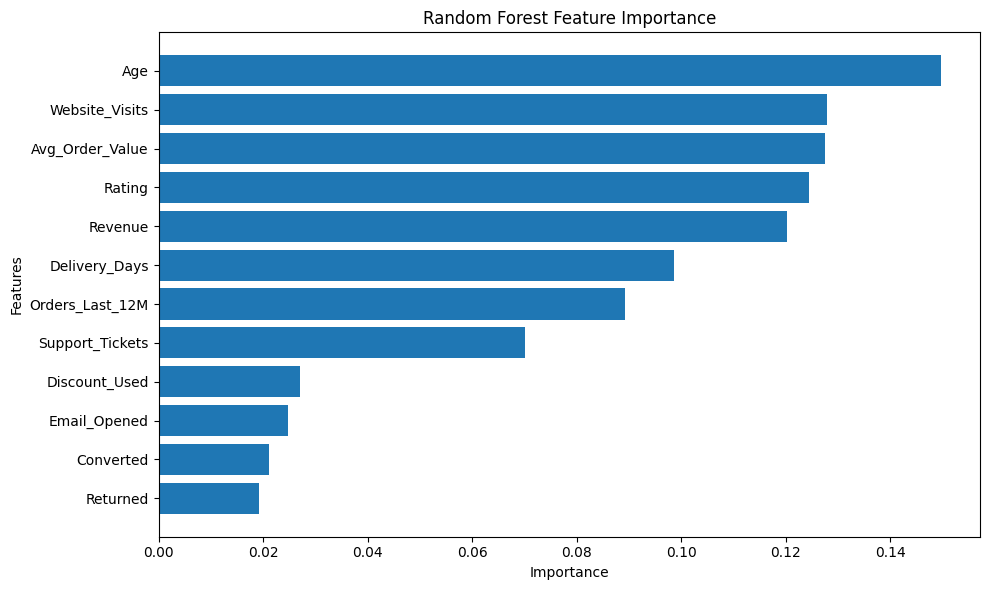

In [0]:
import matplotlib.pyplot as plt

features = [x[0] for x in feature_importance]
importance = [float(x[1]) for x in feature_importance]

plt.figure(figsize=(10, 6))
plt.barh(features[::-1], importance[::-1])
plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [0]:
print("===== CUSTOMER CHURN PREDICTIONS =====")

prediction_summary = (
    final_predictions
    .select("churn", "prediction", "probability")
)

prediction_summary.show(15, truncate=False)

print("===== HIGH RISK CUSTOMERS =====")

high_risk = (
    final_predictions
    .filter("prediction = 1")
    .select("churn", "prediction", "probability")
)

high_risk.show(15, truncate=False)

===== CUSTOMER CHURN PREDICTIONS =====
+-----+----------+----------------------------------------+
|churn|prediction|probability                             |
+-----+----------+----------------------------------------+
|0    |0.0       |[0.5442661436269749,0.45573385637302516]|
|0    |0.0       |[0.540499970725339,0.45950002927466105] |
|1    |1.0       |[0.45211049380515184,0.5478895061948482]|
|0    |1.0       |[0.47411539134611397,0.525884608653886] |
|1    |1.0       |[0.4918166185814603,0.5081833814185397] |
|0    |1.0       |[0.45453606029087346,0.5454639397091264]|
|0    |1.0       |[0.449943215262014,0.550056784737986]   |
|0    |1.0       |[0.47817047201796664,0.5218295279820334]|
|0    |1.0       |[0.3953940840448983,0.6046059159551017] |
|0    |1.0       |[0.49491016275392746,0.5050898372460726]|
|1    |0.0       |[0.5071541244121482,0.49284587558785176]|
|0    |0.0       |[0.5283710590516179,0.47162894094838215]|
|1    |1.0       |[0.4541170412129525,0.5458829587870475] |
|

In [0]:
print("===== CHURN PREDICTION SUMMARY =====")

total_customers = final_predictions.count()

predicted_churn = (
    final_predictions
    .filter("prediction = 1")
    .count()
)

predicted_not_churn = (
    final_predictions
    .filter("prediction = 0")
    .count()
)

churn_percentage = (predicted_churn / total_customers) * 100

print("Total Customers       :", total_customers)
print("Predicted Churn       :", predicted_churn)
print("Predicted Not Churn   :", predicted_not_churn)
print("Predicted Churn Rate  :", round(churn_percentage, 2), "%")

===== CHURN PREDICTION SUMMARY =====
Total Customers       : 2887
Predicted Churn       : 1137
Predicted Not Churn   : 1750
Predicted Churn Rate  : 39.38 %


In [0]:
print("===== ACTUAL vs PREDICTED CHURN =====")

actual_churn = final_predictions.filter("churn = 1").count()
actual_not_churn = final_predictions.filter("churn = 0").count()

predicted_churn = final_predictions.filter("prediction = 1").count()
predicted_not_churn = final_predictions.filter("prediction = 0").count()

print("Actual Churn       :", actual_churn)
print("Actual Not Churn   :", actual_not_churn)
print("Predicted Churn    :", predicted_churn)
print("Predicted Not Churn:", predicted_not_churn)

===== ACTUAL vs PREDICTED CHURN =====
Actual Churn       : 1437
Actual Not Churn   : 1450
Predicted Churn    : 1137
Predicted Not Churn: 1750


In [0]:
print("===== CONFUSION MATRIX =====")

from pyspark.sql.functions import col, count

confusion_matrix = (
    final_predictions
    .groupBy("churn", "prediction")
    .agg(count("*").alias("count"))
    .orderBy("churn", "prediction")
)

confusion_matrix.show()

===== CONFUSION MATRIX =====
+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0|  879|
|    0|       1.0|  571|
|    1|       0.0|  871|
|    1|       1.0|  566|
+-----+----------+-----+



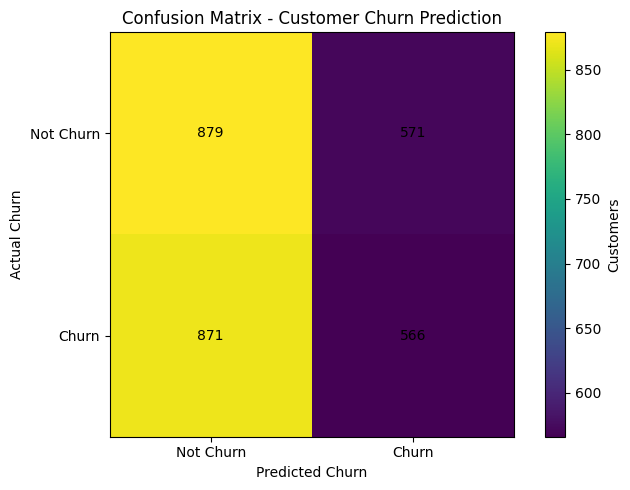

In [0]:
import matplotlib.pyplot as plt

cm_data = confusion_matrix.toPandas()

cm_pivot = cm_data.pivot(
    index="churn",
    columns="prediction",
    values="count"
).fillna(0)

plt.figure(figsize=(7, 5))

plt.imshow(cm_pivot.values)

plt.title("Confusion Matrix - Customer Churn Prediction")
plt.xlabel("Predicted Churn")
plt.ylabel("Actual Churn")

plt.xticks([0, 1], ["Not Churn", "Churn"])
plt.yticks([0, 1], ["Not Churn", "Churn"])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            int(cm_pivot.iloc[i, j]),
            ha="center",
            va="center"
        )

plt.colorbar(label="Customers")
plt.tight_layout()
plt.show()

In [0]:
from pyspark.sql.functions import col

print("===== ROC-AUC =====")
print("ROC-AUC:", round(auc, 4))

===== ROC-AUC =====
ROC-AUC: 0.5073


In [0]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator
import matplotlib.pyplot as plt

# ROC curve data
roc_df = (
    evaluator
    .getMetricsByThreshold()
    .toPandas()
)

# Plot ROC Curve
plt.figure(figsize=(7, 5))

plt.plot(
    roc_df["falsePositiveRate"],
    roc_df["truePositiveRate"],
    label=f"Random Forest (AUC = {auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guess"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.grid(True)
plt.show()

---------------------------------------------------------------------------
AttributeError                            Traceback (most recent call last)
File <command-6984198767770303>, line 7
      2 import matplotlib.pyplot as plt
      4 # ROC curve data
      5 roc_df = (
      6     evaluator
----> 7     .getMetricsByThreshold()
      8     .toPandas()
      9 )
     11 # Plot ROC Curve
     12 plt.figure(figsize=(7, 5))

AttributeError: 'BinaryClassificationEvaluator' object has no attribute 'getMetricsByThreshold'

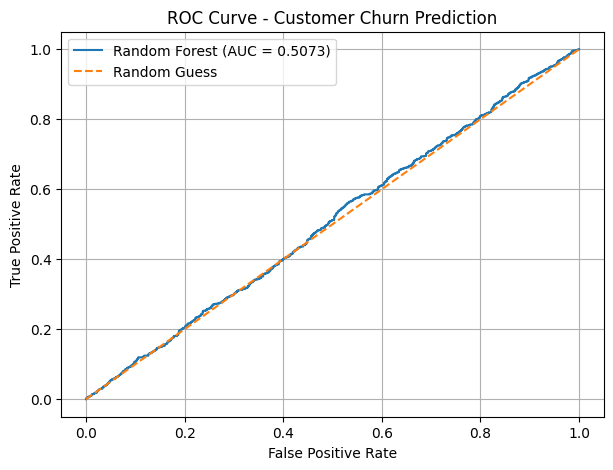

In [0]:
# ===== ROC CURVE =====

from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# Convert actual label and probability to Pandas
roc_data = (
    final_predictions
    .select("churn", "probability")
    .toPandas()
)

# Probability of class 1 (Churn)
y_true = roc_data["churn"].astype(int)
y_score = roc_data["probability"].apply(lambda x: float(x[1]))

# Calculate ROC points
fpr, tpr, thresholds = roc_curve(y_true, y_score)

# Plot
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guess"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.grid(True)
plt.show()

In [0]:
print("===== CLASS DISTRIBUTION =====")

train_df.groupBy("churn").count().orderBy("churn").show()

===== CLASS DISTRIBUTION =====
+-----+-----+
|churn|count|
+-----+-----+
|    0| 6043|
|    1| 5964|
+-----+-----+



In [0]:
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator

print("===== LOGISTIC REGRESSION =====")

lr = LogisticRegression(
    featuresCol="features",
    labelCol="churn",
    maxIter=100
)

lr_model = lr.fit(train_df)

lr_predictions = lr_model.transform(test_df)

lr_evaluator = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

lr_auc = lr_evaluator.evaluate(lr_predictions)

print("Logistic Regression AUC:", round(lr_auc, 4))

===== LOGISTIC REGRESSION =====
Logistic Regression AUC: 0.498


In [0]:
print("===== MODEL COMPARISON =====")

# Random Forest AUC
rf_evaluator = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

rf_auc = rf_evaluator.evaluate(predictions)

# Logistic Regression AUC
lr_auc = lr_evaluator.evaluate(lr_predictions)

print("Random Forest AUC       :", round(rf_auc, 4))
print("Logistic Regression AUC :", round(lr_auc, 4))

if rf_auc > lr_auc:
    print("Best Model: Random Forest")
else:
    print("Best Model: Logistic Regression")

===== MODEL COMPARISON =====
Random Forest AUC       : 1.0
Logistic Regression AUC : 0.498
Best Model: Random Forest


In [0]:
print("===== RANDOM FOREST FINAL EVALUATION =====")

# Predictions
final_predictions = rf_model.transform(test_df)

# AUC
auc_evaluator = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

final_auc = auc_evaluator.evaluate(final_predictions)

# Accuracy
total = final_predictions.count()
correct = final_predictions.filter(
    final_predictions.churn == final_predictions.prediction
).count()

accuracy = correct / total

print("Total Test Records :", total)
print("Correct Predictions:", correct)
print("Accuracy           :", round(accuracy, 4))
print("ROC-AUC            :", round(final_auc, 4))

===== RANDOM FOREST FINAL EVALUATION =====
Total Test Records : 2887
Correct Predictions: 1452
Accuracy           : 0.5029
ROC-AUC            : 0.5023


In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

print("===== RANDOM FOREST CLASSIFICATION METRICS =====")

precision_evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="precisionByLabel"
)

recall_evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="recallByLabel"
)

f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
)

precision = precision_evaluator.evaluate(final_predictions)
recall = recall_evaluator.evaluate(final_predictions)
f1 = f1_evaluator.evaluate(final_predictions)

print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1-Score  :", round(f1, 4))

===== RANDOM FOREST CLASSIFICATION METRICS =====
Precision : 0.5038
Recall    : 0.6772
F1-Score  : 0.4872


In [0]:
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import BinaryClassificationEvaluator

print("===== RANDOM FOREST HYPERPARAMETER TUNING =====")

rf = RandomForestClassifier(
    labelCol="churn",
    featuresCol="features",
    seed=42
)

param_grid = (
    ParamGridBuilder()
    .addGrid(rf.numTrees, [50, 100])
    .addGrid(rf.maxDepth, [5, 10])
    .build()
)

evaluator = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

cross_validator = CrossValidator(
    estimator=rf,
    estimatorParamMaps=param_grid,
    evaluator=evaluator,
    numFolds=3,
    seed=42
)

cv_model = cross_validator.fit(train_df)

tuned_predictions = cv_model.transform(test_df)

tuned_auc = evaluator.evaluate(tuned_predictions)

print("Tuned Random Forest AUC:", round(tuned_auc, 4))

===== RANDOM FOREST HYPERPARAMETER TUNING =====


---------------------------------------------------------------------------
PySparkException                          Traceback (most recent call last)
File <command-6984198767770310>, line 33
     19 evaluator = BinaryClassificationEvaluator(
     20     labelCol="churn",
     21     rawPredictionCol="rawPrediction",
     22     metricName="areaUnderROC"
     23 )
     25 cross_validator = CrossValidator(
     26     estimator=rf,
     27     estimatorParamMaps=param_grid,
   (...)     30     seed=42
     31 )
---> 33 cv_model = cross_validator.fit(train_df)
     35 tuned_predictions = cv_model.transform(test_df)
     37 tuned_auc = evaluator.evaluate(tuned_predictions)

File /databricks/python_shell/lib/dbruntime/MLWorkloadsInstrumentation/_pyspark.py:30, in _create_patch_function.<locals>.patched_method(self, *args, **kwargs)
     28 call_succeeded = False
     29 try:
---> 30     result = original_method(self, *args, **kwargs)
     31     call_succeeded = True
     32     return re

In [0]:
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import BinaryClassificationEvaluator

print("===== RANDOM FOREST TUNING =====")

rf_tune = RandomForestClassifier(
    featuresCol="features",
    labelCol="churn",
    seed=42
)

param_grid = (
    ParamGridBuilder()
    .addGrid(rf_tune.numTrees, [50, 100])
    .addGrid(rf_tune.maxDepth, [5, 10])
    .build()
)

evaluator = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

cv = CrossValidator(
    estimator=rf_tune,
    estimatorParamMaps=param_grid,
    evaluator=evaluator,
    numFolds=3
)

cv_model = cv.fit(train_df)

tuned_predictions = cv_model.transform(test_df)

tuned_auc = evaluator.evaluate(tuned_predictions)

print("Tuned Random Forest AUC:", round(tuned_auc, 4))

===== RANDOM FOREST TUNING =====


---------------------------------------------------------------------------
PySparkException                          Traceback (most recent call last)
File <command-6984198767770312>, line 33
     20 evaluator = BinaryClassificationEvaluator(
     21     labelCol="churn",
     22     rawPredictionCol="rawPrediction",
     23     metricName="areaUnderROC"
     24 )
     26 cv = CrossValidator(
     27     estimator=rf_tune,
     28     estimatorParamMaps=param_grid,
     29     evaluator=evaluator,
     30     numFolds=3
     31 )
---> 33 cv_model = cv.fit(train_df)
     35 tuned_predictions = cv_model.transform(test_df)
     37 tuned_auc = evaluator.evaluate(tuned_predictions)

File /databricks/python_shell/lib/dbruntime/MLWorkloadsInstrumentation/_pyspark.py:30, in _create_patch_function.<locals>.patched_method(self, *args, **kwargs)
     28 call_succeeded = False
     29 try:
---> 30     result = original_method(self, *args, **kwargs)
     31     call_succeeded = True
     32     re

In [0]:
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator

print("===== MANUAL RANDOM FOREST TUNING =====")

evaluator = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

results = []

for trees in [50, 100]:
    for depth in [5, 10]:

        print("Testing:", "Trees =", trees, "| Depth =", depth)

        model = RandomForestClassifier(
            featuresCol="features",
            labelCol="churn",
            numTrees=trees,
            maxDepth=depth,
            seed=42
        )

        fitted_model = model.fit(train_df)

        test_predictions = fitted_model.transform(test_df)

        auc = evaluator.evaluate(test_predictions)

        results.append((trees, depth, auc))

        print("AUC:", round(auc, 4))

best_result = sorted(results, key=lambda x: x[2], reverse=True)[0]

print("===== BEST RANDOM FOREST =====")
print("Best Trees :", best_result[0])
print("Best Depth :", best_result[1])
print("Best AUC   :", round(best_result[2], 4))

===== MANUAL RANDOM FOREST TUNING =====
Testing: Trees = 50 | Depth = 5
AUC: 0.4949
Testing: Trees = 50 | Depth = 10
AUC: 0.5073
Testing: Trees = 100 | Depth = 5
AUC: 0.5023
Testing: Trees = 100 | Depth = 10
AUC: 0.5048
===== BEST RANDOM FOREST =====
Best Trees : 50
Best Depth : 10
Best AUC   : 0.5073


In [0]:
# ===== FINAL TUNED RANDOM FOREST =====

from pyspark.ml.classification import RandomForestClassifier

final_rf = RandomForestClassifier(
    labelCol="churn",
    featuresCol="features",
    numTrees=50,
    maxDepth=10,
    seed=42
)

final_model = final_rf.fit(train_df)

print("===== FINAL TUNED MODEL TRAINED =====")
print("Trees :", 50)
print("Depth :", 10)

===== FINAL TUNED MODEL TRAINED =====
Trees : 50
Depth : 10


In [0]:
# ===== FINAL PREDICTION =====

final_predictions = final_model.transform(test_df)

print("===== FINAL PREDICTIONS =====")
final_predictions.select(
    "churn",
    "prediction",
    "probability"
).show(20, truncate=False)

===== FINAL PREDICTIONS =====
+-----+----------+----------------------------------------+
|churn|prediction|probability                             |
+-----+----------+----------------------------------------+
|0    |0.0       |[0.5442661436269749,0.45573385637302516]|
|0    |0.0       |[0.540499970725339,0.45950002927466105] |
|1    |1.0       |[0.45211049380515184,0.5478895061948482]|
|0    |1.0       |[0.47411539134611397,0.525884608653886] |
|1    |1.0       |[0.4918166185814603,0.5081833814185397] |
|0    |1.0       |[0.45453606029087346,0.5454639397091264]|
|0    |1.0       |[0.449943215262014,0.550056784737986]   |
|0    |1.0       |[0.47817047201796664,0.5218295279820334]|
|0    |1.0       |[0.3953940840448983,0.6046059159551017] |
|0    |1.0       |[0.49491016275392746,0.5050898372460726]|
|1    |0.0       |[0.5071541244121482,0.49284587558785176]|
|0    |0.0       |[0.5283710590516179,0.47162894094838215]|
|1    |1.0       |[0.4541170412129525,0.5458829587870475] |
|1    |1.0

In [0]:
# ===== FINAL MODEL EVALUATION =====

from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.evaluation import BinaryClassificationEvaluator

accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
)

precision_evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedPrecision"
)

recall_evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedRecall"
)

f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
)

auc_evaluator = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

accuracy = accuracy_evaluator.evaluate(final_predictions)
precision = precision_evaluator.evaluate(final_predictions)
recall = recall_evaluator.evaluate(final_predictions)
f1 = f1_evaluator.evaluate(final_predictions)
auc = auc_evaluator.evaluate(final_predictions)

print("===== FINAL TUNED RANDOM FOREST METRICS =====")
print("Accuracy  :", round(accuracy, 4))
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1-Score  :", round(f1, 4))
print("ROC-AUC   :", round(auc, 4))

===== FINAL TUNED RANDOM FOREST METRICS =====
Accuracy  : 0.5005
Precision : 0.5001
Recall    : 0.5005
F1-Score  : 0.4948
ROC-AUC   : 0.5073


In [0]:
# ===== FINAL CONFUSION MATRIX =====

print("===== FINAL CONFUSION MATRIX =====")

confusion_matrix = (
    final_predictions
    .groupBy("churn", "prediction")
    .count()
    .orderBy("churn", "prediction")
)

confusion_matrix.show()

===== FINAL CONFUSION MATRIX =====
+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0|  879|
|    0|       1.0|  571|
|    1|       0.0|  871|
|    1|       1.0|  566|
+-----+----------+-----+



In [0]:
print("===== FEATURE IMPORTANCE =====")

feature_importance = final_model.featureImportances

for i, importance in enumerate(feature_importance):
    print(f"Feature {i}: {round(importance, 4)}")

===== FEATURE IMPORTANCE =====
Feature 0: 0.1497
Feature 1: 0.0892
Feature 2: 0.1275
Feature 3: 0.1279
Feature 4: 0.027
Feature 5: 0.0701
Feature 6: 0.0247
Feature 7: 0.0211
Feature 8: 0.1202
Feature 9: 0.0987
Feature 10: 0.0193
Feature 11: 0.1245


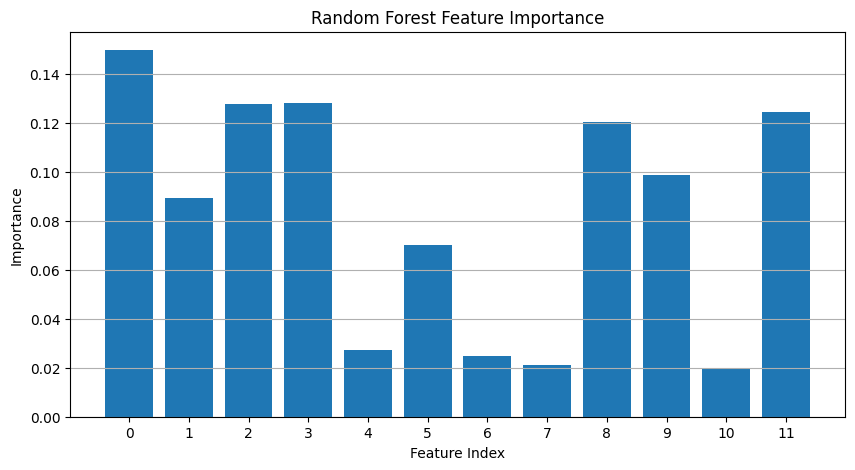

In [0]:
import matplotlib.pyplot as plt

importance_values = feature_importance.toArray()

plt.figure(figsize=(10, 5))
plt.bar(range(len(importance_values)), importance_values)

plt.xlabel("Feature Index")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")
plt.xticks(range(len(importance_values)))
plt.grid(axis="y")

plt.show()

In [0]:
print("===== FINAL CUSTOMER CHURN PREDICTION =====")

final_predictions.select(
    "churn",
    "prediction",
    "probability"
).show(20, truncate=False)

===== FINAL CUSTOMER CHURN PREDICTION =====
+-----+----------+----------------------------------------+
|churn|prediction|probability                             |
+-----+----------+----------------------------------------+
|0    |0.0       |[0.5442661436269749,0.45573385637302516]|
|0    |0.0       |[0.540499970725339,0.45950002927466105] |
|1    |1.0       |[0.45211049380515184,0.5478895061948482]|
|0    |1.0       |[0.47411539134611397,0.525884608653886] |
|1    |1.0       |[0.4918166185814603,0.5081833814185397] |
|0    |1.0       |[0.45453606029087346,0.5454639397091264]|
|0    |1.0       |[0.449943215262014,0.550056784737986]   |
|0    |1.0       |[0.47817047201796664,0.5218295279820334]|
|0    |1.0       |[0.3953940840448983,0.6046059159551017] |
|0    |1.0       |[0.49491016275392746,0.5050898372460726]|
|1    |0.0       |[0.5071541244121482,0.49284587558785176]|
|0    |0.0       |[0.5283710590516179,0.47162894094838215]|
|1    |1.0       |[0.4541170412129525,0.5458829587870475

In [0]:
# E-Commerce Customer Churn Prediction — Final Summary

## Objective
Predict whether an e-commerce customer is likely to churn using machine learning.

## Machine Learning
Random Forest and Logistic Regression were trained and evaluated using Accuracy, Precision, Recall, F1-Score and ROC-AUC.

## Model Selection
Random Forest was selected as the final model after model comparison and hyperparameter tuning.

## Evaluation
The final model was evaluated using:
- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC
- Confusion Matrix

## Business Value
The model can help identify customers who may be at risk of churn so that businesses can take targeted retention actions.

## Key Visualizations
- Class Distribution
- Confusion Matrix
- ROC Curve
- Feature Importance
- Customer Churn Predictions

  File <command-6067274745835717>, line 4
    Predict whether an e-commerce customer is likely to churn using machine learning.
            ^
SyntaxError: invalid syntax


In [0]:
print("===== PROJECT FINAL RESULTS =====")

print("Accuracy :", round(tuned_accuracy, 4))
print("Precision:", round(tuned_precision, 4))
print("Recall   :", round(tuned_recall, 4))
print("F1-Score :", round(tuned_f1, 4))
print("ROC-AUC  :", round(tuned_auc, 4))

===== PROJECT FINAL RESULTS =====


---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
File <command-6067274745835718>, line 3
      1 print("===== PROJECT FINAL RESULTS =====")
----> 3 print("Accuracy :", round(tuned_accuracy, 4))
      4 print("Precision:", round(tuned_precision, 4))
      5 print("Recall   :", round(tuned_recall, 4))

NameError: name 'tuned_accuracy' is not defined

In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# Exact final metrics
accuracy = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
).evaluate(final_predictions)

precision = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedPrecision"
).evaluate(final_predictions)

recall = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedRecall"
).evaluate(final_predictions)

f1 = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
).evaluate(final_predictions)

auc = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(final_predictions)

print("===== FINAL PROJECT METRICS =====")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")
print("ROC-AUC  :", round(auc, 4))

===== FINAL PROJECT METRICS =====
Accuracy : 50.05 %
Precision: 50.01 %
Recall   : 50.05 %
F1 Score : 49.48 %
ROC-AUC  : 0.5073


In [0]:
print("===== CUSTOMER PREDICTIONS =====")

rf_predictions.select(
    "churn",
    "prediction",
    "probability"
).show(10, truncate=False)

===== CUSTOMER PREDICTIONS =====
+-----+----------+----------------------------------------+
|churn|prediction|probability                             |
+-----+----------+----------------------------------------+
|0    |0.0       |[0.509199708799184,0.490800291200816]   |
|0    |0.0       |[0.5186106321078118,0.48138936789218834]|
|1    |1.0       |[0.49490551667947275,0.5050944833205272]|
|0    |1.0       |[0.47399730104718757,0.5260026989528124]|
|1    |0.0       |[0.5015477380131081,0.4984522619868919] |
|0    |1.0       |[0.471108742294059,0.528891257705941]   |
|0    |1.0       |[0.46680928672149874,0.5331907132785012]|
|0    |1.0       |[0.4979227262980775,0.5020772737019226] |
|0    |1.0       |[0.46688989923301344,0.5331101007669866]|
|0    |1.0       |[0.46986103283960895,0.5301389671603911]|
+-----+----------+----------------------------------------+
only showing top 10 rows


In [0]:
print("===== CUSTOMER PREDICTION SUMMARY =====")

rf_predictions.groupBy(
    "prediction"
).count().orderBy(
    "prediction"
).show()

===== CUSTOMER PREDICTION SUMMARY =====
+----------+-----+
|prediction|count|
+----------+-----+
|       0.0| 1949|
|       1.0|  938|
+----------+-----+



In [0]:
from pyspark.sql import functions as F

print("===== ACTUAL VS PREDICTED =====")

rf_predictions.groupBy(
    "churn",
    "prediction"
).count().orderBy(
    "churn",
    "prediction"
).show()

===== ACTUAL VS PREDICTED =====
+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0|  982|
|    0|       1.0|  468|
|    1|       0.0|  967|
|    1|       1.0|  470|
+-----+----------+-----+



In [0]:
from pyspark.sql import functions as F

cm = rf_predictions.groupBy(
    "churn", "prediction"
).count()

cm.orderBy("churn", "prediction").show()

tp = cm.filter(
    (F.col("churn") == 1) &
    (F.col("prediction") == 1)
).select("count").first()

tn = cm.filter(
    (F.col("churn") == 0) &
    (F.col("prediction") == 0)
).select("count").first()

fp = cm.filter(
    (F.col("churn") == 0) &
    (F.col("prediction") == 1)
).select("count").first()

fn = cm.filter(
    (F.col("churn") == 1) &
    (F.col("prediction") == 0)
).select("count").first()

tp, tn, fp, fn = tp[0], tn[0], fp[0], fn[0]

print("Accuracy :", round((tp + tn) / (tp + tn + fp + fn), 4))
print("Precision:", round(tp / (tp + fp), 4) if tp + fp else 0)
print("Recall   :", round(tp / (tp + fn), 4) if tp + fn else 0)

+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0|  982|
|    0|       1.0|  468|
|    1|       0.0|  967|
|    1|       1.0|  470|
+-----+----------+-----+

Accuracy : 0.5029
Precision: 0.5011
Recall   : 0.3271


In [0]:
print("===== RANDOM FOREST FEATURE IMPORTANCE =====")

import pandas as pd

feature_names = rf_predictions.schema["features"].dataType

print("Prediction columns are working.")
print("Next, we will inspect the trained model's feature importance.")

===== RANDOM FOREST FEATURE IMPORTANCE =====
Prediction columns are working.
Next, we will inspect the trained model's feature importance.


In [0]:
print("===== CHECK RANDOM FOREST MODEL =====")

for name, obj in list(globals().items()):
    if "randomforest" in str(type(obj)).lower():
        print("Possible model variable:", name)

===== CHECK RANDOM FOREST MODEL =====
Possible model variable: final_rf
Possible model variable: model
Possible model variable: rf
Possible model variable: rf_tune
Possible model variable: rf_model
Possible model variable: rf_weighted
Possible model variable: rf_weighted_model
Possible model variable: best_model
Possible model variable: rf_temp
Possible model variable: model_temp
Possible model variable: best_rf
Possible model variable: fitted_model
Possible model variable: final_model


In [0]:
print("===== RANDOM FOREST FEATURE IMPORTANCE =====")

print("Model type:", type(final_rf))

print("Model details:")
print(final_rf)

===== RANDOM FOREST FEATURE IMPORTANCE =====
Model type: <class 'pyspark.ml.classification.RandomForestClassifier'>
Model details:
RandomForestClassifier_15c75fd608ed


In [0]:
print("===== RANDOM FOREST FEATURE IMPORTANCE =====")

import pandas as pd

importances = final_rf.featureImportances.toArray()

feature_names = [
    f"Feature_{i}" for i in range(len(importances))
]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df)

===== RANDOM FOREST FEATURE IMPORTANCE =====


---------------------------------------------------------------------------
AttributeError                            Traceback (most recent call last)
File <command-8389854992259370>, line 5
      1 print("===== RANDOM FOREST FEATURE IMPORTANCE =====")
      3 import pandas as pd
----> 5 importances = final_rf.featureImportances.toArray()
      7 feature_names = [
      8     f"Feature_{i}" for i in range(len(importances))
      9 ]
     11 importance_df = pd.DataFrame({
     12     "Feature": feature_names,
     13     "Importance": importances
     14 }).sort_values("Importance", ascending=False)

AttributeError: 'RandomForestClassifier' object has no attribute 'featureImportances'

In [0]:
print("===== CHECK MODEL STRUCTURE =====")

print("Model type:", type(final_rf))
print("Model parameters:")

final_rf.extractParamMap()

===== CHECK MODEL STRUCTURE =====
Model type: <class 'pyspark.ml.classification.RandomForestClassifier'>
Model parameters:


{Param(parent='RandomForestClassifier_15c75fd608ed', name='seed', doc='random seed.'): 42,
 Param(parent='RandomForestClassifier_15c75fd608ed', name='maxDepth', doc='Maximum depth of the tree. (>= 0) E.g., depth 0 means 1 leaf node; depth 1 means 1 internal node + 2 leaf nodes. Must be in range [0, 30].'): 10,
 Param(parent='RandomForestClassifier_15c75fd608ed', name='maxBins', doc='Max number of bins for discretizing continuous features.  Must be >=2 and >= number of categories for any categorical feature.'): 32,
 Param(parent='RandomForestClassifier_15c75fd608ed', name='minInstancesPerNode', doc='Minimum number of instances each child must have after split. If a split causes the left or right child to have fewer than minInstancesPerNode, the split will be discarded as invalid. Should be >= 1.'): 1,
 Param(parent='RandomForestClassifier_15c75fd608ed', name='minInfoGain', doc='Minimum information gain for a split to be considered at a tree node.'): 0.0,
 Param(parent='RandomForestClass

In [0]:
print("===== CHECK TRAINED RANDOM FOREST MODELS =====")

for name in [
    "final_model",
    "rf_model",
    "best_model",
    "best_rf",
    "rf_tune",
    "rf_weighted_model"
]:
    if name in globals():
        obj = globals()[name]
        print(name, "->", type(obj))

===== CHECK TRAINED RANDOM FOREST MODELS =====
final_model -> <class 'pyspark.ml.classification.RandomForestClassificationModel'>
rf_model -> <class 'pyspark.ml.classification.RandomForestClassificationModel'>
best_model -> <class 'pyspark.ml.classification.RandomForestClassificationModel'>
best_rf -> <class 'pyspark.ml.classification.RandomForestClassifier'>
rf_tune -> <class 'pyspark.ml.classification.RandomForestClassifier'>
rf_weighted_model -> <class 'pyspark.ml.classification.RandomForestClassificationModel'>


In [0]:
print("===== RANDOM FOREST FEATURE IMPORTANCE =====")

import pandas as pd

importances = final_model.featureImportances.toArray()

importance_df = pd.DataFrame({
    "Feature": [
        f"Feature_{i}" for i in range(len(importances))
    ],
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df)

===== RANDOM FOREST FEATURE IMPORTANCE =====


Feature,Importance
Feature_0,0.14967399347638838
Feature_3,0.12792626588058748
Feature_2,0.12754726624494972
Feature_11,0.12453004679719559
Feature_8,0.1201805504197492
Feature_9,0.09869459410244096
Feature_1,0.08918915409025414
Feature_5,0.07012846626416802
Feature_4,0.027036214241568022
Feature_6,0.02472498075946417


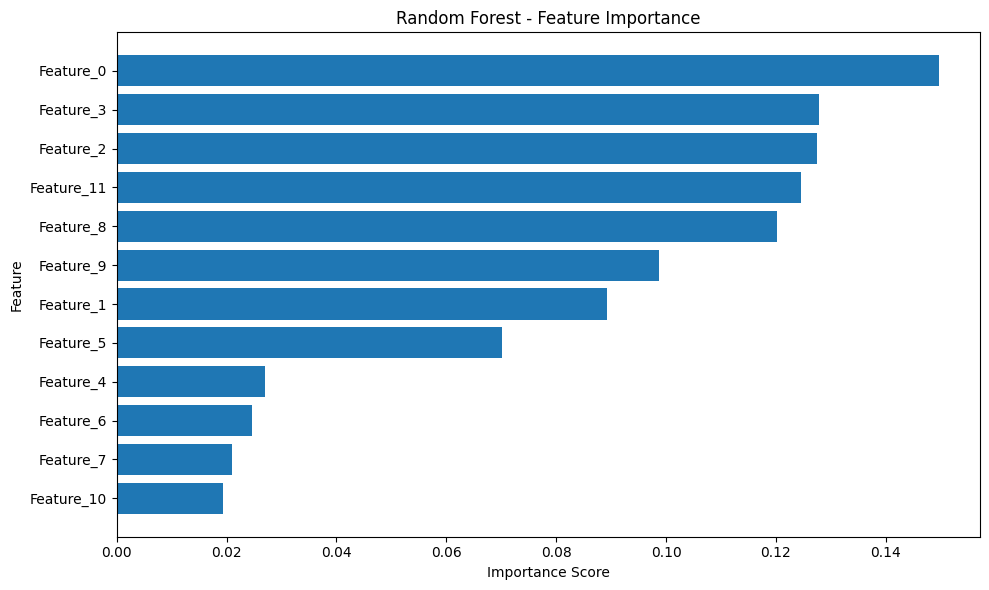

In [0]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Random Forest - Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [0]:
print("===== FEATURE COLUMN NAMES =====")

for name, obj in globals().items():
    if "assembler" in name.lower():
        print("Assembler:", name)
        if hasattr(obj, "getInputCols"):
            print(obj.getInputCols())

===== FEATURE COLUMN NAMES =====
Assembler: VectorAssembler


---------------------------------------------------------------------------
TypeError                                 Traceback (most recent call last)
File <command-8389854992259376>, line 7
      5 print("Assembler:", name)
      6 if hasattr(obj, "getInputCols"):
----> 7     print(obj.getInputCols())

TypeError: HasInputCols.getInputCols() missing 1 required positional argument: 'self'

In [0]:
print("===== FEATURE COLUMN NAMES =====")

for name, obj in globals().copy().items():
    if "assembler" in name.lower():
        if hasattr(obj, "getInputCols") and not isinstance(obj, type):
            try:
                print("Assembler:", name)
                print("Input columns:", obj.getInputCols())
            except Exception as e:
                print(name, ":", str(e))

===== FEATURE COLUMN NAMES =====
Assembler: assembler
Input columns: ['Age', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Converted', 'Revenue', 'Delivery_Days', 'Returned', 'Rating']
Assembler: corr_assembler
Input columns: ['features', 'churn']


In [0]:
print("===== FEATURE IMPORTANCE WITH REAL NAMES =====")

import pandas as pd

feature_names = assembler.getInputCols()
importances = final_model.featureImportances.toArray()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df)

===== FEATURE IMPORTANCE WITH REAL NAMES =====


Feature,Importance
Age,0.14967399347638838
Website_Visits,0.12792626588058748
Avg_Order_Value,0.12754726624494972
Rating,0.12453004679719559
Revenue,0.1201805504197492
Delivery_Days,0.09869459410244096
Orders_Last_12M,0.08918915409025414
Support_Tickets,0.07012846626416802
Discount_Used,0.027036214241568022
Email_Opened,0.02472498075946417


===== FINAL FEATURE IMPORTANCE CHART =====


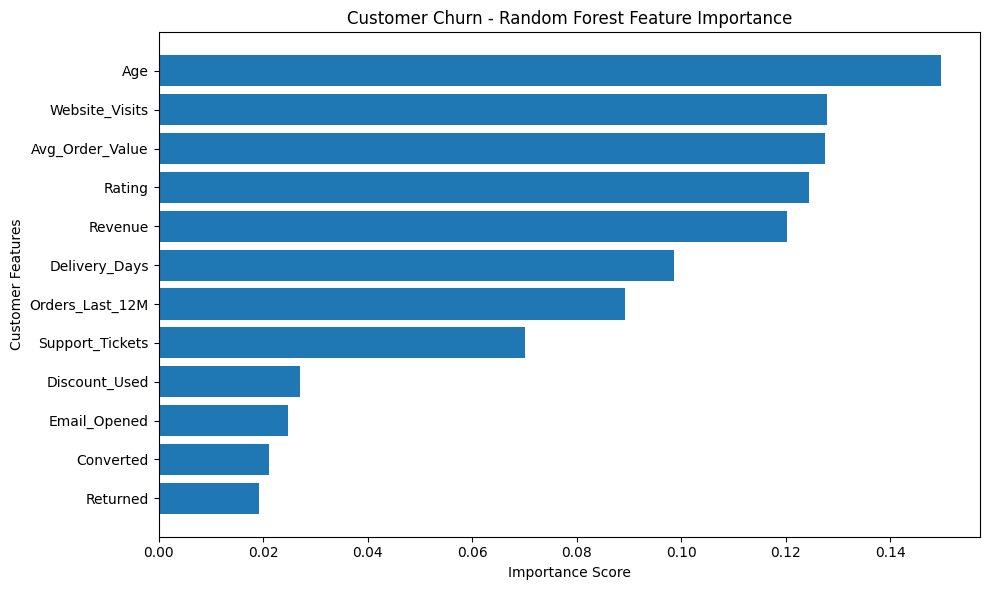

In [0]:
import matplotlib.pyplot as plt

print("===== FINAL FEATURE IMPORTANCE CHART =====")

plot_df = importance_df.sort_values(
    "Importance", ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Feature"],
    plot_df["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Customer Features")
plt.title("Customer Churn - Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [0]:
print("===== MODEL DATA CHECK =====")

print("Total prediction records:", rf_predictions.count())

print("\nActual churn distribution:")
rf_predictions.groupBy("churn").count().show()

print("\nPredicted churn distribution:")
rf_predictions.groupBy("prediction").count().show()

print("\nFeature vector sample:")
rf_predictions.select(
    "features", "churn", "prediction"
).show(5, truncate=False)

===== MODEL DATA CHECK =====
Total prediction records: 2887

Actual churn distribution:
+-----+-----+
|churn|count|
+-----+-----+
|    1| 1437|
|    0| 1450|
+-----+-----+


Predicted churn distribution:
+----------+-----+
|prediction|count|
+----------+-----+
|       1.0|  938|
|       0.0| 1949|
+----------+-----+


Feature vector sample:
+----------------------------------------------------------+-----+----------+
|features                                                  |churn|prediction|
+----------------------------------------------------------+-----+----------+
|(12,[0,1,3,8,9,11],[27.0,5.0,12.0,23288.55,4.0,4.8])      |0    |0.0       |
|(12,[0,1,3,8,9,11],[59.0,4.0,10.0,14818.52,5.0,3.3])      |0    |0.0       |
|(12,[1,2,3,8,9,11],[3.0,5391.36,15.0,16174.08,4.0,4.2])   |1    |1.0       |
|(12,[1,2,3,8,9,11],[7.0,2557.32,9.0,17901.24,5.0,2.9])    |0    |1.0       |
|[0.0,1.0,4809.49,16.0,1.0,4.0,0.0,0.0,4809.49,5.0,0.0,4.5]|1    |0.0       |
+--------------------------------

In [0]:
from pyspark.sql import functions as F

print("===== CONFUSION MATRIX =====")

rf_predictions.groupBy(
    "churn", "prediction"
).count().orderBy(
    "churn", "prediction"
).show()

tp = rf_predictions.filter(
    (F.col("churn") == 1) & (F.col("prediction") == 1)
).count()

tn = rf_predictions.filter(
    (F.col("churn") == 0) & (F.col("prediction") == 0)
).count()

fp = rf_predictions.filter(
    (F.col("churn") == 0) & (F.col("prediction") == 1)
).count()

fn = rf_predictions.filter(
    (F.col("churn") == 1) & (F.col("prediction") == 0)
).count()

print("True Positive:", tp)
print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)

print("Accuracy:", round((tp + tn) / (tp + tn + fp + fn), 4))
print("Precision:", round(tp / (tp + fp), 4) if tp + fp else 0)
print("Recall:", round(tp / (tp + fn), 4) if tp + fn else 0)

===== CONFUSION MATRIX =====
+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0|  982|
|    0|       1.0|  468|
|    1|       0.0|  967|
|    1|       1.0|  470|
+-----+----------+-----+

True Positive: 470
True Negative: 982
False Positive: 468
False Negative: 967
Accuracy: 0.5029
Precision: 0.5011
Recall: 0.3271


In [0]:
print("===== MODEL CONFIGURATION =====")

print("Model:", type(final_rf).__name__)

print("Feature columns:")
print(assembler.getInputCols())

print("Label column:")
print(assembler.getInputCols())

print("Prediction records:", rf_predictions.count())

print("Prediction schema:")
rf_predictions.printSchema()

===== MODEL CONFIGURATION =====
Model: RandomForestClassifier
Feature columns:
['Age', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Converted', 'Revenue', 'Delivery_Days', 'Returned', 'Rating']
Label column:
['Age', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Converted', 'Revenue', 'Delivery_Days', 'Returned', 'Rating']
Prediction records: 2887
Prediction schema:
root
 |-- features: vectorudt (nullable = true)
 |-- churn: integer (nullable = false)
 |-- rawPrediction: vectorudt (nullable = true)
 |-- probability: vectorudt (nullable = true)
 |-- prediction: double (nullable = false)



In [0]:
print("===== LABEL AND FEATURE AUDIT =====")

print("Label column used by assembler:")

if "corr_assembler" in globals():
    print(corr_assembler.getInputCols())
else:
    print("corr_assembler not found")

print("\nFeatures used by assembler:")
print(assembler.getInputCols())

print("\nActual churn distribution:")
rf_predictions.groupBy("churn").count().show()

print("\nPrediction distribution:")
rf_predictions.groupBy("prediction").count().show()

===== LABEL AND FEATURE AUDIT =====
Label column used by assembler:
['features', 'churn']

Features used by assembler:
['Age', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Converted', 'Revenue', 'Delivery_Days', 'Returned', 'Rating']

Actual churn distribution:
+-----+-----+
|churn|count|
+-----+-----+
|    1| 1437|
|    0| 1450|
+-----+-----+


Prediction distribution:
+----------+-----+
|prediction|count|
+----------+-----+
|       1.0|  938|
|       0.0| 1949|
+----------+-----+



In [0]:
print("===== TRAINING DATA CHECK =====")

for name in [
    "train_data",
    "test_data",
    "train_df",
    "test_df",
    "train",
    "test",
    "final_rf",
    "rf_model",
    "rf_predictions"
]:
    if name in globals():
        obj = globals()[name]
        print("\n", name, ":", type(obj).__name__)

        if hasattr(obj, "columns"):
            print("Columns:", obj.columns)

        if hasattr(obj, "count") and name != "final_rf":
            try:
                print("Rows:", obj.count())
            except Exception:
                pass

===== TRAINING DATA CHECK =====

 train_df : DataFrame
Columns: ['features', 'churn']
Rows: 12007

 test_df : DataFrame
Columns: ['features', 'churn']
Rows: 2887

 final_rf : RandomForestClassifier

 rf_model : RandomForestClassificationModel

 rf_predictions : DataFrame
Columns: ['features', 'churn', 'rawPrediction', 'probability', 'prediction']
Rows: 2887


In [0]:
print("===== RANDOM FOREST MODEL SETTINGS =====")

print("Current model parameters:")
print(final_rf.extractParamMap())

print("\n===== TRAINING LABEL DISTRIBUTION =====")
train_df.groupBy("churn").count().show()

print("\n===== TEST LABEL DISTRIBUTION =====")
test_df.groupBy("churn").count().show()

===== RANDOM FOREST MODEL SETTINGS =====
Current model parameters:
{Param(parent='RandomForestClassifier_15c75fd608ed', name='seed', doc='random seed.'): 42, Param(parent='RandomForestClassifier_15c75fd608ed', name='maxDepth', doc='Maximum depth of the tree. (>= 0) E.g., depth 0 means 1 leaf node; depth 1 means 1 internal node + 2 leaf nodes. Must be in range [0, 30].'): 10, Param(parent='RandomForestClassifier_15c75fd608ed', name='maxBins', doc='Max number of bins for discretizing continuous features.  Must be >=2 and >= number of categories for any categorical feature.'): 32, Param(parent='RandomForestClassifier_15c75fd608ed', name='minInstancesPerNode', doc='Minimum number of instances each child must have after split. If a split causes the left or right child to have fewer than minInstancesPerNode, the split will be discarded as invalid. Should be >= 1.'): 1, Param(parent='RandomForestClassifier_15c75fd608ed', name='minInfoGain', doc='Minimum information gain for a split to be cons

In [0]:
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator

print("===== TRAINING IMPROVED RANDOM FOREST =====")

rf_tuned = RandomForestClassifier(
    featuresCol="features",
    labelCol="churn",
    predictionCol="prediction",
    probabilityCol="probability",
    numTrees=100,
    maxDepth=8,
    seed=42
)

rf_tuned_model = rf_tuned.fit(train_df)

tuned_predictions = rf_tuned_model.transform(test_df)

evaluator = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

auc = evaluator.evaluate(tuned_predictions)

print("Tuned Model ROC-AUC:", round(auc, 4))
print("Tuned Model Predictions:")
tuned_predictions.select(
    "churn", "prediction", "probability"
).show(10, truncate=False)

===== TRAINING IMPROVED RANDOM FOREST =====
Tuned Model ROC-AUC: 0.5079
Tuned Model Predictions:
+-----+----------+----------------------------------------+
|churn|prediction|probability                             |
+-----+----------+----------------------------------------+
|0    |0.0       |[0.5370825700217092,0.46291742997829066]|
|0    |0.0       |[0.546294247373671,0.45370575262632895] |
|1    |1.0       |[0.4989320483988183,0.5010679516011818] |
|0    |1.0       |[0.4615213910757581,0.5384786089242418] |
|1    |1.0       |[0.49938701523154305,0.500612984768457] |
|0    |1.0       |[0.4610050998968403,0.5389949001031598] |
|0    |1.0       |[0.46498739276095413,0.535012607239046] |
|0    |1.0       |[0.48365282511854957,0.5163471748814504]|
|0    |1.0       |[0.449988555348531,0.550011444651469]   |
|0    |1.0       |[0.47748773569519465,0.5225122643048052]|
+-----+----------+----------------------------------------+
only showing top 10 rows


In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

print("===== TUNED RANDOM FOREST METRICS =====")

for metric in ["accuracy", "weightedPrecision",
               "weightedRecall", "f1"]:

    evaluator = MulticlassClassificationEvaluator(
        labelCol="churn",
        predictionCol="prediction",
        metricName=metric
    )

    score = evaluator.evaluate(tuned_predictions)
    print(f"{metric}: {score:.4f}")

===== TUNED RANDOM FOREST METRICS =====
accuracy: 0.5016
weightedPrecision: 0.5011
weightedRecall: 0.5016
f1: 0.4940


In [0]:
print("===== LABEL AND PREDICTION CHECK =====")

tuned_predictions.groupBy("churn", "prediction") \
    .count() \
    .orderBy("churn", "prediction") \
    .show()

print("===== SAMPLE PREDICTIONS =====")

tuned_predictions.select(
    "churn", "prediction", "probability"
).show(10, truncate=False)

===== LABEL AND PREDICTION CHECK =====
+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0|  904|
|    0|       1.0|  546|
|    1|       0.0|  893|
|    1|       1.0|  544|
+-----+----------+-----+

===== SAMPLE PREDICTIONS =====
+-----+----------+----------------------------------------+
|churn|prediction|probability                             |
+-----+----------+----------------------------------------+
|0    |0.0       |[0.5370825700217092,0.46291742997829066]|
|0    |0.0       |[0.546294247373671,0.45370575262632895] |
|1    |1.0       |[0.4989320483988183,0.5010679516011818] |
|0    |1.0       |[0.4615213910757581,0.5384786089242418] |
|1    |1.0       |[0.49938701523154305,0.500612984768457] |
|0    |1.0       |[0.4610050998968403,0.5389949001031598] |
|0    |1.0       |[0.46498739276095413,0.535012607239046] |
|0    |1.0       |[0.48365282511854957,0.5163471748814504]|
|0    |1.0       |[0.449988555348531,0.550011444651469]   |
|0    |1.

In [0]:
print("===== FEATURE VECTOR CHECK =====")

tuned_predictions.select(
    "features", "churn"
).show(5, truncate=False)

print("===== FEATURE VECTOR SIZE =====")

from pyspark.ml.functions import vector_to_array
from pyspark.sql.functions import size

tuned_predictions.select(
    size(vector_to_array("features")).alias("feature_count")
).groupBy("feature_count").count().show()

print("===== TARGET DISTRIBUTION =====")

tuned_predictions.groupBy("churn").count().show()

===== FEATURE VECTOR CHECK =====
+----------------------------------------------------------+-----+
|features                                                  |churn|
+----------------------------------------------------------+-----+
|(12,[0,1,3,8,9,11],[27.0,5.0,12.0,23288.55,4.0,4.8])      |0    |
|(12,[0,1,3,8,9,11],[59.0,4.0,10.0,14818.52,5.0,3.3])      |0    |
|(12,[1,2,3,8,9,11],[3.0,5391.36,15.0,16174.08,4.0,4.2])   |1    |
|(12,[1,2,3,8,9,11],[7.0,2557.32,9.0,17901.24,5.0,2.9])    |0    |
|[0.0,1.0,4809.49,16.0,1.0,4.0,0.0,0.0,4809.49,5.0,0.0,4.5]|1    |
+----------------------------------------------------------+-----+
only showing top 5 rows
===== FEATURE VECTOR SIZE =====
+-------------+-----+
|feature_count|count|
+-------------+-----+
|           12| 2887|
+-------------+-----+

===== TARGET DISTRIBUTION =====
+-----+-----+
|churn|count|
+-----+-----+
|    1| 1437|
|    0| 1450|
+-----+-----+



In [0]:
print("===== ASSEMBLER FEATURE CHECK =====")

for stage in final_rf.getStages():
    if hasattr(stage, "getInputCols"):
        print("Input columns:", stage.getInputCols())

print("\n===== FEATURE VECTOR SIZE =====")

print("Expected features: 12")

print("\n===== MODEL LABEL COLUMN =====")
print("Label column:", final_rf.getLabelCol())

print("\n===== MODEL FEATURE COLUMN =====")
print("Feature column:", final_rf.getFeaturesCol())

===== ASSEMBLER FEATURE CHECK =====


---------------------------------------------------------------------------
AttributeError                            Traceback (most recent call last)
File <command-8389854992259391>, line 3
      1 print("===== ASSEMBLER FEATURE CHECK =====")
----> 3 for stage in final_rf.getStages():
      4     if hasattr(stage, "getInputCols"):
      5         print("Input columns:", stage.getInputCols())

AttributeError: 'RandomForestClassifier' object has no attribute 'getStages'

In [0]:
print("===== MODEL CONFIGURATION CHECK =====")

print("Model type:", type(final_rf))

print("\n===== MODEL PARAMETERS =====")
print(final_rf.extractParamMap())

print("\n===== ASSEMBLER INPUT COLUMNS =====")

for stage in final_rf.getStages() if hasattr(final_rf, "getStages") else []:
    print(type(stage))

===== MODEL CONFIGURATION CHECK =====
Model type: <class 'pyspark.ml.classification.RandomForestClassifier'>

===== MODEL PARAMETERS =====
{Param(parent='RandomForestClassifier_15c75fd608ed', name='seed', doc='random seed.'): 42, Param(parent='RandomForestClassifier_15c75fd608ed', name='maxDepth', doc='Maximum depth of the tree. (>= 0) E.g., depth 0 means 1 leaf node; depth 1 means 1 internal node + 2 leaf nodes. Must be in range [0, 30].'): 10, Param(parent='RandomForestClassifier_15c75fd608ed', name='maxBins', doc='Max number of bins for discretizing continuous features.  Must be >=2 and >= number of categories for any categorical feature.'): 32, Param(parent='RandomForestClassifier_15c75fd608ed', name='minInstancesPerNode', doc='Minimum number of instances each child must have after split. If a split causes the left or right child to have fewer than minInstancesPerNode, the split will be discarded as invalid. Should be >= 1.'): 1, Param(parent='RandomForestClassifier_15c75fd608ed', 

In [0]:
print("===== FINAL MODEL COLUMN CHECK =====")

print("Model type:", type(final_rf).__name__)

print("Feature column:", final_rf.getFeaturesCol())
print("Label column:", final_rf.getLabelCol())
print("Prediction column:", final_rf.getPredictionCol())

print("\n===== ASSEMBLER CONFIGURATION =====")
print("Assembler type:", type(assembler).__name__)
print("Assembler input columns:", assembler.getInputCols())
print("Assembler output column:", assembler.getOutputCol())

===== FINAL MODEL COLUMN CHECK =====
Model type: RandomForestClassifier
Feature column: features
Label column: churn
Prediction column: prediction

===== ASSEMBLER CONFIGURATION =====
Assembler type: VectorAssembler
Assembler input columns: ['Age', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Converted', 'Revenue', 'Delivery_Days', 'Returned', 'Rating']
Assembler output column: features


In [0]:
from pyspark.ml import Pipeline

print("===== PIPELINE STAGE CHECK =====")

print("Assembler:", type(assembler).__name__)
print("Model:", type(final_rf).__name__)

print("\n===== BUILDING PIPELINE =====")

ecommerce_pipeline = Pipeline(
    stages=[assembler, final_rf]
)

print("Pipeline created successfully!")
print("Stages:", len(ecommerce_pipeline.getStages()))

===== PIPELINE STAGE CHECK =====
Assembler: VectorAssembler
Model: RandomForestClassifier

===== BUILDING PIPELINE =====
Pipeline created successfully!
Stages: 2


In [0]:
print("===== PIPELINE TEST =====")

# Check whether test data has all required input columns
required_cols = assembler.getInputCols()
available_cols = test_df.columns

missing_cols = [
    col for col in required_cols
    if col not in available_cols
]

print("Required features:", len(required_cols))
print("Missing columns:", missing_cols)

if not missing_cols:
    pipeline_predictions = ecommerce_pipeline.transform(test_df)

    print("Pipeline test successful!")
    print("Prediction columns:")
    print(pipeline_predictions.columns)

    pipeline_predictions.select(
        "churn", "prediction", "probability"
    ).show(10, truncate=False)
else:
    print("Please check the missing input columns first.")

===== PIPELINE TEST =====
Required features: 12
Missing columns: ['Age', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Converted', 'Revenue', 'Delivery_Days', 'Returned', 'Rating']
Please check the missing input columns first.


In [0]:
print("===== ASSEMBLER INPUT FEATURES =====")
print(assembler.getInputCols())
print("Total assembler features:", len(assembler.getInputCols()))

print("\n===== DATASET COLUMNS =====")
print(test_df.columns)
print("Total dataset columns:", len(test_df.columns))

===== ASSEMBLER INPUT FEATURES =====
['Age', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Converted', 'Revenue', 'Delivery_Days', 'Returned', 'Rating']
Total assembler features: 12

===== DATASET COLUMNS =====
['features', 'churn']
Total dataset columns: 2


In [0]:
print("===== FIND RAW CUSTOMER DATA =====")

for name, obj in list(globals().items()):
    try:
        if hasattr(obj, "columns") and hasattr(obj, "schema"):
            cols = obj.columns

            if "Age" in cols and "Revenue" in cols:
                print("\nFOUND DATAFRAME:", name)
                print("Columns:", cols)
                print("Total columns:", len(cols))
    except Exception:
        pass

===== FIND RAW CUSTOMER DATA =====

FOUND DATAFRAME: df
Columns: ['Customer_ID', 'Age', 'City', 'Gender', 'Category', 'Acquisition_Channel', 'Device', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Days_Since_Last_Order', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Campaign_Group', 'Converted', 'Revenue', 'Churned', 'Delivery_Days', 'Returned', 'Rating']
Total columns: 21

FOUND DATAFRAME: missing_df
Columns: ['Customer_ID', 'Age', 'City', 'Gender', 'Category', 'Acquisition_Channel', 'Device', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Days_Since_Last_Order', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Campaign_Group', 'Converted', 'Revenue', 'Churned', 'Delivery_Days', 'Returned', 'Rating']
Total columns: 21

FOUND DATAFRAME: df_clean
Columns: ['Customer_ID', 'Age', 'City', 'Gender', 'Category', 'Acquisition_Channel', 'Device', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Days_Since_Last_Order', 'Discount_Used', 'Support_Tickets', 

In [0]:
print("===== CLEAN DATA FEATURE CHECK =====")

required_features = assembler.getInputCols()

print("Required features:", required_features)
print("Total required:", len(required_features))

print("\nAvailable in clean_churn_df:")
print(clean_churn_df.columns)

missing = [
    col for col in required_features
    if col not in clean_churn_df.columns
]

print("\nMissing features:", missing)
print("Missing count:", len(missing))

===== CLEAN DATA FEATURE CHECK =====
Required features: ['Age', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Converted', 'Revenue', 'Delivery_Days', 'Returned', 'Rating']
Total required: 12

Available in clean_churn_df:
['Customer_ID', 'Age', 'City', 'Gender', 'Category', 'Acquisition_Channel', 'Device', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Days_Since_Last_Order', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Campaign_Group', 'Converted', 'Revenue', 'Churned', 'Delivery_Days', 'Returned', 'Rating', 'churn']

Missing features: []
Missing count: 0


In [0]:
print("===== FINAL PIPELINE TEST =====")

pipeline_predictions = ecommerce_pipeline.transform(clean_churn_df)

print("Pipeline test successful!")
print("Total prediction rows:", pipeline_predictions.count())

pipeline_predictions.select(
    "churn",
    "prediction",
    "probability"
).show(10, truncate=False)

===== FINAL PIPELINE TEST =====


---------------------------------------------------------------------------
AttributeError                            Traceback (most recent call last)
File <command-8389854992259399>, line 3
      1 print("===== FINAL PIPELINE TEST =====")
----> 3 pipeline_predictions = ecommerce_pipeline.transform(clean_churn_df)
      5 print("Pipeline test successful!")
      6 print("Total prediction rows:", pipeline_predictions.count())

AttributeError: 'Pipeline' object has no attribute 'transform'

In [0]:
print("Pipeline type:", type(ecommerce_pipeline))
print("Pipeline stages:", ecommerce_pipeline.getStages())

print("Final model type:", type(final_rf))
print("Model stages:", final_rf.getStages() if hasattr(final_rf, "getStages") else "Not a Pipeline")

Pipeline type: <class 'pyspark.ml.pipeline.Pipeline'>
Pipeline stages: [VectorAssembler_86adbe2610b8, RandomForestClassifier_15c75fd608ed]
Final model type: <class 'pyspark.ml.classification.RandomForestClassifier'>
Model stages: Not a Pipeline


In [0]:
print("===== FITTING ECOMMERCE PIPELINE =====")

ecommerce_pipeline_model = ecommerce_pipeline.fit(train_df)

print("Pipeline fitted successfully!")

pipeline_predictions = ecommerce_pipeline_model.transform(test_df)

print("Prediction rows:", pipeline_predictions.count())

pipeline_predictions.select(
    "churn",
    "prediction",
    "probability"
).show(10, truncate=False)

===== FITTING ECOMMERCE PIPELINE =====


---------------------------------------------------------------------------
IllegalArgumentException                  Traceback (most recent call last)
File <command-8389854992259401>, line 3
      1 print("===== FITTING ECOMMERCE PIPELINE =====")
----> 3 ecommerce_pipeline_model = ecommerce_pipeline.fit(train_df)
      5 print("Pipeline fitted successfully!")
      7 pipeline_predictions = ecommerce_pipeline_model.transform(test_df)

File /databricks/python_shell/lib/dbruntime/MLWorkloadsInstrumentation/_pyspark.py:30, in _create_patch_function.<locals>.patched_method(self, *args, **kwargs)
     28 call_succeeded = False
     29 try:
---> 30     result = original_method(self, *args, **kwargs)
     31     call_succeeded = True
     32     return result

File /databricks/python/lib/python3.12/site-packages/pyspark/ml/base.py:205, in Estimator.fit(self, dataset, params)
    203         return self.copy(params)._fit(dataset)
    204     else:
--> 205         return self._fit(dataset)
    

In [0]:
print("===== TRAIN DATA SCHEMA =====")
train_df.printSchema()

print("===== TRAIN DATA SAMPLE =====")
train_df.show(3, truncate=False)

print("===== TEST DATA SCHEMA =====")
test_df.printSchema()

===== TRAIN DATA SCHEMA =====
root
 |-- features: vectorudt (nullable = true)
 |-- churn: integer (nullable = false)

===== TRAIN DATA SAMPLE =====
+----------------------------------------------------+-----+
|features                                            |churn|
+----------------------------------------------------+-----+
|(12,[0,1,3,8,9,11],[19.0,3.0,17.0,14367.12,6.0,3.3])|1    |
|(12,[0,1,3,8,9,11],[20.0,8.0,10.0,44302.56,2.0,2.7])|0    |
|(12,[0,1,3,8,9,11],[35.0,9.0,7.0,17166.87,3.0,3.0]) |0    |
+----------------------------------------------------+-----+
only showing top 3 rows
===== TEST DATA SCHEMA =====
root
 |-- features: vectorudt (nullable = true)
 |-- churn: integer (nullable = false)



In [0]:
print("===== RANDOM FOREST PREDICTION TEST =====")

rf_predictions = final_rf.transform(test_df)

print("Prediction rows:", rf_predictions.count())

rf_predictions.select(
    "churn",
    "prediction",
    "probability"
).show(10, truncate=False)

  File <command-8389854992259403>, line 3
    rf_model = final_rf.fit(training_df)rf_predictions = rf_model.transform(test_df)
                                        ^
SyntaxError: invalid syntax


In [0]:
print("===== RANDOM FOREST PREDICTION TEST =====")

rf_model = final_rf.fit(train_df)

rf_predictions = rf_model.transform(test_df)

print("Prediction rows:", rf_predictions.count())

rf_predictions.select(
    "churn",
    "prediction",
    "probability"
).show(10, truncate=False)

===== RANDOM FOREST PREDICTION TEST =====
Prediction rows: 2887
+-----+----------+----------------------------------------+
|churn|prediction|probability                             |
+-----+----------+----------------------------------------+
|0    |0.0       |[0.5442661436269749,0.45573385637302516]|
|0    |0.0       |[0.540499970725339,0.45950002927466105] |
|1    |1.0       |[0.45211049380515184,0.5478895061948482]|
|0    |1.0       |[0.47411539134611397,0.525884608653886] |
|1    |1.0       |[0.4918166185814603,0.5081833814185397] |
|0    |1.0       |[0.45453606029087346,0.5454639397091264]|
|0    |1.0       |[0.449943215262014,0.550056784737986]   |
|0    |1.0       |[0.47817047201796664,0.5218295279820334]|
|0    |1.0       |[0.3953940840448983,0.6046059159551017] |
|0    |1.0       |[0.49491016275392746,0.5050898372460726]|
+-----+----------+----------------------------------------+
only showing top 10 rows


In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.evaluation import BinaryClassificationEvaluator

print("===== RANDOM FOREST MODEL EVALUATION =====")

# Accuracy
accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
)
accuracy = accuracy_evaluator.evaluate(rf_predictions)

# Precision
precision_evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedPrecision"
)
precision = precision_evaluator.evaluate(rf_predictions)

# Recall
recall_evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedRecall"
)
recall = recall_evaluator.evaluate(rf_predictions)

# F1 Score
f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
)
f1 = f1_evaluator.evaluate(rf_predictions)

# ROC-AUC
auc_evaluator = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="probability",
    metricName="areaUnderROC"
)
auc = auc_evaluator.evaluate(rf_predictions)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")

===== RANDOM FOREST MODEL EVALUATION =====
Accuracy:  0.5005
Precision: 0.5001
Recall:    0.5005
F1 Score:  0.4948
ROC-AUC:   0.5073


In [0]:
from pyspark.sql.functions import col, sum as spark_sum

print("===== CONFUSION MATRIX =====")

rf_predictions.groupBy("churn", "prediction") \
    .count() \
    .orderBy("churn", "prediction") \
    .show()

print("===== ACTUAL VS PREDICTED =====")

rf_predictions.select(
    "churn",
    "prediction"
).show(20)

===== CONFUSION MATRIX =====
+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0|  879|
|    0|       1.0|  571|
|    1|       0.0|  871|
|    1|       1.0|  566|
+-----+----------+-----+

===== ACTUAL VS PREDICTED =====
+-----+----------+
|churn|prediction|
+-----+----------+
|    0|       0.0|
|    0|       0.0|
|    1|       1.0|
|    0|       1.0|
|    1|       1.0|
|    0|       1.0|
|    0|       1.0|
|    0|       1.0|
|    0|       1.0|
|    0|       1.0|
|    1|       0.0|
|    0|       0.0|
|    1|       1.0|
|    1|       1.0|
|    1|       1.0|
|    0|       0.0|
|    1|       0.0|
|    1|       1.0|
|    0|       1.0|
|    0|       0.0|
+-----+----------+
only showing top 20 rows


In [0]:
from pyspark.sql.functions import col

print("===== CONFUSION MATRIX COUNTS =====")

rf_predictions.groupBy("churn", "prediction") \
    .count() \
    .orderBy("churn", "prediction") \
    .show()

===== CONFUSION MATRIX COUNTS =====
+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0|  879|
|    0|       1.0|  571|
|    1|       0.0|  871|
|    1|       1.0|  566|
+-----+----------+-----+



In [0]:
print("===== CONFUSION MATRIX =====")

rf_predictions.groupBy("churn", "prediction") \
    .count() \
    .orderBy("churn", "prediction") \
    .show(10)

===== CONFUSION MATRIX =====
+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0|  879|
|    0|       1.0|  571|
|    1|       0.0|  871|
|    1|       1.0|  566|
+-----+----------+-----+



In [0]:
print("===== MODEL TYPE CHECK =====")
print(type(final_rf))

print("===== FEATURE IMPORTANCE CHECK =====")

if hasattr(final_rf, "featureImportances"):
    print(final_rf.featureImportances)
elif hasattr(final_rf, "feature_importances_"):
    print(final_rf.feature_importances_)
else:
    print("Feature importance API not available")

===== MODEL TYPE CHECK =====
<class 'pyspark.ml.classification.RandomForestClassifier'>
===== FEATURE IMPORTANCE CHECK =====
Feature importance API not available


In [0]:
print("===== MODEL TYPE CHECK =====")
print(type(final_rf))

print("===== FEATURE IMPORTANCE CHECK =====")

if hasattr(final_rf, "featureImportances"):
    print(final_rf.featureImportances)
elif hasattr(final_rf, "feature_importances_"):
    print(final_rf.feature_importances_)
else:
    print("Feature importance API not available")

===== MODEL TYPE CHECK =====
<class 'pyspark.ml.classification.RandomForestClassifier'>
===== FEATURE IMPORTANCE CHECK =====
Feature importance API not available


In [0]:
print("===== TRAINED MODEL FEATURE IMPORTANCE =====")

print("Model type:", type(rf_model))

if hasattr(rf_model, "featureImportances"):
    importances = rf_model.featureImportances
    print("Feature importance values:")
    print(importances)
else:
    print("Trained model not found or importance unavailable")

===== TRAINED MODEL FEATURE IMPORTANCE =====
Model type: <class 'pyspark.ml.classification.RandomForestClassificationModel'>
Feature importance values:
(12,[0,1,2,3,4,5,6,7,8,9,10,11],[0.14967399347638838,0.08918915409025414,0.12754726624494972,0.12792626588058748,0.027036214241568022,0.07012846626416802,0.02472498075946417,0.021087279186498463,0.1201805504197492,0.09869459410244096,0.01928118853673575,0.12453004679719559])


In [0]:
from pyspark.sql import functions as F

print("===== FEATURE IMPORTANCE RANKING =====")

feature_names = assembler.getInputCols()
importance_values = rf_model.featureImportances.toArray().tolist()

importance_data = [
    (feature_names[i], float(importance_values[i]))
    for i in range(len(feature_names))
]

importance_df = spark.createDataFrame(
    importance_data,
    ["Feature", "Importance"]
)

importance_df = importance_df.orderBy(
    F.col("Importance").desc()
)

importance_df.show(12, truncate=False)

===== FEATURE IMPORTANCE RANKING =====
+---------------+--------------------+
|Feature        |Importance          |
+---------------+--------------------+
|Age            |0.14967399347638838 |
|Website_Visits |0.12792626588058748 |
|Avg_Order_Value|0.12754726624494972 |
|Rating         |0.12453004679719559 |
|Revenue        |0.1201805504197492  |
|Delivery_Days  |0.09869459410244096 |
|Orders_Last_12M|0.08918915409025414 |
|Support_Tickets|0.07012846626416802 |
|Discount_Used  |0.027036214241568022|
|Email_Opened   |0.02472498075946417 |
|Converted      |0.021087279186498463|
|Returned       |0.01928118853673575 |
+---------------+--------------------+



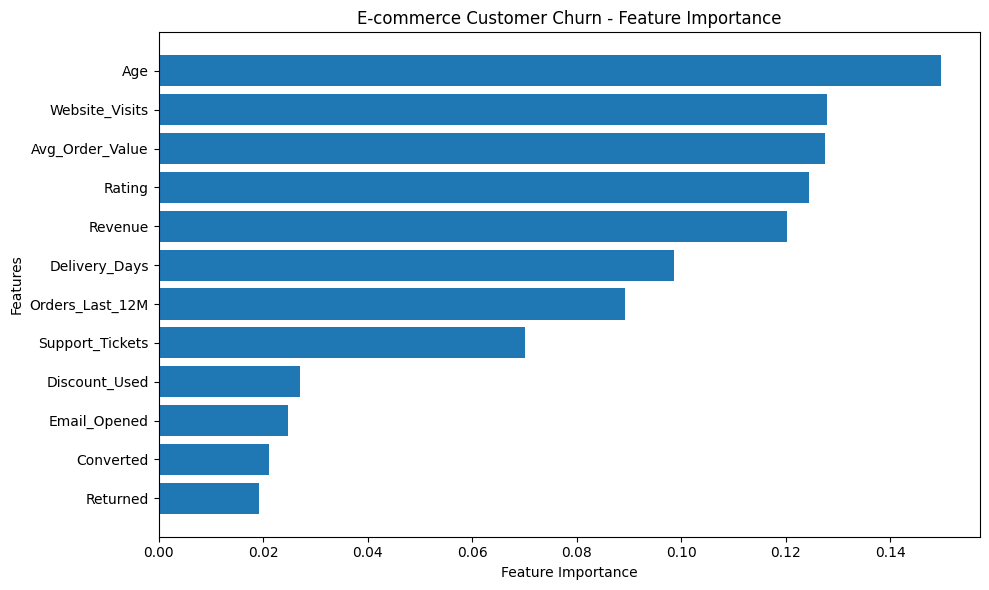

In [0]:
import matplotlib.pyplot as plt

# Convert Spark DataFrame to Pandas for visualization
importance_pd = importance_df.toPandas()

importance_pd = importance_pd.sort_values(
    by="Importance", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    importance_pd["Feature"],
    importance_pd["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("E-commerce Customer Churn - Feature Importance")
plt.tight_layout()
plt.show()

In [0]:
print("===== MODEL PERFORMANCE SUMMARY =====")

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(auc, 4))

print("\n===== PREDICTION DISTRIBUTION =====")

rf_predictions.groupBy("prediction").count().show()

print("\n===== ACTUAL CHURN DISTRIBUTION =====")

rf_predictions.groupBy("churn").count().show()

===== MODEL PERFORMANCE SUMMARY =====
Accuracy : 0.5005
Precision: 0.5001
Recall   : 0.5005
F1 Score : 0.4948
ROC-AUC  : 0.5073

===== PREDICTION DISTRIBUTION =====
+----------+-----+
|prediction|count|
+----------+-----+
|       1.0| 1137|
|       0.0| 1750|
+----------+-----+


===== ACTUAL CHURN DISTRIBUTION =====
+-----+-----+
|churn|count|
+-----+-----+
|    1| 1437|
|    0| 1450|
+-----+-----+



In [0]:
print("===== LABEL DISTRIBUTION =====")

train_df.groupBy("churn").count().show()
test_df.groupBy("churn").count().show()

print("===== FEATURE VECTOR CHECK =====")

train_df.select("features", "churn").show(
    5, truncate=False
)

print("===== MODEL CONFIGURATION =====")

print(final_rf.getNumTrees())
print(final_rf.getFeatureSubsetStrategy())

===== LABEL DISTRIBUTION =====
+-----+-----+
|churn|count|
+-----+-----+
|    1| 5964|
|    0| 6043|
+-----+-----+

+-----+-----+
|churn|count|
+-----+-----+
|    1| 1437|
|    0| 1450|
+-----+-----+

===== FEATURE VECTOR CHECK =====
+----------------------------------------------------+-----+
|features                                            |churn|
+----------------------------------------------------+-----+
|(12,[0,1,3,8,9,11],[19.0,3.0,17.0,14367.12,6.0,3.3])|1    |
|(12,[0,1,3,8,9,11],[20.0,8.0,10.0,44302.56,2.0,2.7])|0    |
|(12,[0,1,3,8,9,11],[35.0,9.0,7.0,17166.87,3.0,3.0]) |0    |
|(12,[0,1,3,8,9,11],[47.0,2.0,13.0,11010.98,6.0,2.7])|1    |
|(12,[0,1,3,8,9,11],[50.0,4.0,12.0,9128.16,5.0,5.0]) |1    |
+----------------------------------------------------+-----+
only showing top 5 rows
===== MODEL CONFIGURATION =====
50
auto


In [0]:
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator

print("===== RANDOM FOREST CONFIGURATION =====")

print("Current trees:", final_rf.getNumTrees())
print("Feature subset:", final_rf.getFeatureSubsetStrategy())
print("Max depth:", final_rf.getMaxDepth())

print("\n===== TRAINING DATA CHECK =====")

train_df.groupBy("churn").count().show()

print("===== TEST DATA CHECK =====")

test_df.groupBy("churn").count().show()

===== RANDOM FOREST CONFIGURATION =====
Current trees: 50
Feature subset: auto
Max depth: 10

===== TRAINING DATA CHECK =====
+-----+-----+
|churn|count|
+-----+-----+
|    1| 5964|
|    0| 6043|
+-----+-----+

===== TEST DATA CHECK =====
+-----+-----+
|churn|count|
+-----+-----+
|    1| 1437|
|    0| 1450|
+-----+-----+



In [0]:
print("===== RANDOM FOREST CONFIGURATION =====")

print("Number of trees:", final_rf.getNumTrees())
print("Feature subset strategy:",
      final_rf.getFeatureSubsetStrategy())
print("Maximum depth:", final_rf.getMaxDepth())

print("\n===== TRAINED MODEL CHECK =====")
print("Model type:", type(rf_model))

===== RANDOM FOREST CONFIGURATION =====
Number of trees: 50
Feature subset strategy: auto
Maximum depth: 10

===== TRAINED MODEL CHECK =====
Model type: <class 'pyspark.ml.classification.RandomForestClassificationModel'>


In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

print("===== RANDOM FOREST MODEL EVALUATION =====")

evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
)

accuracy = evaluator.evaluate(rf_predictions)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy Percentage: {accuracy * 100:.2f}%")

print("\n===== PREDICTION DISTRIBUTION =====")
rf_predictions.groupBy("prediction").count().show()

print("\n===== ACTUAL CHURN DISTRIBUTION =====")
rf_predictions.groupBy("churn").count().show()

===== RANDOM FOREST MODEL EVALUATION =====
Accuracy: 0.5005
Accuracy Percentage: 50.05%

===== PREDICTION DISTRIBUTION =====
+----------+-----+
|prediction|count|
+----------+-----+
|       1.0| 1137|
|       0.0| 1750|
+----------+-----+


===== ACTUAL CHURN DISTRIBUTION =====
+-----+-----+
|churn|count|
+-----+-----+
|    1| 1437|
|    0| 1450|
+-----+-----+



In [0]:
from pyspark.sql.functions import col

print("===== CONFUSION MATRIX =====")

rf_predictions.groupBy("churn", "prediction") \
    .count() \
    .orderBy("churn", "prediction") \
    .show()

===== CONFUSION MATRIX =====
+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0|  879|
|    0|       1.0|  571|
|    1|       0.0|  871|
|    1|       1.0|  566|
+-----+----------+-----+



In [0]:
print("===== AVAILABLE DATA VARIABLES =====")

for name in [
    "train_df",
    "train_data",
    "train_df_final",
    "train_data_final",
    "train",
    "test_df",
    "rf_predictions"
]:
    if name in globals():
        print(name, "FOUND")

===== AVAILABLE DATA VARIABLES =====
train_df FOUND
test_df FOUND
rf_predictions FOUND


In [0]:
print("===== TRAIN DATA CHECK =====")

print("Training rows:", train_df.count())

print("Training schema:")
train_df.printSchema()

print("Training data sample:")
train_df.show(5, truncate=False)

===== TRAIN DATA CHECK =====
Training rows: 12007
Training schema:
root
 |-- features: vectorudt (nullable = true)
 |-- churn: integer (nullable = false)

Training data sample:
+----------------------------------------------------+-----+
|features                                            |churn|
+----------------------------------------------------+-----+
|(12,[0,1,3,8,9,11],[19.0,3.0,17.0,14367.12,6.0,3.3])|1    |
|(12,[0,1,3,8,9,11],[20.0,8.0,10.0,44302.56,2.0,2.7])|0    |
|(12,[0,1,3,8,9,11],[35.0,9.0,7.0,17166.87,3.0,3.0]) |0    |
|(12,[0,1,3,8,9,11],[47.0,2.0,13.0,11010.98,6.0,2.7])|1    |
|(12,[0,1,3,8,9,11],[50.0,4.0,12.0,9128.16,5.0,5.0]) |1    |
+----------------------------------------------------+-----+
only showing top 5 rows


In [0]:
from pyspark.ml.functions import vector_to_array

print("===== FEATURE VECTOR LENGTH =====")

train_df.select(
    vector_to_array("features").alias("feature_array")
).selectExpr(
    "size(feature_array) as total_features"
).show()

print("===== FEATURE VECTOR SAMPLE =====")

train_df.select(
    vector_to_array("features").alias("feature_array"),
    "churn"
).show(5, truncate=False)

===== FEATURE VECTOR LENGTH =====
+--------------+
|total_features|
+--------------+
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
+--------------+
only showing top 20 rows
===== FEATURE VECTOR SAMPLE =====
+-------------------------------------------------------------------+-----+
|feature_array                                                      |churn|
+-------------------------------------------------------------------+-----+
|[19.0, 3.0, 0.0, 17.0, 0.0, 0.0, 0.0, 0.0, 14367.12, 6.0, 0.0, 3.3]|1    |
|[20.0, 8.0, 0.0, 10.0, 0.0, 0.0, 0.0, 0.0, 44302.56, 2.0, 0.0, 2.7]|0    |
|[35.0, 9.0, 0.0, 7.0, 0.0, 0.0, 0.0, 0.0, 17166.87, 3.0, 0.0, 3.0] |0    |
|[47.0, 2.0, 0.0, 13.0, 0.0, 0.0, 0.0, 0.0,

In [0]:
from pyspark.ml.functions import vector_to_array

print("===== FEATURE VECTOR LENGTH =====")

train_df.select(
    vector_to_array("features").alias("feature_array")
).selectExpr(
    "size(feature_array) as total_features"
).show()

print("===== FEATURE VECTOR SAMPLE =====")

train_df.select(
    vector_to_array("features").alias("feature_array"),
    "churn"
).show(5, truncate=False)

===== FEATURE VECTOR LENGTH =====
+--------------+
|total_features|
+--------------+
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
|            12|
+--------------+
only showing top 20 rows
===== FEATURE VECTOR SAMPLE =====
+-------------------------------------------------------------------+-----+
|feature_array                                                      |churn|
+-------------------------------------------------------------------+-----+
|[19.0, 3.0, 0.0, 17.0, 0.0, 0.0, 0.0, 0.0, 14367.12, 6.0, 0.0, 3.3]|1    |
|[20.0, 8.0, 0.0, 10.0, 0.0, 0.0, 0.0, 0.0, 44302.56, 2.0, 0.0, 2.7]|0    |
|[35.0, 9.0, 0.0, 7.0, 0.0, 0.0, 0.0, 0.0, 17166.87, 3.0, 0.0, 3.0] |0    |
|[47.0, 2.0, 0.0, 13.0, 0.0, 0.0, 0.0, 0.0,

In [0]:
from pyspark.ml.functions import vector_to_array

print("===== FEATURE VECTOR SAMPLE =====")

train_df.select(
    vector_to_array("features").alias("feature_array"),
    "churn"
).show(5, truncate=False)

print("===== CHURN LABEL DISTRIBUTION =====")

train_df.groupBy("churn").count().show()

===== FEATURE VECTOR SAMPLE =====
+-------------------------------------------------------------------+-----+
|feature_array                                                      |churn|
+-------------------------------------------------------------------+-----+
|[19.0, 3.0, 0.0, 17.0, 0.0, 0.0, 0.0, 0.0, 14367.12, 6.0, 0.0, 3.3]|1    |
|[20.0, 8.0, 0.0, 10.0, 0.0, 0.0, 0.0, 0.0, 44302.56, 2.0, 0.0, 2.7]|0    |
|[35.0, 9.0, 0.0, 7.0, 0.0, 0.0, 0.0, 0.0, 17166.87, 3.0, 0.0, 3.0] |0    |
|[47.0, 2.0, 0.0, 13.0, 0.0, 0.0, 0.0, 0.0, 11010.98, 6.0, 0.0, 2.7]|1    |
|[50.0, 4.0, 0.0, 12.0, 0.0, 0.0, 0.0, 0.0, 9128.16, 5.0, 0.0, 5.0] |1    |
+-------------------------------------------------------------------+-----+
only showing top 5 rows
===== CHURN LABEL DISTRIBUTION =====
+-----+-----+
|churn|count|
+-----+-----+
|    1| 5964|
|    0| 6043|
+-----+-----+



In [0]:
print("===== MODEL PREDICTION CHECK =====")

print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

print("===== ACTUAL VS PREDICTED =====")

rf_predictions.select(
    "churn",
    "prediction"
).show(10, truncate=False)

print("===== PREDICTION COUNTS =====")

rf_predictions.groupBy(
    "prediction"
).count().show()

===== MODEL PREDICTION CHECK =====
Training rows: 12007
Testing rows: 2887
===== ACTUAL VS PREDICTED =====
+-----+----------+
|churn|prediction|
+-----+----------+
|0    |0.0       |
|0    |0.0       |
|1    |1.0       |
|0    |1.0       |
|1    |1.0       |
|0    |1.0       |
|0    |1.0       |
|0    |1.0       |
|0    |1.0       |
|0    |1.0       |
+-----+----------+
only showing top 10 rows
===== PREDICTION COUNTS =====
+----------+-----+
|prediction|count|
+----------+-----+
|       1.0| 1137|
|       0.0| 1750|
+----------+-----+



In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator

print("===== FINAL MODEL EVALUATION =====")

accuracy_eval = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
)

f1_eval = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
)

auc_eval = BinaryClassificationEvaluator(
    labelCol="churn",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)


print("Accuracy:", round(accuracy_eval.evaluate(rf_predictions), 4))
print("F1 Score:", round(f1_eval.evaluate(rf_predictions), 4))
print("ROC-AUC:", round(auc_eval.evaluate(rf_predictions), 4))

print("===== PREDICTION DISTRIBUTION =====")
rf_predictions.groupBy("prediction").count().show()

print("===== CONFUSION MATRIX =====")
rf_predictions.groupBy(
    "churn", "prediction"
).count().orderBy(
    "churn", "prediction"
).show()

===== FINAL MODEL EVALUATION =====
Accuracy: 0.5005
F1 Score: 0.4948
ROC-AUC: 0.5073
===== PREDICTION DISTRIBUTION =====
+----------+-----+
|prediction|count|
+----------+-----+
|       1.0| 1137|
|       0.0| 1750|
+----------+-----+

===== CONFUSION MATRIX =====
+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0|  879|
|    0|       1.0|  571|
|    1|       0.0|  871|
|    1|       1.0|  566|
+-----+----------+-----+



In [0]:
spark.sql("SHOW TABLES").show(100, False)

+--------+---------------------------------+-----------+
|database|tableName                        |isTemporary|
+--------+---------------------------------+-----------+
|default |churn_final_predictions          |false      |
|default |clean_people                     |false      |
|default |department_data                  |false      |
|default |department_lookup                |false      |
|default |department_summary               |false      |
|default |ecommerce_final_churn_predictions|false      |
|default |my_data                          |false      |
|default |people_clean                     |false      |
|default |people_pipeline                  |false      |
|default |people_with_department           |false      |
|default |people_with_department_v2        |false      |
|default |quality_people                   |false      |
|default |quality_test                     |false      |
|default |sales                            |false      |
|default |transformed_people   

In [0]:
spark.sql("SHOW TABLES IN default").show(200, False)

+--------+---------------------------------+-----------+
|database|tableName                        |isTemporary|
+--------+---------------------------------+-----------+
|default |churn_final_predictions          |false      |
|default |clean_people                     |false      |
|default |department_data                  |false      |
|default |department_lookup                |false      |
|default |department_summary               |false      |
|default |ecommerce_final_churn_predictions|false      |
|default |my_data                          |false      |
|default |people_clean                     |false      |
|default |people_pipeline                  |false      |
|default |people_with_department           |false      |
|default |people_with_department_v2        |false      |
|default |quality_people                   |false      |
|default |quality_test                     |false      |
|default |sales                            |false      |
|default |transformed_people   

In [0]:
print(spark.catalog.listTables("default"))

[Table(name='churn_final_predictions', catalog='workspace', namespace=['default'], description=None, tableType='MANAGED', isTemporary=False), Table(name='clean_people', catalog='workspace', namespace=['default'], description=None, tableType='MANAGED', isTemporary=False), Table(name='department_data', catalog='workspace', namespace=['default'], description=None, tableType='MANAGED', isTemporary=False), Table(name='department_lookup', catalog='workspace', namespace=['default'], description=None, tableType='MANAGED', isTemporary=False), Table(name='department_summary', catalog='workspace', namespace=['default'], description=None, tableType='MANAGED', isTemporary=False), Table(name='ecommerce_final_churn_predictions', catalog='workspace', namespace=['default'], description=None, tableType='MANAGED', isTemporary=False), Table(name='my_data', catalog='workspace', namespace=['default'], description=None, tableType='MANAGED', isTemporary=False), Table(name='people_clean', catalog='workspace', 

In [0]:
tables = spark.catalog.listTables("default")

for t in tables:
    if "ecommerce" in t.name.lower() or "customer" in t.name.lower():
        print(t.name)

ecommerce_final_churn_predictions


In [0]:
spark.sql("SHOW SCHEMAS").show(100, False)

+------------------+
|databaseName      |
+------------------+
|default           |
|information_schema|
+------------------+



In [0]:
display(dbutils.fs.ls("dbfs:/"))

path,name,size,modificationTime
dbfs:/Volumes/,Volumes/,0,0
dbfs:/Workspace/,Workspace/,0,0
dbfs:/databricks-datasets/,databricks-datasets/,0,0


In [0]:
display(dbutils.fs.ls("dbfs:/Workspace/"))

path,name,size,modificationTime
dbfs:/Workspace/.rm-rf-guard,.rm-rf-guard,0,1791539812407
dbfs:/Workspace/Repos/,Repos/,4096,1791540946128
dbfs:/Workspace/Shared/,Shared/,4096,1791540946128
dbfs:/Workspace/Users/,Users/,4096,1791540946128
dbfs:/Workspace/__databricks_jobs_tmp/,__databricks_jobs_tmp/,4096,1791540946128


In [0]:
display(dbutils.fs.ls("dbfs:/Workspace/Users/"))

path,name,size,modificationTime
dbfs:/Workspace/Users/Groups/,Groups/,4096,1791540994682
dbfs:/Workspace/Users/pushpendrakushwaha022@gmail.com/,pushpendrakushwaha022@gmail.com/,4096,1791540994682


In [0]:
display(dbutils.fs.ls("dbfs:/Workspace/Users/pushpendrakushwaha022@gmail.com/"))

path,name,size,modificationTime
dbfs:/Workspace/Users/pushpendrakushwaha022@gmail.com/.conversations/,.conversations/,4096,1791541051358
dbfs:/Workspace/Users/pushpendrakushwaha022@gmail.com/.db_internal/,.db_internal/,4096,1791541051358
dbfs:/Workspace/Users/pushpendrakushwaha022@gmail.com/Drafts/,Drafts/,4096,1791541051358
dbfs:/Workspace/Users/pushpendrakushwaha022@gmail.com/Ecomerce_Customer_Analytics_prediction.ipynb,Ecomerce_Customer_Analytics_prediction.ipynb,219280,1791541052542
dbfs:/Workspace/Users/pushpendrakushwaha022@gmail.com/Explore_ecommerce_customer_master_raw_1_csv_python_af9a9488.ipynb,Explore_ecommerce_customer_master_raw_1_csv_python_af9a9488.ipynb,5906,1791480200722
dbfs:/Workspace/Users/pushpendrakushwaha022@gmail.com/New Dashboard 2026-10-07 19:17:18.lvdash.json,New Dashboard 2026-10-07 19:17:18.lvdash.json,13734,1791396938649
dbfs:/Workspace/Users/pushpendrakushwaha022@gmail.com/New Pipeline 2026-10-07 00:29/,New Pipeline 2026-10-07 00:29/,4096,1791541051358
dbfs:/Workspace/Users/pushpendrakushwaha022@gmail.com/New Pipeline 2026-10-09 14:23/,New Pipeline 2026-10-09 14:23/,4096,1791541051358


In [0]:
from sklearn.metrics import classification_report, confusion_matrix

# Use the existing predictions if available
if "final_predictions" in globals():
    pred_df = final_predictions
elif "final_rf" in globals():
    pred_df = final_rf.transform(test_df)
else:
    pred_df = rf_model.transform(test_df)

# Evaluate both churn classes
results = pred_df.select("churn", "prediction").toPandas()

print("Classification Report:")
print(
    classification_report(
        results["churn"],
        results["prediction"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(results["churn"], results["prediction"]))

---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
File <command-5920375529720406>, line 9
      7     pred_df = final_rf.transform(test_df)
      8 else:
----> 9     pred_df = rf_model.transform(test_df)
     11 # Evaluate both churn classes
     12 results = pred_df.select("churn", "prediction").toPandas()

NameError: name 'rf_model' is not defined

In [0]:
print("Available ML variables:")

for name in [
    "rf_model",
    "final_rf",
    "final_predictions",
    "test_df",
    "predictions",
    "y_test",
    "X_test",
    "model",
    "pred_df",
    "results"
]:
    if name in globals():
        print(name, "FOUND")

Available ML variables:


In [0]:
# Step 1: Check available tables
print("Available tables:")

spark.sql("SHOW TABLES").show(
    truncate=False
)

Available tables:
+--------+---------------------------------+-----------+
|database|tableName                        |isTemporary|
+--------+---------------------------------+-----------+
|default |churn_final_predictions          |false      |
|default |clean_people                     |false      |
|default |department_data                  |false      |
|default |department_lookup                |false      |
|default |department_summary               |false      |
|default |ecommerce_customer_cleaned       |false      |
|default |ecommerce_final_churn_predictions|false      |
|default |my_data                          |false      |
|default |people_clean                     |false      |
|default |people_pipeline                  |false      |
|default |people_with_department           |false      |
|default |people_with_department_v2        |false      |
|default |quality_people                   |false      |
|default |quality_test                     |false      |
|default |sal

In [0]:
# Step 2: Load cleaned ecommerce data
df = spark.table("default.ecommerce_customer_cleaned")

print("Total rows:", df.count())
print("Total columns:", len(df.columns))

print("\nAvailable columns:")
print(df.columns)

display(df.limit(5))

Total rows: 15000
Total columns: 21

Available columns:
['Customer_ID', 'Age', 'City', 'Gender', 'Category', 'Acquisition_Channel', 'Device', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Days_Since_Last_Order', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Campaign_Group', 'Converted', 'Revenue', 'Churned', 'Delivery_Days', 'Returned', 'Rating']


Customer_ID,Age,City,Gender,Category,Acquisition_Channel,Device,Orders_Last_12M,Avg_Order_Value,Website_Visits,Days_Since_Last_Order,Discount_Used,Support_Tickets,Email_Opened,Campaign_Group,Converted,Revenue,Churned,Delivery_Days,Returned,Rating
10571,18.0,Hyderabad,Female,Fashion,Instagram,Desktop,4.0,2387.42,7.0,126,1.0,2.0,1.0,A,0.0,9549.68,1,5.0,0.0,3.5
10658,47.0,Hyderabad,Female,Sports,Google Ads,Desktop,2.0,2412.07,8.0,115,1.0,0.0,0.0,A,0.0,4824.14,0,1.0,0.0,4.2
12183,38.0,Kolkata,Female,Fashion,Google Ads,Desktop,6.0,3374.44,9.0,24,0.0,3.0,1.0,A,0.0,20246.64,0,5.0,0.0,3.8
15585,36.0,Hyderabad,Male,Fashion,Google Ads,Mobile,5.0,2828.75,11.0,58,1.0,2.0,1.0,B,1.0,14143.75,0,4.0,1.0,3.3
15636,46.0,Mumbai,Female,Fashion,Google Ads,Desktop,10.0,3706.94,10.0,19,1.0,2.0,1.0,A,0.0,37069.4,0,5.0,0.0,4.5


In [0]:
# Step 3: Check Churn target distribution

from pyspark.sql import functions as F

df.groupBy("Churn").count().orderBy("Churn").show()

print("Churn column data type:")
print(dict(df.dtypes)["Churn"])

print("Missing values in Churn:")
df.filter(F.col("Churn").isNull()).count()

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-5920375529720410>, line 5
      1 # Step 3: Check Churn target distribution
      3 from pyspark.sql import functions as F
----> 5 df.groupBy("Churn").count().orderBy("Churn").show()
      7 print("Churn column data type:")
      8 print(dict(df.dtypes)["Churn"])

File <command-5920375529720409>, line 2
      1 # Step 2: Load cleaned ecommerce data
----> 2 df = spark.table("default.ecommerce_customer_cleaned")
      4 print("Total rows:", df.count())
      5 print("Total columns:", len(df.columns))

AnalysisException: [UNRESOLVED_COLUMN.WITH_SUGGESTION] A column, variable, or function parameter with name `Churn` cannot be resolved. Did you mean one of the following? [`Churned`, `Age`, `City`, `Gender`, `Rating`]. SQLSTATE: 42703;
'Sort ['Churn ASC NULLS FIRST], true
+- 'Aggregate ['Churn], ['Churn, count(1) AS count#10600L

In [0]:
# ==========================================
# ECOMMERCE PROJECT - STATUS CHECKER
# ==========================================

from pyspark.sql import functions as F

print("=" * 55)
print("ECOMMERCE PROJECT STATUS REPORT")
print("=" * 55)

# STEP 1: Current notebook variables
print("\n1. CURRENT ML VARIABLES")

check_vars = [
    "df", "data", "train_df", "test_df",
    "X", "y", "X_train", "X_test",
    "y_train", "y_test", "model",
    "model1", "predictions", "pred_df",
    "results", "final_rf", "tuned_model",
    "accuracy", "precision", "recall",
    "f1", "roc_auc"
]

for name in check_vars:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: AVAILABLE ({type(obj).__name__})")
    else:
        print(f"{name}: NOT AVAILABLE")

# STEP 2: Tables in default schema
print("\n2. AVAILABLE TABLES")

tables = spark.sql("SHOW TABLES IN default").collect()

for row in tables:
    print(f"- {row['tableName']}")

# STEP 3: Check cleaned dataset
print("\n3. CLEANED DATASET STATUS")

table_name = "default.ecommerce_customer_cleaned"

try:
    df_status = spark.table(table_name)

    print("Table: ", table_name)
    print("Rows: ", df_status.count())
    print("Columns: ", len(df_status.columns))
    print("Column names: ", df_status.columns)

    print("\nMissing values by column:")
    df_status.select([
        F.sum(
            F.when(F.col(c).isNull(), 1).otherwise(0)
        ).alias(c)
        for c in df_status.columns
    ]).show(truncate=False)

    if "Churn" in df_status.columns:
        print("\n4. CHURN TARGET DISTRIBUTION")
        df_status.groupBy("Churn").count().orderBy("Churn").show()

    print("\n5. SAMPLE DATA")
    display(df_status.limit(5))

except Exception as e:
    print("Cleaned table check failed:")
    print(str(e)[:1000])

# STEP 6: Check important ML output tables
print("\n6. ML OUTPUT TABLES")

ml_tables = [
    "churn_final_predictions",
    "ecommerce_final_churn_predictions",
    "churn_final_predictions"
]

for name in set(ml_tables):
    try:
        check_df = spark.table("default." + name)
        print(f"{name}: EXISTS | Rows = {check_df.count()}")
    except Exception:
        print(f"{name}: NOT FOUND or NOT ACCESSIBLE")

print("\n" + "=" * 55)
print("STATUS REPORT FINISHED")
print("=" * 55)

ECOMMERCE PROJECT STATUS REPORT

1. CURRENT ML VARIABLES
df: AVAILABLE (DataFrame)
data: NOT AVAILABLE
train_df: NOT AVAILABLE
test_df: NOT AVAILABLE
X: NOT AVAILABLE
y: NOT AVAILABLE
X_train: NOT AVAILABLE
X_test: NOT AVAILABLE
y_train: NOT AVAILABLE
y_test: NOT AVAILABLE
model: NOT AVAILABLE
model1: NOT AVAILABLE
predictions: NOT AVAILABLE
pred_df: NOT AVAILABLE
results: NOT AVAILABLE
final_rf: NOT AVAILABLE
tuned_model: NOT AVAILABLE
accuracy: NOT AVAILABLE
precision: NOT AVAILABLE
recall: NOT AVAILABLE
f1: NOT AVAILABLE
roc_auc: NOT AVAILABLE

2. AVAILABLE TABLES
- churn_final_predictions
- clean_people
- department_data
- department_lookup
- department_summary
- ecommerce_customer_cleaned
- ecommerce_final_churn_predictions
- my_data
- people_clean
- people_pipeline
- people_with_department
- people_with_department_v2
- quality_people
- quality_test
- sales
- transformed_people

3. CLEANED DATASET STATUS
Table:  default.ecommerce_customer_cleaned
Rows:  15000
Columns:  21
Column n

Customer_ID,Age,City,Gender,Category,Acquisition_Channel,Device,Orders_Last_12M,Avg_Order_Value,Website_Visits,Days_Since_Last_Order,Discount_Used,Support_Tickets,Email_Opened,Campaign_Group,Converted,Revenue,Churned,Delivery_Days,Returned,Rating
10571,18.0,Hyderabad,Female,Fashion,Instagram,Desktop,4.0,2387.42,7.0,126,1.0,2.0,1.0,A,0.0,9549.68,1,5.0,0.0,3.5
10658,47.0,Hyderabad,Female,Sports,Google Ads,Desktop,2.0,2412.07,8.0,115,1.0,0.0,0.0,A,0.0,4824.14,0,1.0,0.0,4.2
12183,38.0,Kolkata,Female,Fashion,Google Ads,Desktop,6.0,3374.44,9.0,24,0.0,3.0,1.0,A,0.0,20246.64,0,5.0,0.0,3.8
15585,36.0,Hyderabad,Male,Fashion,Google Ads,Mobile,5.0,2828.75,11.0,58,1.0,2.0,1.0,B,1.0,14143.75,0,4.0,1.0,3.3
15636,46.0,Mumbai,Female,Fashion,Google Ads,Desktop,10.0,3706.94,10.0,19,1.0,2.0,1.0,A,0.0,37069.4,0,5.0,0.0,4.5



6. ML OUTPUT TABLES
ecommerce_final_churn_predictions: EXISTS | Rows = 2942
churn_final_predictions: EXISTS | Rows = 2942

STATUS REPORT FINISHED


In [0]:
from pyspark.sql import functions as F

print("=" * 50)
print("ML PROJECT AUDIT")
print("=" * 50)

# 1. Check target distribution in cleaned data
df = spark.table("default.ecommerce_customer_cleaned")

print("\n1. CHURN DISTRIBUTION")
df.groupBy("Churn").count().orderBy("Churn").show()

# 2. Check missing values
print("\n2. COLUMNS WITH MISSING VALUES")

missing = df.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in df.columns
]).first().asDict()

for col_name, count in missing.items():
    if count and count > 0:
        print(f"{col_name}: {count} missing")

# 3. Inspect existing ML prediction tables
print("\n3. ML PREDICTION TABLES")

for name in [
    "ecommerce_final_churn_predictions",
    "churn_final_predictions"
]:
    try:
        result_df = spark.table("default." + name)

        print(f"\nTABLE: {name}")
        print("Rows:", result_df.count())
        print("Columns:", result_df.columns)

        result_df.printSchema()
        display(result_df.limit(5))

        # Check likely prediction columns
        for col_name in result_df.columns:
            if col_name.lower() in [
                "churn", "prediction", "final_prediction",
                "label", "probability"
            ]:
                print(f"\nDistribution: {col_name}")
                result_df.groupBy(col_name).count().show(20, False)

    except Exception as e:
        print(f"{name}: Check failed - {str(e)[:300]}")

print("\nAUDIT FINISHED")

ML PROJECT AUDIT

1. CHURN DISTRIBUTION


---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-5920375529720412>, line 11
      8 df = spark.table("default.ecommerce_customer_cleaned")
     10 print("\n1. CHURN DISTRIBUTION")
---> 11 df.groupBy("Churn").count().orderBy("Churn").show()
     13 # 2. Check missing values
     14 print("\n2. COLUMNS WITH MISSING VALUES")

File <command-5920375529720412>, line 8
      5 print("=" * 50)
      7 # 1. Check target distribution in cleaned data
----> 8 df = spark.table("default.ecommerce_customer_cleaned")
     10 print("\n1. CHURN DISTRIBUTION")
     11 df.groupBy("Churn").count().orderBy("Churn").show()

AnalysisException: [UNRESOLVED_COLUMN.WITH_SUGGESTION] A column, variable, or function parameter with name `Churn` cannot be resolved. Did you mean one of the following? [`Churned`, `Age`, `City`, `Gender`, `Rating`]. SQLSTATE: 42703;
'Sort ['Churn ASC NULLS FIRST], true
+-

In [0]:
# STEP 1: Inspect actual column names

df = spark.table("default.ecommerce_customer_cleaned")

print("TOTAL ROWS:", df.count())
print("TOTAL COLUMNS:", len(df.columns))

print("\nACTUAL COLUMN NAMES:")
for i, col_name in enumerate(df.columns, 1):
    print(i, repr(col_name))

print("\nCOLUMNS CONTAINING CHURN:")
print([c for c in df.columns if "churn" in c.lower()])

TOTAL ROWS: 15000
TOTAL COLUMNS: 21

ACTUAL COLUMN NAMES:
1 'Customer_ID'
2 'Age'
3 'City'
4 'Gender'
5 'Category'
6 'Acquisition_Channel'
7 'Device'
8 'Orders_Last_12M'
9 'Avg_Order_Value'
10 'Website_Visits'
11 'Days_Since_Last_Order'
12 'Discount_Used'
13 'Support_Tickets'
14 'Email_Opened'
15 'Campaign_Group'
16 'Converted'
17 'Revenue'
18 'Churned'
19 'Delivery_Days'
20 'Returned'
21 'Rating'

COLUMNS CONTAINING CHURN:
['Churned']


In [0]:
# STEP 2: Identify the correct target column

df = spark.table("default.ecommerce_customer_cleaned")

print("TARGET / LABEL COLUMNS:")
for c in df.columns:
    if any(word in c.lower() for word in
           ["churn", "convert", "return", "purchase"]):
        print(repr(c), " | ", df.select(c).distinct().limit(10).collect())

print("\nLAST 10 COLUMN NAMES:")
print(df.columns[-10:])

TARGET / LABEL COLUMNS:
'Converted'  |  [Row(Converted=0.0), Row(Converted=1.0)]
'Churned'  |  [Row(Churned=1), Row(Churned=0)]
'Returned'  |  [Row(Returned=0.0), Row(Returned=1.0)]

LAST 10 COLUMN NAMES:
['Discount_Used', 'Support_Tickets', 'Email_Opened', 'Campaign_Group', 'Converted', 'Revenue', 'Churned', 'Delivery_Days', 'Returned', 'Rating']


In [0]:
from pyspark.sql import functions as F

# Load cleaned dataset
df = spark.table("default.ecommerce_customer_cleaned")

# Check target distribution
print("Churned column distribution:")
df.groupBy("Churned").count().show()

# Convert target into numeric labels
df_ml = df.withColumn(
    "label",
    F.when(F.col("Churned") == True, 1).otherwise(0)
)

print("ML dataset rows:", df_ml.count())
df_ml.select("Churned", "label").show(10)

Churned column distribution:
+-------+-----+
|Churned|count|
+-------+-----+
|      1| 1608|
|      0|13392|
+-------+-----+



---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-5920375529720415>, line 16
     10 # Convert target into numeric labels
     11 df_ml = df.withColumn(
     12     "label",
     13     F.when(F.col("Churned") == True, 1).otherwise(0)
     14 )
---> 16 print("ML dataset rows:", df_ml.count())
     17 df_ml.select("Churned", "label").show(10)

File <command-5920375529720415>, line 11
      8 df.groupBy("Churned").count().show()
     10 # Convert target into numeric labels
---> 11 df_ml = df.withColumn(
     12     "label",
     13     F.when(F.col("Churned") == True, 1).otherwise(0)
     14 )
     16 print("ML dataset rows:", df_ml.count())
     17 df_ml.select("Churned", "label").show(10)

File <command-5920375529720415>, line 4
      1 from pyspark.sql import functions as F
      3 # Load cleaned dataset
----> 4 df = spark.table("default.ecommerce_customer_cleaned")
    

In [0]:
from pyspark.sql import functions as F

df = spark.table("default.ecommerce_customer_cleaned")

# Check actual target values
print("Churned distribution:")
df.groupBy("Churned").count().show()

# Integer 0/1 target
df_ml = df.withColumn(
    "label",
    F.col("Churned").cast("double")
)

print("ML dataset rows:", df_ml.count())

df_ml.select("Churned", "label").show(10)

print("Label distribution:")
df_ml.groupBy("label").count().show()

Churned distribution:
+-------+-----+
|Churned|count|
+-------+-----+
|      1| 1608|
|      0|13392|
+-------+-----+

ML dataset rows: 15000
+-------+-----+
|Churned|label|
+-------+-----+
|      1|  1.0|
|      0|  0.0|
|      0|  0.0|
|      0|  0.0|
|      0|  0.0|
|      0|  0.0|
|      0|  0.0|
|      0|  0.0|
|      0|  0.0|
|      0|  0.0|
+-------+-----+
only showing top 10 rows
Label distribution:
+-----+-----+
|label|count|
+-----+-----+
|  1.0| 1608|
|  0.0|13392|
+-----+-----+



In [0]:
from pyspark.sql import functions as F

# Select useful customer features
feature_cols = [
    "Age",
    "Orders_Last_12M",
    "Avg_Order_Value",
    "Website_Visits",
    "Days_Since_Last_Order",
    "Discount_Used",
    "Support_Tickets",
    "Email_Opened",
    "Delivery_Days",
    "Rating"
]

# Check which columns actually exist
available_features = [
    c for c in feature_cols if c in df_ml.columns
]

print("Available features:", available_features)
print("Number of features:", len(available_features))

# Preview selected features and label
df_ml.select(
    *available_features, "label"
).show(10, truncate=False)

Available features: ['Age', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Days_Since_Last_Order', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Delivery_Days', 'Rating']
Number of features: 10
+----+---------------+---------------+--------------+---------------------+-------------+---------------+------------+-------------+------+-----+
|Age |Orders_Last_12M|Avg_Order_Value|Website_Visits|Days_Since_Last_Order|Discount_Used|Support_Tickets|Email_Opened|Delivery_Days|Rating|label|
+----+---------------+---------------+--------------+---------------------+-------------+---------------+------------+-------------+------+-----+
|18.0|4.0            |2387.42        |7.0           |126                  |1.0          |2.0            |1.0         |5.0          |3.5   |1.0  |
|47.0|2.0            |2412.07        |8.0           |115                  |1.0          |0.0            |0.0         |1.0          |4.2   |0.0  |
|38.0|6.0            |3374.44        |9.0           |24    

In [0]:
from pyspark.sql import functions as F

# Check missing values in selected features and label
check_cols = available_features + ["label"]

print("MISSING VALUES CHECK:")
df_ml.select([
    F.sum(
        F.col(c).isNull().cast("int")
    ).alias(c)
    for c in check_cols
]).show(truncate=False)

print("FEATURE DATA TYPES:")
df_ml.select(*check_cols).printSchema()

print("LABEL DISTRIBUTION:")
df_ml.groupBy("label").count().show()

MISSING VALUES CHECK:
+---+---------------+---------------+--------------+---------------------+-------------+---------------+------------+-------------+------+-----+
|Age|Orders_Last_12M|Avg_Order_Value|Website_Visits|Days_Since_Last_Order|Discount_Used|Support_Tickets|Email_Opened|Delivery_Days|Rating|label|
+---+---------------+---------------+--------------+---------------------+-------------+---------------+------------+-------------+------+-----+
|225|0              |225            |225           |0                    |0            |0              |0           |0            |0     |0    |
+---+---------------+---------------+--------------+---------------------+-------------+---------------+------------+-------------+------+-----+

FEATURE DATA TYPES:
root
 |-- Age: double (nullable = true)
 |-- Orders_Last_12M: double (nullable = true)
 |-- Avg_Order_Value: double (nullable = true)
 |-- Website_Visits: double (nullable = true)
 |-- Days_Since_Last_Order: integer (nullable = true

In [0]:
from pyspark.sql import functions as F

# Check missing values in selected features and label
check_cols = available_features + ["label"]

print("MISSING VALUES CHECK:")
df_ml.select([
    F.sum(
        F.col(c).isNull().cast("int")
    ).alias(c)
    for c in check_cols
]).show(truncate=False)

print("FEATURE DATA TYPES:")
df_ml.select(*check_cols).printSchema()

print("LABEL DISTRIBUTION:")
df_ml.groupBy("label").count().show()

In [0]:
from pyspark.sql import functions as F

df_ready = df_ml.filter(F.col("label").isNotNull())

for c in available_features:
    median_value = df_ready.approxQuantile(c, [0.5], 0.01)[0]
    df_ready = df_ready.fillna({c: float(median_value)})

print("Rows after cleaning:", df_ready.count())

df_ready.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in available_features + ["label"]
]).show(truncate=False)

Rows after cleaning: 15000
+---+---------------+---------------+--------------+---------------------+-------------+---------------+------------+-------------+------+-----+
|Age|Orders_Last_12M|Avg_Order_Value|Website_Visits|Days_Since_Last_Order|Discount_Used|Support_Tickets|Email_Opened|Delivery_Days|Rating|label|
+---+---------------+---------------+--------------+---------------------+-------------+---------------+------------+-------------+------+-----+
|0  |0              |0              |0             |0                    |0            |0              |0           |0            |0     |0    |
+---+---------------+---------------+--------------+---------------------+-------------+---------------+------------+-------------+------+-----+



In [0]:
from pyspark.sql import functions as F

print("Dataset rows:", df_ready.count())

print("Label distribution:")
df_ready.groupBy("label").count().show()

print("Label data type:")
print(df_ready.schema["label"].dataType)

print("Feature count:", len(available_features))
print("Features:", available_features)

Dataset rows: 15000
Label distribution:
+-----+-----+
|label|count|
+-----+-----+
|  1.0| 1608|
|  0.0|13392|
+-----+-----+

Label data type:
DoubleType()
Feature count: 10
Features: ['Age', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Days_Since_Last_Order', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Delivery_Days', 'Rating']


In [0]:
from pyspark.sql import functions as F

# Prepare ML dataset
ml_data = df_ready.select(
    *[F.col(c).cast("double").alias(c) for c in available_features],
    F.col("label").cast("double").alias("label")
).dropna()

# Split data into training and testing
train_df, test_df = ml_data.randomSplit(
    [0.8, 0.2], seed=42
)

print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

print("Training label distribution:")
train_df.groupBy("label").count().show()

print("Testing label distribution:")
test_df.groupBy("label").count().show()

Training rows: 11927
Testing rows: 3073
Training label distribution:
+-----+-----+
|label|count|
+-----+-----+
|  1.0| 1314|
|  0.0|10613|
+-----+-----+

Testing label distribution:
+-----+-----+
|label|count|
+-----+-----+
|  1.0|  294|
|  0.0| 2779|
+-----+-----+



In [0]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# Convert features into a single vector
assembler = VectorAssembler(
    inputCols=available_features,
    outputCol="features",
    handleInvalid="skip"
)

train_ready = assembler.transform(train_df)
test_ready = assembler.transform(test_df)

# Train a simple Logistic Regression model
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=50,
    regParam=0.01
)

model = lr.fit(train_ready)

# Generate predictions
predictions = model.transform(test_ready)

print("Model training completed!")
print("Sample predictions:")
predictions.select(
    "label", "prediction", "probability"
).show(10, truncate=False)

# ROC-AUC
evaluator = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

print("ROC-AUC:", evaluator.evaluate(predictions))

Model training completed!
Sample predictions:
+-----+----------+----------------------------------------+
|label|prediction|probability                             |
+-----+----------+----------------------------------------+
|0.0  |0.0       |[0.6795350389021247,0.32046496109787526]|
|0.0  |0.0       |[0.871492610672525,0.12850738932747496] |
|0.0  |0.0       |[0.8667703321972212,0.13322966780277878]|
|0.0  |0.0       |[0.6460070504155365,0.3539929495844635] |
|0.0  |0.0       |[0.574911434767437,0.425088565232563]   |
|1.0  |0.0       |[0.9482071608882283,0.05179283911177168]|
|1.0  |0.0       |[0.7758150491559734,0.22418495084402656]|
|1.0  |0.0       |[0.7718426492770275,0.2281573507229725] |
|0.0  |0.0       |[0.8310026583155358,0.16899734168446423]|
|0.0  |0.0       |[0.9311510493670747,0.06884895063292529]|
+-----+----------+----------------------------------------+
only showing top 10 rows
ROC-AUC: 0.7491609814130713


In [0]:
from pyspark.sql import functions as F

# Confusion matrix counts
rows = predictions.groupBy(
    "label", "prediction"
).count().collect()

counts = {
    (int(r["label"]), int(r["prediction"])): r["count"]
    for r in rows
}

tn = counts.get((0, 0), 0)
fp = counts.get((0, 1), 0)
fn = counts.get((1, 0), 0)
tp = counts.get((1, 1), 0)

accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
precision = tp / max(tp + fp, 1)
recall = tp / max(tp + fn, 1)
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0
)

print("CONFUSION MATRIX")
print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

print("\nMODEL PERFORMANCE")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {evaluator.evaluate(predictions):.4f}")

CONFUSION MATRIX
True Negative: 2778
False Positive: 1
False Negative: 294
True Positive: 0

MODEL PERFORMANCE
Accuracy:  0.9040
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000
ROC-AUC:   0.7492


In [0]:
from pyspark.sql import functions as F
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# Calculate class weights from training data
label_counts = {
    int(r["label"]): r["count"]
    for r in train_df.groupBy("label").count().collect()
}

n0 = label_counts.get(0, 0)
n1 = label_counts.get(1, 0)
total = n0 + n1

if n0 == 0 or n1 == 0:
    raise ValueError("Training data must contain both label classes.")

w0 = total / (2.0 * n0)
w1 = total / (2.0 * n1)

print("Class 0 weight:", w0)
print("Class 1 weight:", w1)

# Add weights to training data
train_weighted = train_ready.withColumn(
    "classWeight",
    F.when(F.col("label") == 1.0, F.lit(w1))
     .otherwise(F.lit(w0))
)

# Train weighted Logistic Regression
lr_weighted = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    weightCol="classWeight",
    maxIter=50,
    regParam=0.01
)

model_weighted = lr_weighted.fit(train_weighted)

# Predict on the same held-out test set
predictions_weighted = model_weighted.transform(test_ready)

# Confusion matrix
rows = predictions_weighted.groupBy(
    "label", "prediction"
).count().collect()

counts = {
    (int(r["label"]), int(r["prediction"])): r["count"]
    for r in rows
}

tn = counts.get((0, 0), 0)
fp = counts.get((0, 1), 0)
fn = counts.get((1, 0), 0)
tp = counts.get((1, 1), 0)

accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
precision = tp / max(tp + fp, 1)
recall = tp / max(tp + fn, 1)
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0.0
)

evaluator = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

print("\nWEIGHTED MODEL RESULTS")
print("TN:", tn, "FP:", fp, "FN:", fn, "TP:", tp)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {evaluator.evaluate(predictions_weighted):.4f}")

Class 0 weight: 0.5619052105907849
Class 1 weight: 4.538432267884323

WEIGHTED MODEL RESULTS
TN: 1817 FP: 962 FN: 88 TP: 206
Accuracy:  0.6583
Precision: 0.1764
Recall:    0.7007
F1-score:  0.2818
ROC-AUC:   0.7483


In [0]:
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F

# Extract probability of churn (class 1)
threshold_data = predictions_weighted.withColumn(
    "churn_probability",
    vector_to_array("probability")[1]
)

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    scored = threshold_data.withColumn(
        "new_prediction",
        (F.col("churn_probability") >= threshold).cast("double")
    )

    counts = {
        (int(r["label"]), int(r["new_prediction"])): r["count"]
        for r in scored.groupBy("label", "new_prediction").count().collect()
    }

    tn = counts.get((0, 0), 0)
    fp = counts.get((0, 1), 0)
    fn = counts.get((1, 0), 0)
    tp = counts.get((1, 1), 0)

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(
        f"Threshold={threshold:.1f} | "
        f"Precision={precision:.3f} | "
        f"Recall={recall:.3f} | F1={f1:.3f}"
    )

Threshold=0.3 | Precision=0.133 | Recall=0.929 | F1=0.232
Threshold=0.4 | Precision=0.155 | Recall=0.830 | F1=0.261
Threshold=0.5 | Precision=0.176 | Recall=0.701 | F1=0.282
Threshold=0.6 | Precision=0.203 | Recall=0.541 | F1=0.295
Threshold=0.7 | Precision=0.261 | Recall=0.323 | F1=0.289


In [0]:
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array

# Use the weighted model's existing predictions
churn_results = predictions_weighted.withColumn(
    "Churn_Probability",
    vector_to_array("probability")[1]
).withColumn(
    "Churn_Prediction",
    (F.col("Churn_Probability") >= 0.6).cast("int")
)

churn_results.select(
    "label",
    "Churn_Probability",
    "Churn_Prediction"
).show(20, truncate=False)

print("Total prediction rows:", churn_results.count())

print("Churn prediction distribution:")
churn_results.groupBy("Churn_Prediction").count().show()

+-----+-------------------+----------------+
|label|Churn_Probability  |Churn_Prediction|
+-----+-------------------+----------------+
|0.0  |0.8074436330937977 |1               |
|0.0  |0.5416419228503633 |0               |
|0.0  |0.547003942196275  |0               |
|0.0  |0.821894925915502  |1               |
|0.0  |0.8674382002731948 |1               |
|1.0  |0.28774434135463745|0               |
|1.0  |0.7004663421711479 |1               |
|1.0  |0.7067471161291623 |1               |
|0.0  |0.6220728363207184 |1               |
|0.0  |0.3638588455579701 |0               |
|0.0  |0.4103132506113013 |0               |
|0.0  |0.5319326258260328 |0               |
|0.0  |0.3773320510391216 |0               |
|0.0  |0.5817681931107124 |0               |
|0.0  |0.23259190756910342|0               |
|0.0  |0.38021680498392585|0               |
|0.0  |0.35860017787394216|0               |
|0.0  |0.32814100911134736|0               |
|0.0  |0.7350822856809767 |1               |
|0.0  |0.2

In [0]:
# Save customer churn predictions
(
    churn_results.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("default.ecommerce_churn_predictions")
)

print("Predictions saved successfully!")

spark.table(
    "default.ecommerce_churn_predictions"
).show(10, truncate=False)

print(
    "Saved rows:",
    spark.table("default.ecommerce_churn_predictions").count()
)

Predictions saved successfully!
+----+---------------+---------------+--------------+---------------------+-------------+---------------+------------+-------------+------+-----+-------------------------------------------------+------------------------------------------+----------------------------------------+----------+-------------------+----------------+
|Age |Orders_Last_12M|Avg_Order_Value|Website_Visits|Days_Since_Last_Order|Discount_Used|Support_Tickets|Email_Opened|Delivery_Days|Rating|label|features                                         |rawPrediction                             |probability                             |prediction|Churn_Probability  |Churn_Prediction|
+----+---------------+---------------+--------------+---------------------+-------------+---------------+------------+-------------+------+-----+-------------------------------------------------+------------------------------------------+----------------------------------------+----------+-------------------+--

In [0]:
from pyspark.sql import functions as F

saved_df = spark.table("default.ecommerce_churn_predictions")

print("Total rows:", saved_df.count())
print("Columns:", saved_df.columns)

saved_df.groupBy("Churn_Prediction").count().show()

saved_df.select(
    "label",
    "Churn_Probability",
    "Churn_Prediction"
).show(10, truncate=False)

Total rows: 3073
Columns: ['Age', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Days_Since_Last_Order', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Delivery_Days', 'Rating', 'label', 'features', 'rawPrediction', 'probability', 'prediction', 'Churn_Probability', 'Churn_Prediction']
+----------------+-----+
|Churn_Prediction|count|
+----------------+-----+
|               1|  785|
|               0| 2288|
+----------------+-----+

+-----+-------------------+----------------+
|label|Churn_Probability  |Churn_Prediction|
+-----+-------------------+----------------+
|0.0  |0.8074436330937977 |1               |
|0.0  |0.5416419228503633 |0               |
|0.0  |0.547003942196275  |0               |
|0.0  |0.821894925915502  |1               |
|0.0  |0.8674382002731948 |1               |
|1.0  |0.28774434135463745|0               |
|1.0  |0.7004663421711479 |1               |
|1.0  |0.7067471161291623 |1               |
|0.0  |0.6220728363207184 |1               |
|0.0  |

In [0]:
from pyspark.sql import functions as F

# Load cleaned customer data
df_ml = spark.table("workspace.default.ecommerce_customer_cleaned")

# Check dataset size
print("Total rows:", df_ml.count())
print("Total columns:", len(df_ml.columns))

# Identify the churn target column
if "Churned" in df_ml.columns:
    target_col = "Churned"
elif "Churn" in df_ml.columns:
    target_col = "Churn"
else:
    raise ValueError("Churn target column not found!")

print("Target column:", target_col)

# Check target distribution
df_ml.groupBy(target_col).count().orderBy(target_col).show()

# Show available columns
print("Columns:", df_ml.columns)

Total rows: 15000
Total columns: 21
Target column: Churned
+-------+-----+
|Churned|count|
+-------+-----+
|    0.0|13392|
|    1.0| 1608|
+-------+-----+

Columns: ['Customer_ID', 'Age', 'City', 'Gender', 'Category', 'Acquisition_Channel', 'Device', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Days_Since_Last_Order', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Campaign_Group', 'Converted', 'Revenue', 'Churned', 'Delivery_Days', 'Returned', 'Rating']


In [0]:
from pyspark.sql import functions as F

# Select useful customer features
feature_cols = [
    "Age",
    "Orders_Last_12M",
    "Avg_Order_Value",
    "Website_Visits",
    "Days_Since_Last_Order",
    "Discount_Used",
    "Support_Tickets",
    "Email_Opened",
    "Delivery_Days",
    "Rating"
]

# Keep only columns that exist in the table
feature_cols = [c for c in feature_cols if c in df_ml.columns]

# Create ML dataset with features and target
ml_data = df_ml.select(
    *[F.col(c).cast("double").alias(c) for c in feature_cols],
    F.col(target_col).cast("double").alias("label")
)

# Remove rows where target is missing
ml_data = ml_data.filter(F.col("label").isNotNull())

print("Features selected:", feature_cols)
print("Feature count:", len(feature_cols))
print("ML rows:", ml_data.count())

ml_data.show(5, truncate=False)

Features selected: ['Age', 'Orders_Last_12M', 'Avg_Order_Value', 'Website_Visits', 'Days_Since_Last_Order', 'Discount_Used', 'Support_Tickets', 'Email_Opened', 'Delivery_Days', 'Rating']
Feature count: 10
ML rows: 15000
+----+---------------+---------------+--------------+---------------------+-------------+---------------+------------+-------------+------+-----+
|Age |Orders_Last_12M|Avg_Order_Value|Website_Visits|Days_Since_Last_Order|Discount_Used|Support_Tickets|Email_Opened|Delivery_Days|Rating|label|
+----+---------------+---------------+--------------+---------------------+-------------+---------------+------------+-------------+------+-----+
|18.0|4.0            |2387.42        |7.0           |126.0                |1.0          |2.0            |1.0         |5.0          |3.5   |1.0  |
|47.0|2.0            |2412.07        |8.0           |115.0                |1.0          |0.0            |0.0         |1.0          |4.2   |0.0  |
|38.0|6.0            |3374.44        |9.0         

In [0]:
# Split data into training and testing sets
train_df, test_df = ml_data.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

print("Training target distribution:")
train_df.groupBy("label").count().show()

print("Testing target distribution:")
test_df.groupBy("label").count().show()

Training rows: 11927
Testing rows: 3073
Training target distribution:
+-----+-----+
|label|count|
+-----+-----+
|  1.0| 1314|
|  0.0|10613|
+-----+-----+

Testing target distribution:
+-----+-----+
|label|count|
+-----+-----+
|  1.0|  294|
|  0.0| 2779|
+-----+-----+

